# Generate the shared local-$n_K$ profile

These cells generate the energy-conserving profile used by both figures below. The physical inputs are $T_N=10\,\mathrm{MeV}$, $n_{B,N}=3n_0$, and $B^{1/4}=180\,\mathrm{MeV}$. A short continuation in the local interface fraction reaches the calibrated endpoint $a_{Q^*}=0.5483538$, for which $T_{Q^*}\simeq3\,\mathrm{MeV}$. The generated table is stored under `local_analysis_results/All_Plots_new/`, not `csv_share/`.


In [1]:
# Tunable profile-generation parameters
LOCAL_PROFILE_CSV = "local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv"
T_N = 10.0
N_B_N_OVER_N0 = 3.0
B_ONE_FOURTH_MEV = 180.0
A_QSTAR_TARGET = 0.538
T_QSTAR_TARGET = 7.0
T_QSTAR_TOLERANCE = 0.01
A_QSTAR_TOLERANCE = 5.0e-6
AQSTAR_CONTINUATION = (0.400, 0.42, 0.44, 0.460, A_QSTAR_TARGET)
TAIL_EPS = 1.0e-3
N_MESH = 40
TOL_BVP = 1.0e-4
MAX_NODES = 5000
INITIAL_JB_GUESS = 1.73935
JB_BOUNDS = (1.0e-4, 5.0)
M_S = 0.0
NM_TYPE = "PNM"
N0_FM3 = 0.16

import importlib
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

phase_velocity = importlib.reload(phase_velocity)
LOCAL_PROFILE_CSV = Path(LOCAL_PROFILE_CSV)
n0_mev3 = N0_FM3 * const.MeV_fm**3
nB_N = N_B_N_OVER_N0 * n0_mev3
LOCAL_PROFILE_CSV.parent.mkdir(parents=True, exist_ok=True)


In [2]:
continuation_rows = []
profile_seed = None

for stage_aQstar in AQSTAR_CONTINUATION:
    stage_result = phase_velocity._solve_front_energy_conserving_nK_once(
        T_0minus=T_N,
        nB_0minus=nB_N,
        B_one_forth=B_ONE_FOURTH_MEV,
        a_0plus=stage_aQstar,
        ms=M_S,
        param=para.paraQMCRMF3,
        NM_type=NM_TYPE,
        tail_eps=TAIL_EPS,
        compact_scale=None if profile_seed is None else profile_seed["compact_scale"],
        n_mesh=N_MESH,
        tol_bvp=TOL_BVP,
        max_nodes=MAX_NODES,
        jB_guess=INITIAL_JB_GUESS if profile_seed is None else profile_seed["jB"],
        jB_bounds=JB_BOUNDS,
        return_profile=True,
        return_raw_bvp_grid=False,
        verb=False,
        profile_guess=profile_seed,
    )
    if not bool(stage_result.get("success")):
        raise RuntimeError(
            f"Local-nK continuation failed at aQstar={stage_aQstar:.7f}: "
            f"{stage_result.get('message')}"
        )

    continuation_rows.append(
        {
            "aQstar": float(stage_aQstar),
            "T_Qstar_MeV": float(stage_result["T_profile"][0]),
            "jB": float(stage_result["jB"]),
            "bvp_nodes": int(stage_result["bvp_nodes"]),
        }
    )
    profile_seed = stage_result

profile_result = profile_seed
T_QSTAR_ACTUAL = float(profile_result["T_profile"][0])
A_QSTAR_ACTUAL = float(profile_result["a"][0])


P_N = float(phase_velocity.PNM_n(nB_N, T_N, param=para.paraQMCRMF3, NM_type=NM_TYPE))
e_N = float(phase_velocity.edensNM_n(nB_N, T_N, param=para.paraQMCRMF3))
h_N = P_N + e_N

upstream_profile = pd.DataFrame(
    [
        {
            "dummy": 0.0,
            "x": 0.0,
            "a": 1.0,
            "u": float(profile_result["u_0minus"]),
            "P": P_N,
            "e": e_N,
            "h": h_N,
            "nB": nB_N,
            "nK": nB_N,
            "muB": np.nan,
            "muK": np.nan,
            "T": T_N,
            "h_over_nB": h_N / nB_N,
            "P_over_e": P_N / e_N,
            "D": np.nan,
            "gamma": np.nan,
            "eta": np.nan,
        }
    ]
)

quark_energy_density = profile_result["h_profile"] - profile_result["P_profile"]
quark_profile = pd.DataFrame(
    {
        "dummy": np.zeros_like(profile_result["x"]),
        "x": profile_result["x"],
        "a": profile_result["a"],
        "u": profile_result["u"],
        "P": profile_result["P_profile"],
        "e": quark_energy_density,
        "h": profile_result["h_profile"],
        "nB": profile_result["nB"],
        "nK": profile_result["nK"],
        "muB": profile_result["muB"],
        "muK": profile_result["muK"],
        "T": profile_result["T_profile"],
        "h_over_nB": profile_result["h_profile"] / profile_result["nB"],
        "P_over_e": profile_result["P_profile"] / quark_energy_density,
        "D": 1.0 / profile_result["invD_profile"],
        "gamma": np.full_like(profile_result["x"], np.nan),
        "eta": np.full_like(profile_result["x"], np.nan),
    }
)

generated_profile = pd.concat(
    [upstream_profile, quark_profile],
    ignore_index=True,
)
generated_profile.to_csv(LOCAL_PROFILE_CSV, index=False)

display(pd.DataFrame(continuation_rows))
print(f"Saved local profile: {LOCAL_PROFILE_CSV}")
print(f"T_N = {T_N:.6f} MeV")
print(f"nB_N/n0 = {nB_N / n0_mev3:.6f}")
print(f"a_N = {upstream_profile['a'].iloc[0]:.6f}")
print(f"a_Qstar = {A_QSTAR_ACTUAL:.7f}")
print(f"T_Qstar = {T_QSTAR_ACTUAL:.6f} MeV")
print(f"T_Qstar target = {T_QSTAR_TARGET:.6f} MeV")
print(f"T_Qstar actual = {T_QSTAR_ACTUAL:.6f} MeV")


,aQstar,T_Qstar_MeV,jB,bvp_nodes
0,0.400,22.223397,0.775695,51
1,0.420,20.948319,0.845111,50
2,0.440,19.511532,0.922891,50
3,0.460,17.872230,1.011915,49
4,0.538,6.990575,1.693105,93


Saved local profile: local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv
T_N = 10.000000 MeV
nB_N/n0 = 3.000000
a_N = 1.000000
a_Qstar = 0.5380000
T_Qstar = 6.990575 MeV
T_Qstar target = 7.000000 MeV
T_Qstar actual = 6.990575 MeV


# Numerical adiabatic boundary profile

Four shallow panels replace the boundary sketch with the saved numerical baryon-density, fluid-speed, K-fraction, and temperature profiles. This cell runs independently of the solver cells above. The inputs are T(0-) = 10 MeV, nB(0-) = 3 n0, U_bag^(1/4) = 180 MeV, and a(0+) = 0.538; the saved interface temperature is 6.99 MeV. The CSV filename retains an older target temperature for compatibility.

The upstream state is homogeneous, and each vertical colored segment marks the interface jump. The quark-side curves use all 200 saved samples, without fitting or shifting their values. The last sample is at 548.22 nm, with a = 0.003318, so it is not labeled as infinity or forced to equilibrium. Density and speed are constant on the quark side in this massless example. The cell overwrites `Plots/boundary_schematic_real.pdf` used by the manuscript.

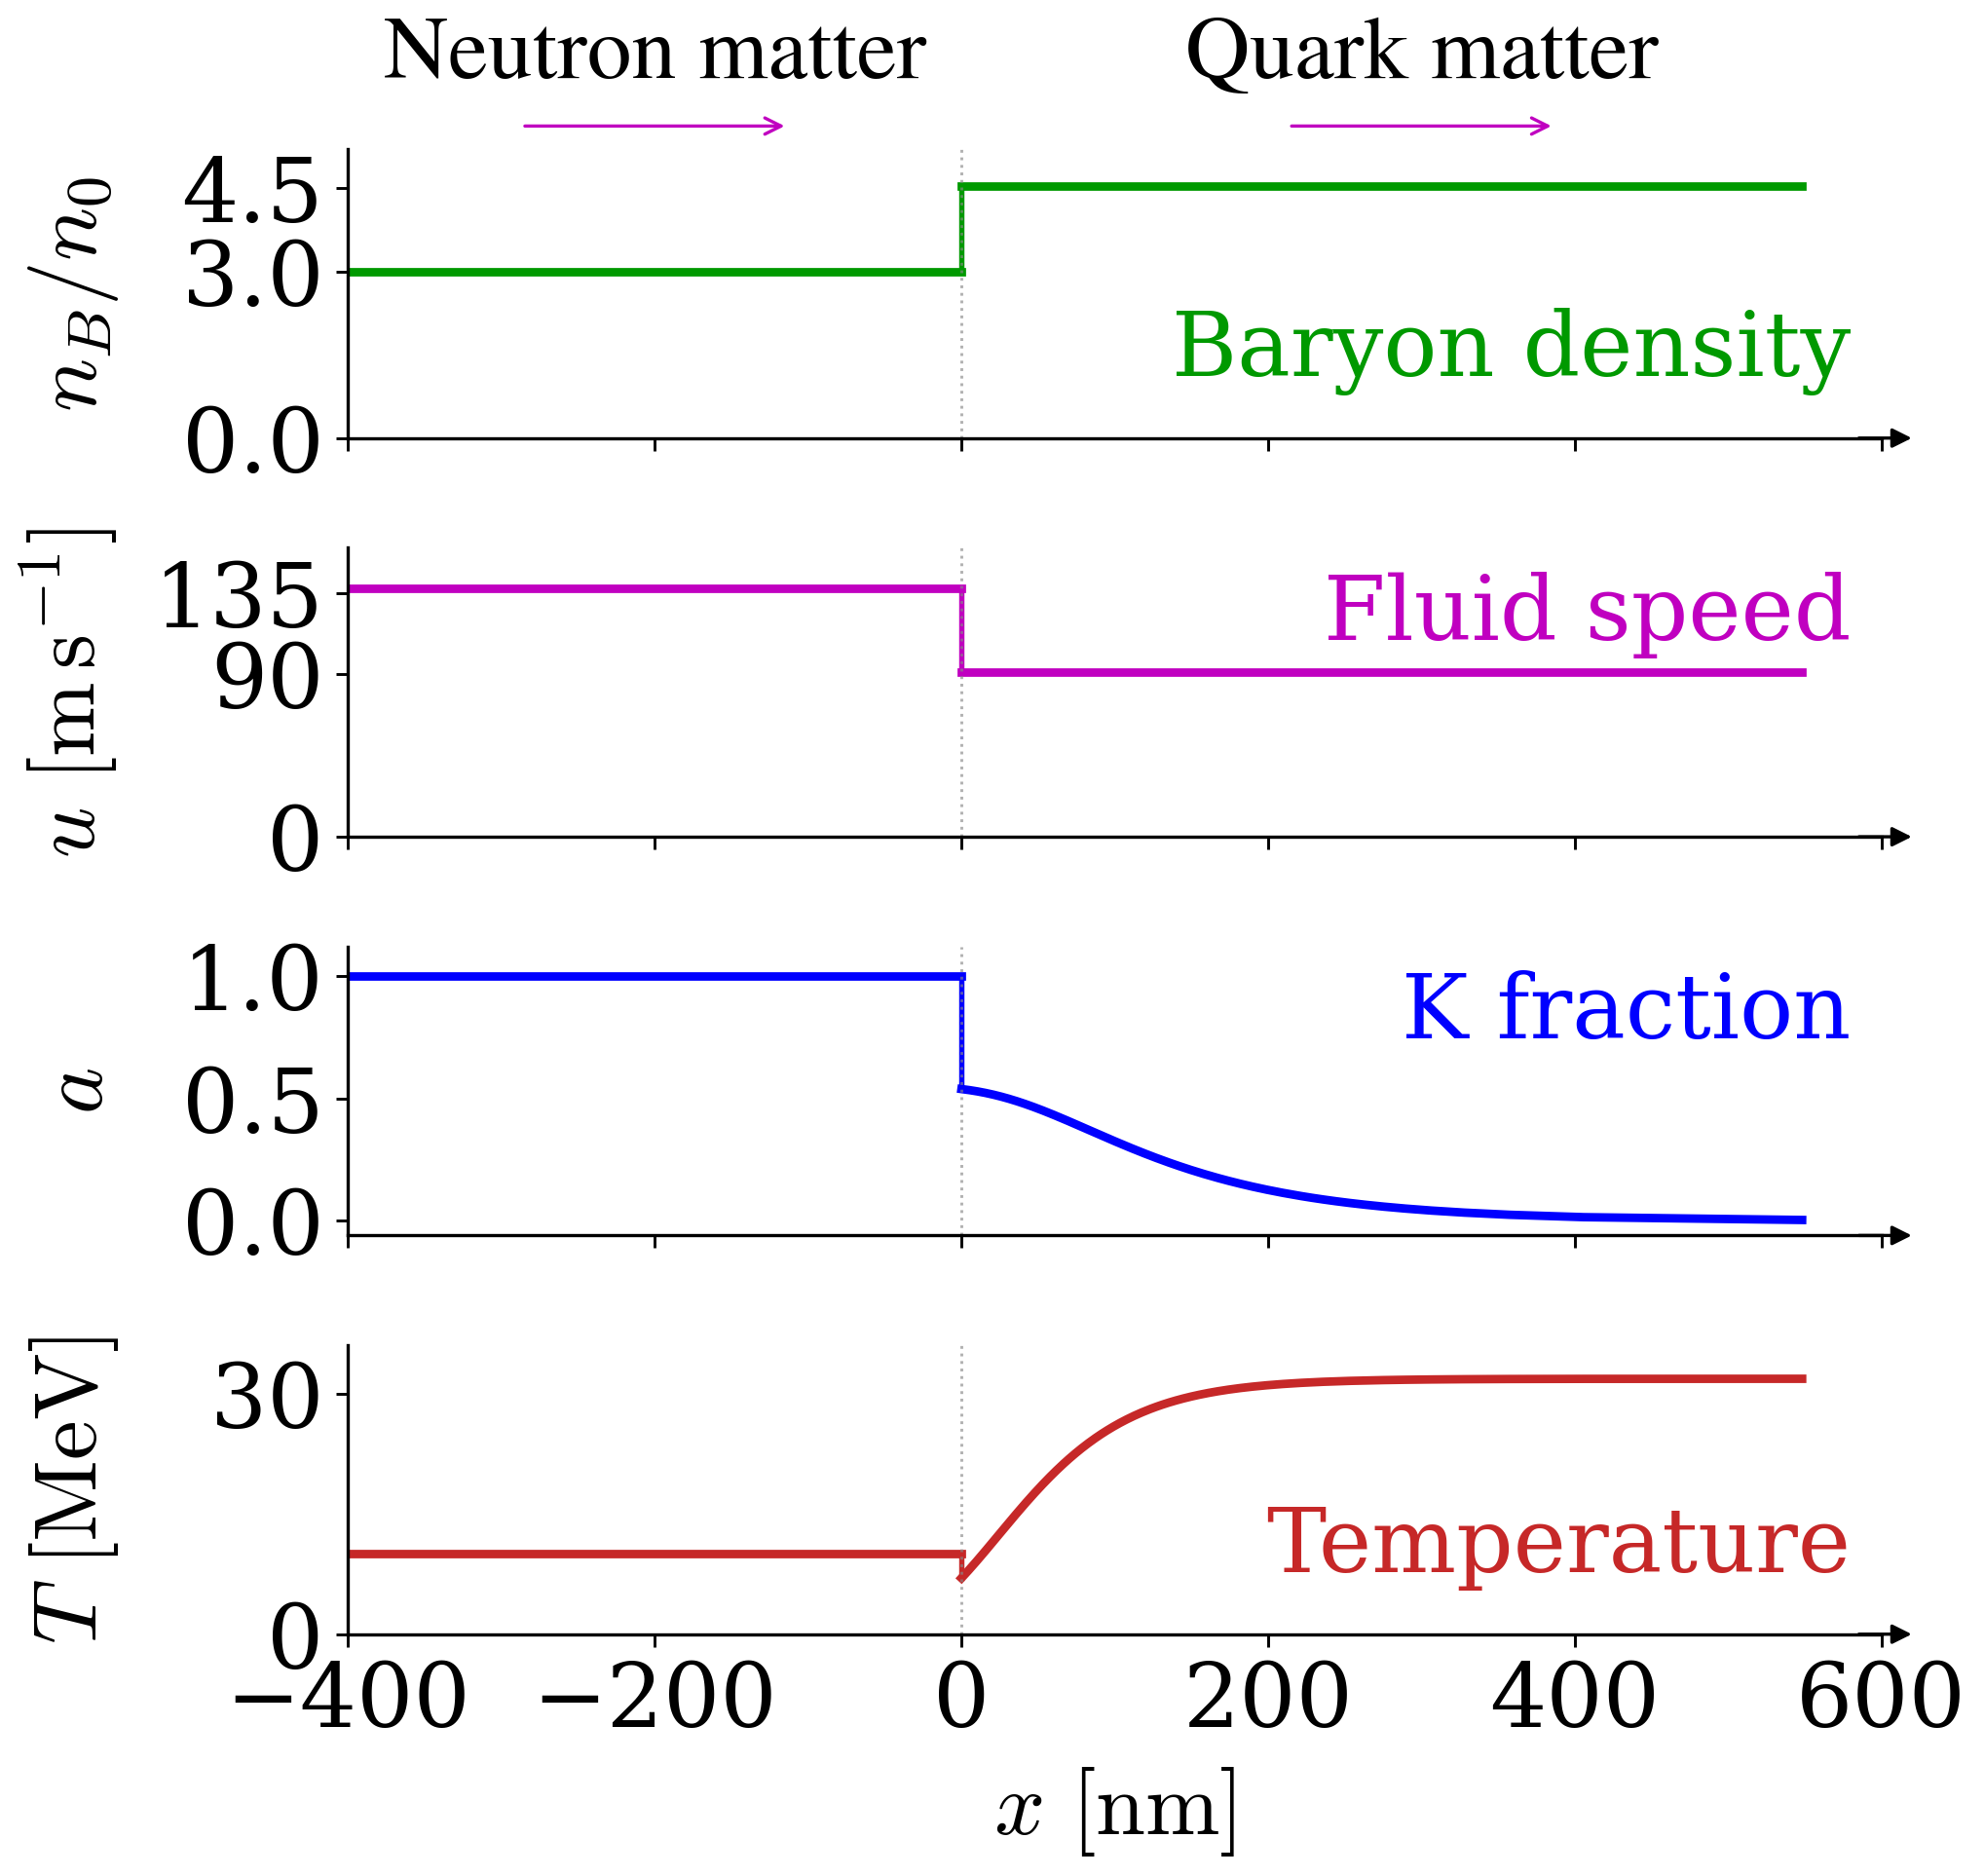

Saved numerical profile: local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv
Quark samples: 200; plotted through x = 548.22 nm (not infinity)
Interface a(0+) = 0.538; T(0-) = 10.00 MeV; T(0+) = 6.99 MeV
Last saved state: a = 0.003318; T = 31.82 MeV
Saved: Latex_writting/Hydrodynamical combustion/Plots/boundary_schematic_real.pdf


In [1]:
# Tunable plotting parameters
PROFILE_CSV = "local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/boundary_schematic_real.pdf"
OUTPUT_PNG = "local_analysis_results/All_Plots_new/adiabatic_boundary_profile.png"
FIGURE_SIZE = (6.4, 6.6)
FIGURE_DPI = 180
EXPORT_DPI = 300
FONT_FAMILY = "serif"
MATH_FONT_SET = "cm"
AXIS_LABEL_FONT_SIZE = 22
TICK_LABEL_FONT_SIZE = 22
ANNOTATION_FONT_SIZE = 22
PHASE_LABEL_FONT_SIZE = 22
PHASE_LABEL_FONT_FAMILY = "STIXGeneral"
LINE_WIDTH = 2.1
JUMP_LINE_WIDTH = 1.3
PROFILE_LINE_STYLE = "-"
AXIS_LINE_WIDTH = 0.8
AXIS_COLOR = "black"
INTERFACE_COLOR = "#888888"
INTERFACE_LINE_WIDTH = 0.7
INTERFACE_LINE_STYLE = ":"
INTERFACE_ALPHA = 0.65
PROFILE_COLORS = ("#009900", "#c000c0", "#0000ff", "#c62828")
PROFILE_FIELDS = ("nB", "u", "a", "T")
PANEL_LABELS = ("Baryon density", "Fluid speed", "K fraction", "Temperature")
Y_AXIS_LABELS = (r"$n_B/n_0$", r"$u\ [\mathrm{m\,s^{-1}}]$", r"$a$", r"$T\ [\mathrm{MeV}]$")
PANEL_LABEL_POSITIONS = ((0.98, 0.30), (0.98, 0.77), (0.98, 0.77), (0.98, 0.30))
Y_LIMITS = ((0.0, 5.2), (0.0, 160.0), (-0.06, 1.12), (0.0, 36.0))
Y_TICKS = ((0.0, 3.0, 4.5), (0.0, 90.0, 135.0), (0.0, 0.5, 1.0), (0.0, 30.0))
X_LIMITS_NM = (-400.0, 600.0)
X_TICKS_NM = (-400.0, -200.0, 0.0, 200.0, 400.0, 600.0)
X_AXIS_LABEL = r"$x\ [\mathrm{nm}]$"
TICK_DIRECTION = "out"
TICK_LENGTH = 3.0
TICK_WIDTH = 0.7
TICK_LABEL_PAD = 3.0
Y_AXIS_LABEL_PAD = 8.0
X_AXIS_LABEL_PAD = 5.0
PHASE_LABEL_Y = 1.18
PHASE_LABELS = ("Neutron matter", "Quark matter")
PHASE_LABEL_X_NM = (-200.0, 300.0)
FLOW_ARROW_COLOR = "#c000c0"
FLOW_ARROW_Y = 1.08
FLOW_ARROW_EXTENTS_NM = ((-290.0, -110.0), (210.0, 390.0))
FLOW_ARROW_STYLE = "->"
FLOW_ARROW_LINE_WIDTH = 0.8
FLOW_ARROW_SIZE = 10
X_ARROW_STYLE = "-|>"
X_ARROW_SIZE = 10
X_ARROW_START_FRACTION = 0.98
X_ARROW_END_FRACTION = 1.025
SUBPLOT_LEFT = 0.15
SUBPLOT_RIGHT = 0.97
SUBPLOT_BOTTOM = 0.10
SUBPLOT_TOP = 0.87
SUBPLOT_HSPACE = 0.38
SAVE_TRANSPARENT = False
EXPORT_BOUNDING_BOX = "tight"
EXPORT_PAD_INCHES = 0.06

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

# The legacy filename is retained for compatibility; the table contains T(0+) = 6.99 MeV.
data = np.genfromtxt(PROFILE_CSV, delimiter=",", names=True)
upstream_rows = data[~np.isfinite(data["D"])]
profile = data[np.isfinite(data["D"])]
profile = np.sort(profile, order="x")
if len(upstream_rows) != 1 or not np.all(np.diff(profile["x"]) > 0):
    raise ValueError("Expected one upstream state and an ordered numerical quark profile")
upstream = upstream_rows[0]

# Natural-unit conversion uses the same hbar*c as the saved calculation.
hbar_c_mev_fm = 197.326960
n0_mev3 = 0.16 * hbar_c_mev_fm**3
light_speed_m_s = 299792458.0
x_nm = profile["x"] * hbar_c_mev_fm * 1.0e-6
field_scales = (1.0 / n0_mev3, light_speed_m_s, 1.0, 1.0)
profile_lines = []
jump_lines = []

with mpl.rc_context({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONT_SET}):
    fig, axes = plt.subplots(len(PROFILE_FIELDS), 1, sharex=True,
                             figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
    fig.subplots_adjust(left=SUBPLOT_LEFT, right=SUBPLOT_RIGHT,
                        bottom=SUBPLOT_BOTTOM, top=SUBPLOT_TOP,
                        hspace=SUBPLOT_HSPACE)
    for index, (axis, field, scale, color) in enumerate(
        zip(axes, PROFILE_FIELDS, field_scales, PROFILE_COLORS)
    ):
        # Extend only the homogeneous upstream state; preserve every saved downstream sample.
        axis.plot([X_LIMITS_NM[0], 0.0], [upstream[field] * scale] * 2,
                  color=color, linewidth=LINE_WIDTH, linestyle=PROFILE_LINE_STYLE)
        jump, = axis.plot([0.0, 0.0], [upstream[field] * scale, profile[field][0] * scale],
                          color=color, linewidth=JUMP_LINE_WIDTH, linestyle=PROFILE_LINE_STYLE)
        line, = axis.plot(x_nm, profile[field] * scale, color=color,
                          linewidth=LINE_WIDTH, linestyle=PROFILE_LINE_STYLE)
        jump_lines.append(jump)
        profile_lines.append(line)
        axis.axvline(0.0, color=INTERFACE_COLOR, linewidth=INTERFACE_LINE_WIDTH,
                     linestyle=INTERFACE_LINE_STYLE, alpha=INTERFACE_ALPHA)
        axis.set_xlim(*X_LIMITS_NM)
        axis.set_ylim(*Y_LIMITS[index])
        axis.set_xticks(X_TICKS_NM)
        axis.set_yticks(Y_TICKS[index])
        axis.set_ylabel(Y_AXIS_LABELS[index], fontsize=AXIS_LABEL_FONT_SIZE,
                        labelpad=Y_AXIS_LABEL_PAD)
        axis.text(*PANEL_LABEL_POSITIONS[index], PANEL_LABELS[index],
                  transform=axis.transAxes, ha="right", va="center",
                  fontsize=ANNOTATION_FONT_SIZE, color=color)
        axis.spines[["top", "right"]].set_visible(False)
        for side in ("left", "bottom"):
            axis.spines[side].set_linewidth(AXIS_LINE_WIDTH)
            axis.spines[side].set_color(AXIS_COLOR)
        axis.tick_params(axis="both", direction=TICK_DIRECTION, length=TICK_LENGTH,
                         width=TICK_WIDTH, pad=TICK_LABEL_PAD,
                         labelsize=TICK_LABEL_FONT_SIZE, top=False, right=False,
                         labelbottom=index == len(axes) - 1)
        axis.annotate("", (X_ARROW_END_FRACTION, 0.0), (X_ARROW_START_FRACTION, 0.0),
                      xycoords="axes fraction", annotation_clip=False,
                      arrowprops={"arrowstyle": X_ARROW_STYLE, "color": AXIS_COLOR,
                                  "lw": AXIS_LINE_WIDTH, "mutation_scale": X_ARROW_SIZE})

    for position, label in zip(PHASE_LABEL_X_NM, PHASE_LABELS):
        axes[0].text(position, PHASE_LABEL_Y, label,
                     transform=axes[0].get_xaxis_transform(), ha="center", va="bottom",
                     fontsize=PHASE_LABEL_FONT_SIZE,
                     fontfamily=PHASE_LABEL_FONT_FAMILY, clip_on=False)
    for start, stop in FLOW_ARROW_EXTENTS_NM:
        axes[0].annotate("", (stop, FLOW_ARROW_Y), (start, FLOW_ARROW_Y),
                         xycoords=axes[0].get_xaxis_transform(), annotation_clip=False,
                         arrowprops={"arrowstyle": FLOW_ARROW_STYLE,
                                     "color": FLOW_ARROW_COLOR,
                                     "lw": FLOW_ARROW_LINE_WIDTH,
                                     "mutation_scale": FLOW_ARROW_SIZE})
    axes[-1].set_xlabel(X_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE,
                        labelpad=X_AXIS_LABEL_PAD)
    fig.align_ylabels(axes)
    for output in (OUTPUT_PDF, OUTPUT_PNG):
        Path(output).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output, dpi=EXPORT_DPI, bbox_inches=EXPORT_BOUNDING_BOX,
                    pad_inches=EXPORT_PAD_INCHES, transparent=SAVE_TRANSPARENT)
    plt.show()

print(f"Saved numerical profile: {PROFILE_CSV}")
print(f"Quark samples: {len(profile)}; plotted through x = {x_nm[-1]:.2f} nm (not infinity)")
print(f"Interface a(0+) = {profile['a'][0]:.3f}; T(0-) = {upstream['T']:.2f} MeV; T(0+) = {profile['T'][0]:.2f} MeV")
print(f"Last saved state: a = {profile['a'][-1]:.6f}; T = {profile['T'][-1]:.2f} MeV")
print(f"Saved: {OUTPUT_PDF}")


# Constant-pressure trajectory in the $(a,T)$ plane

This figure compares an energy-conserving numerical front profile with the quarter-ellipse obtained by treating $P$, $\mu_B$, and $n_B$ as constant through the conversion layer. The plotting style follows the older $(\mu_B,\mu_K)$-plane figure in `All_Plots.ipynb`.

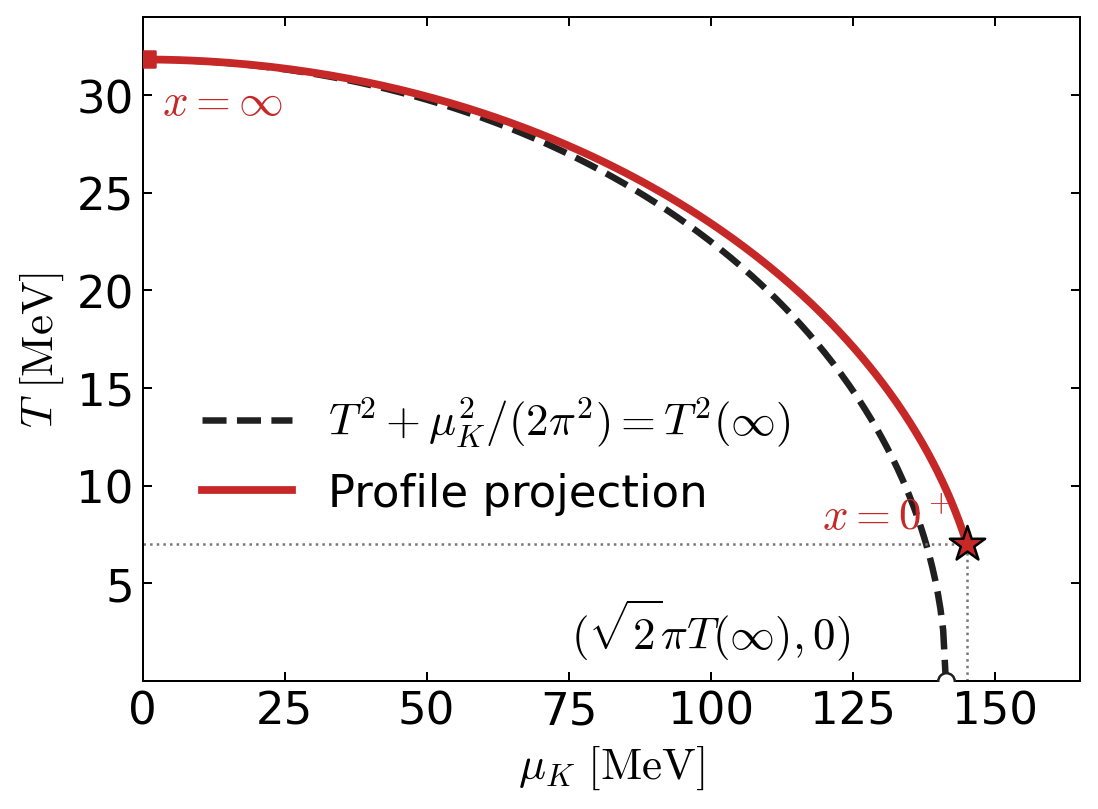

Profile: local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv
T_Q = 31.823486 MeV
muK endpoint = 141.388023 MeV
Interface: muK = 145.109635 MeV, T = 6.990575 MeV
Maximum |T_profile - T_isobar| = 9.782804 MeV
Saved: Latex_writting/Hydrodynamical combustion/Plots/T_muK_constant_pressure.pdf


In [6]:
# Tunable plotting parameters
PROFILE_CSV = "local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/T_muK_constant_pressure.pdf"
FIGURE_SIZE = (6.2, 4.6)
FIGURE_DPI = 180
EXPORT_DPI = 300
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
LEGEND_FONT_SIZE = 18
ANNOTATION_FONT_SIZE = 18
LINE_WIDTH = 2.6
PROFILE_LINE_WIDTH = 3.1
PROJECTION_LINE_WIDTH = 1.0
MARKER_SIZE = 80
ENDPOINT_MARKER_SCALE = 0.55
MARKER_ZORDER = 5
QSTAR_MARKER_STYLE = "*"
QSTAR_MARKER_SIZE = 220
QSTAR_EDGE_COLOR = "black"
QSTAR_EDGE_LINE_WIDTH = 1.0
DOWNSTREAM_MARKER_STYLE = "s"
ENDPOINT_FACE_COLOR = "white"
PROFILE_COLOR = "#c62828"
ELLIPSE_COLOR = "#202020"
PROJECTION_COLOR = "#777777"
ELLIPSE_LINE_STYLE = "--"
PROJECTION_LINE_STYLE = ":"
GRID_POINTS = 300
X_LIMITS = (0.0, 165.0)
Y_LIMITS = (0.0, 34.0)
X_TICKS = (0.0, 25.0, 50.0, 75.0, 100.0, 125.0, 150.0)
Y_TICKS = (0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0)
TICK_DIRECTION = "in"
SHOW_TOP_TICKS = True
SHOW_RIGHT_TICKS = True
LEGEND_LOCATION = "center left"
LEGEND_FRAME = False
LEGEND_BBOX_TO_ANCHOR = (0.02, 0.34)
ELLIPSE_LABEL = r"$T^2+\mu_K^2/(2\pi^2)=T^2(\infty)$"
PROFILE_LABEL = "Profile projection"
DOWNSTREAM_ENDPOINT_LABEL = r"$x = \infty$"
INTERFACE_ENDPOINT_LABEL = r"$x = 0^+$"
X_AXIS_LABEL = r"$\mu_K\ \mathrm{[MeV]}$"
Y_AXIS_LABEL = r"$T\ \mathrm{[MeV]}$"
QBAR_LABEL_OFFSET = (6, -22)
QSTAR_LABEL_OFFSET = (-58, 6)
ENDPOINT_LABEL_OFFSET = (-150, 13)
SHOW_GRID = False
GRID_ALPHA = 0.15
SHOW_QSTAR_PROJECTIONS = True
SHOW_ENDPOINT_LABEL = True
SAVE_TRANSPARENT = False
BOUNDING_BOX = "tight"

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

profile_path = Path(PROFILE_CSV)
output_pdf_path = Path(OUTPUT_PDF)
output_pdf_path.parent.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(profile_path)
profile = data[data["D"].notna()].copy()
profile = profile.sort_values("muK")

# The first row after sorting is the equilibrated downstream endpoint.
qbar = profile.iloc[0]
qstar = profile.iloc[-1]
T_Q = float(qbar["T"])

# The quadratic constant-pressure relation is T^2 + muK^2/(2 pi^2) = T_Q^2.
muK_endpoint = np.sqrt(2.0) * np.pi * T_Q
muK_isobar = np.linspace(0.0, muK_endpoint, GRID_POINTS)
T_isobar = np.sqrt(np.maximum(T_Q**2 - muK_isobar**2 / (2.0 * np.pi**2), 0.0))

# Evaluate the same approximation on the numerical profile for a diagnostic.
profile_muK = profile["muK"].to_numpy(dtype=float)
T_profile_isobar = np.sqrt(
    np.maximum(T_Q**2 - profile_muK**2 / (2.0 * np.pi**2), 0.0)
)
max_temperature_difference = np.max(np.abs(profile["T"].to_numpy() - T_profile_isobar))

mpl.rcParams.update(
    {
        "mathtext.fontset": "cm",
        "mathtext.rm": "serif",
        "mathtext.it": "serif:italic",
        "mathtext.bf": "serif:bold",
    }
)

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
ax.plot(
    muK_isobar,
    T_isobar,
    color=ELLIPSE_COLOR,
    linewidth=LINE_WIDTH,
    linestyle=ELLIPSE_LINE_STYLE,
    label=ELLIPSE_LABEL,
)
ax.plot(
    profile["muK"],
    profile["T"],
    color=PROFILE_COLOR,
    linewidth=PROFILE_LINE_WIDTH,
    label=PROFILE_LABEL,
)

ax.scatter(
    qbar["muK"], qbar["T"],
    s=ENDPOINT_MARKER_SCALE * MARKER_SIZE,
    marker=DOWNSTREAM_MARKER_STYLE,
    color=PROFILE_COLOR,
    zorder=MARKER_ZORDER,
)
ax.scatter(
    qstar["muK"], qstar["T"],
    s=QSTAR_MARKER_SIZE,
    marker=QSTAR_MARKER_STYLE,
    color=PROFILE_COLOR,
    edgecolor=QSTAR_EDGE_COLOR,
    linewidths=QSTAR_EDGE_LINE_WIDTH,
    zorder=MARKER_ZORDER,
)
ax.scatter(
    muK_endpoint, 0.0,
    s=ENDPOINT_MARKER_SCALE * MARKER_SIZE,
    facecolor=ENDPOINT_FACE_COLOR,
    edgecolor=ELLIPSE_COLOR,
    zorder=MARKER_ZORDER,
)

ax.annotate(
    DOWNSTREAM_ENDPOINT_LABEL,
    (qbar["muK"], qbar["T"]),
    xytext=QBAR_LABEL_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=PROFILE_COLOR,
)
ax.annotate(
    INTERFACE_ENDPOINT_LABEL,
    (qstar["muK"], qstar["T"]),
    xytext=QSTAR_LABEL_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=PROFILE_COLOR,
)
if SHOW_ENDPOINT_LABEL:
    ax.annotate(
        r"$(\sqrt{2}\pi T(\infty),0)$",
        (muK_endpoint, 0.0),
        xytext=ENDPOINT_LABEL_OFFSET,
        textcoords="offset points",
        fontsize=ANNOTATION_FONT_SIZE,
    )

if SHOW_QSTAR_PROJECTIONS:
    ax.plot(
        [qstar["muK"], qstar["muK"]],
        [0.0, qstar["T"]],
        color=PROJECTION_COLOR,
        linewidth=PROJECTION_LINE_WIDTH,
        linestyle=PROJECTION_LINE_STYLE,
    )
    ax.plot(
        [0.0, qstar["muK"]],
        [qstar["T"], qstar["T"]],
        color=PROJECTION_COLOR,
        linewidth=PROJECTION_LINE_WIDTH,
        linestyle=PROJECTION_LINE_STYLE,
    )

ax.set_xlabel(X_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(Y_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_xticks(X_TICKS)
ax.set_yticks(Y_TICKS)
ax.set_yticklabels(["" if np.isclose(y, 0.0) else f"{y:g}" for y in Y_TICKS])
ax.tick_params(
    which="both",
    direction=TICK_DIRECTION,
    top=SHOW_TOP_TICKS,
    right=SHOW_RIGHT_TICKS,
    labelsize=TICK_LABEL_FONT_SIZE,
)
if SHOW_GRID:
    ax.grid(alpha=GRID_ALPHA)
ax.legend(
    frameon=LEGEND_FRAME,
    fontsize=LEGEND_FONT_SIZE,
    loc=LEGEND_LOCATION,
    bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR,
)

fig.tight_layout()
fig.savefig(
    output_pdf_path,
    dpi=EXPORT_DPI,
    bbox_inches=BOUNDING_BOX,
    transparent=SAVE_TRANSPARENT,
)
plt.show()

print(f"Profile: {profile_path}")
print(f"T_Q = {T_Q:.6f} MeV")
print(f"muK endpoint = {muK_endpoint:.6f} MeV")
print(f"Interface: muK = {qstar['muK']:.6f} MeV, T = {qstar['T']:.6f} MeV")
print(f"Maximum |T_profile - T_isobar| = {max_temperature_difference:.6f} MeV")
print(f"Saved: {output_pdf_path}")


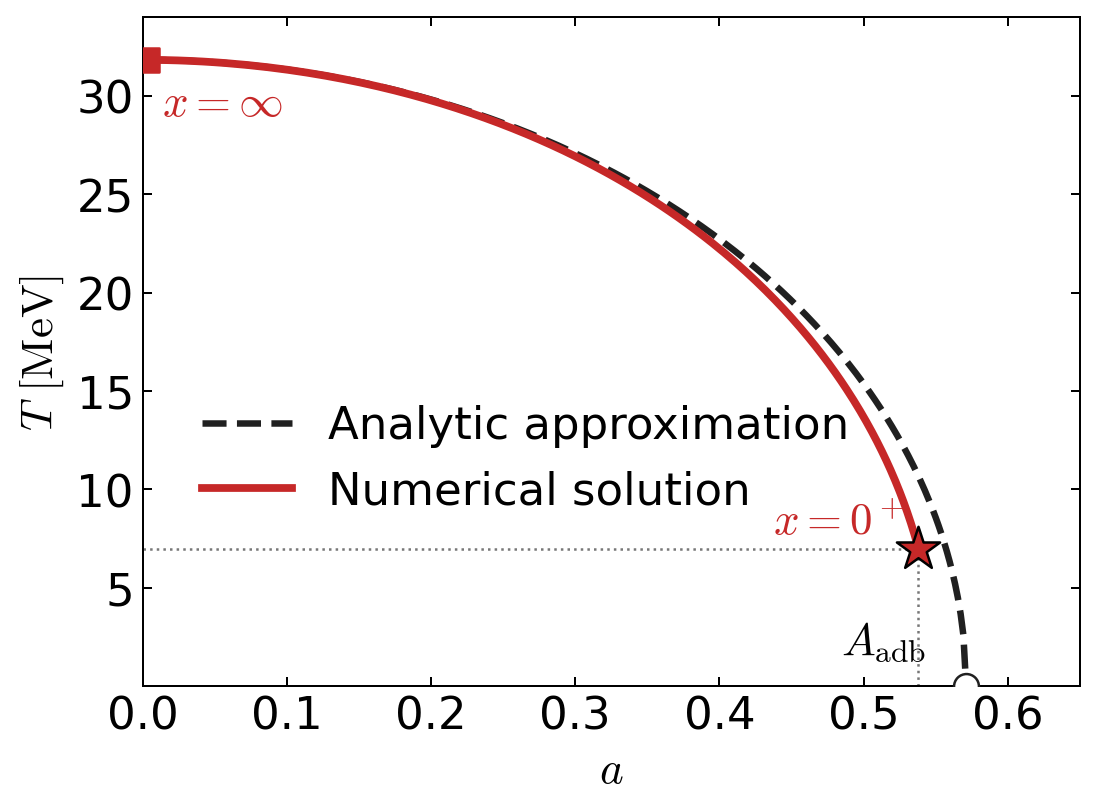

Profile: local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv
T_Q = 31.823486 MeV
muB_Q = 1114.168999 MeV
A endpoint = 0.571050
Interface: a = 0.538000, T = 6.990575 MeV
Maximum |T_profile - T_isobar| = 3.678686 MeV
Saved: Latex_writting/Hydrodynamical combustion/Plots/T_a_constant_pressure.pdf


In [2]:
# Tunable plotting parameters
PROFILE_CSV = "local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/T_a_constant_pressure.pdf"
FIGURE_SIZE = (6.2, 4.6)
FIGURE_DPI = 180
EXPORT_DPI = 300
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
LEGEND_FONT_SIZE = 18
ANNOTATION_FONT_SIZE = 18
LINE_WIDTH = 2.6
PROFILE_LINE_WIDTH = 3.1
PROJECTION_LINE_WIDTH = 1.0
MARKER_SIZE = 180
ENDPOINT_MARKER_SCALE = 0.55
MARKER_ZORDER = 5
QSTAR_MARKER_STYLE = "*"
QSTAR_MARKER_SIZE = 330
QSTAR_EDGE_COLOR = "black"
QSTAR_EDGE_LINE_WIDTH = 1.0
DOWNSTREAM_MARKER_STYLE = "s"
ENDPOINT_FACE_COLOR = "white"
PROFILE_COLOR = "#c62828"
ELLIPSE_COLOR = "#202020"
PROJECTION_COLOR = "#777777"
ELLIPSE_LINE_STYLE = "--"
PROJECTION_LINE_STYLE = ":"
GRID_POINTS = 300
X_LIMITS = (0.0, 0.65)
Y_LIMITS = (0.0, 34.0)
X_TICKS = (0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6)
Y_TICKS = (0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0)
TICK_DIRECTION = "in"
SHOW_TOP_TICKS = True
SHOW_RIGHT_TICKS = True
LEGEND_LOCATION = "center left"
LEGEND_FRAME = False
LEGEND_BBOX_TO_ANCHOR = (0.02, 0.34)
ELLIPSE_LABEL = "Analytic approximation"
PROFILE_LABEL = "Numerical solution"
DOWNSTREAM_ENDPOINT_LABEL = r"$x = \infty$"
INTERFACE_ENDPOINT_LABEL = r"$x = 0^+$"
X_AXIS_LABEL = r"$a$"
Y_AXIS_LABEL = r"$T\ \mathrm{[MeV]}$"
QBAR_LABEL_OFFSET = (6, -22)
QSTAR_LABEL_OFFSET = (-58, 6)
ENDPOINT_LABEL_OFFSET = (-50, 13)
SHOW_GRID = False
GRID_ALPHA = 0.15
SHOW_QSTAR_PROJECTIONS = True
SHOW_ENDPOINT_LABEL = True
ENDPOINT_LABEL = r"$A_{\rm adb}$"
SAVE_TRANSPARENT = False
BOUNDING_BOX = "tight"

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

profile_path = Path(PROFILE_CSV)
output_pdf_path = Path(OUTPUT_PDF)
output_pdf_path.parent.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(profile_path)
profile = data[data["D"].notna()].copy()
profile = profile.sort_values("a")

# The first row after sorting is the equilibrated downstream endpoint.
qbar = profile.iloc[0]
qstar = profile.iloc[-1]
T_Q = float(qbar["T"])
muB_Q = float(qbar["muB"])

# A is the zero-temperature endpoint of the isobar in the (a,T) plane:
# A = 9*pi*T_Q/(sqrt(2)*muB_Q), so that T(a)^2/T_Q^2 + (a/A)^2 = 1.
A_endpoint = (9.0 * np.pi / np.sqrt(2.0)) * (T_Q / muB_Q)
a_isobar = np.linspace(0.0, A_endpoint, GRID_POINTS)
T_isobar = T_Q * np.sqrt(np.maximum(1.0 - (a_isobar / A_endpoint) ** 2, 0.0))

# Evaluate the same approximation on the numerical profile for a diagnostic.
profile_a = profile["a"].to_numpy(dtype=float)
T_profile_isobar = T_Q * np.sqrt(
    np.maximum(1.0 - (profile_a / A_endpoint) ** 2, 0.0)
)
max_temperature_difference = np.max(np.abs(profile["T"].to_numpy() - T_profile_isobar))

mpl.rcParams.update(
    {
        "mathtext.fontset": "cm",
        "mathtext.rm": "serif",
        "mathtext.it": "serif:italic",
        "mathtext.bf": "serif:bold",
    }
)

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
ax.plot(
    a_isobar,
    T_isobar,
    color=ELLIPSE_COLOR,
    linewidth=LINE_WIDTH,
    linestyle=ELLIPSE_LINE_STYLE,
    label=ELLIPSE_LABEL,
)
ax.plot(
    profile["a"],
    profile["T"],
    color=PROFILE_COLOR,
    linewidth=PROFILE_LINE_WIDTH,
    label=PROFILE_LABEL,
)

ax.scatter(
    qbar["a"], qbar["T"],
    s=ENDPOINT_MARKER_SCALE * MARKER_SIZE,
    marker=DOWNSTREAM_MARKER_STYLE,
    color=PROFILE_COLOR,
    zorder=MARKER_ZORDER,
)
ax.scatter(
    qstar["a"], qstar["T"],
    s=QSTAR_MARKER_SIZE,
    marker=QSTAR_MARKER_STYLE,
    color=PROFILE_COLOR,
    edgecolor=QSTAR_EDGE_COLOR,
    linewidths=QSTAR_EDGE_LINE_WIDTH,
    zorder=MARKER_ZORDER,
)
ax.scatter(
    A_endpoint, 0.0,
    s=ENDPOINT_MARKER_SCALE * MARKER_SIZE,
    facecolor=ENDPOINT_FACE_COLOR,
    edgecolor=ELLIPSE_COLOR,
    zorder=MARKER_ZORDER,
)

ax.annotate(
    DOWNSTREAM_ENDPOINT_LABEL,
    (qbar["a"], qbar["T"]),
    xytext=QBAR_LABEL_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=PROFILE_COLOR,
)
ax.annotate(
    INTERFACE_ENDPOINT_LABEL,
    (qstar["a"], qstar["T"]),
    xytext=QSTAR_LABEL_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=PROFILE_COLOR,
)
if SHOW_ENDPOINT_LABEL:
    ax.annotate(
        ENDPOINT_LABEL,
        (A_endpoint, 0.0),
        xytext=ENDPOINT_LABEL_OFFSET,
        textcoords="offset points",
        fontsize=ANNOTATION_FONT_SIZE,
    )

if SHOW_QSTAR_PROJECTIONS:
    ax.plot(
        [qstar["a"], qstar["a"]],
        [0.0, qstar["T"]],
        color=PROJECTION_COLOR,
        linewidth=PROJECTION_LINE_WIDTH,
        linestyle=PROJECTION_LINE_STYLE,
    )
    ax.plot(
        [0.0, qstar["a"]],
        [qstar["T"], qstar["T"]],
        color=PROJECTION_COLOR,
        linewidth=PROJECTION_LINE_WIDTH,
        linestyle=PROJECTION_LINE_STYLE,
    )

ax.set_xlabel(X_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(Y_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_xticks(X_TICKS)
ax.set_yticks(Y_TICKS)
ax.set_yticklabels(["" if np.isclose(y, 0.0) else f"{y:g}" for y in Y_TICKS])
ax.tick_params(
    which="both",
    direction=TICK_DIRECTION,
    top=SHOW_TOP_TICKS,
    right=SHOW_RIGHT_TICKS,
    labelsize=TICK_LABEL_FONT_SIZE,
)
if SHOW_GRID:
    ax.grid(alpha=GRID_ALPHA)
ax.legend(
    frameon=LEGEND_FRAME,
    fontsize=LEGEND_FONT_SIZE,
    loc=LEGEND_LOCATION,
    bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR,
)

fig.tight_layout()
fig.savefig(
    output_pdf_path,
    dpi=EXPORT_DPI,
    bbox_inches=BOUNDING_BOX,
    transparent=SAVE_TRANSPARENT,
)
plt.show()

print(f"Profile: {profile_path}")
print(f"T_Q = {T_Q:.6f} MeV")
print(f"muB_Q = {muB_Q:.6f} MeV")
print(f"A endpoint = {A_endpoint:.6f}")
print(f"Interface: a = {qstar['a']:.6f}, T = {qstar['T']:.6f} MeV")
print(f"Maximum |T_profile - T_isobar| = {max_temperature_difference:.6f} MeV")
print(f"Saved: {output_pdf_path}")


For massless quarks at fixed $\mu_B=3\mu_q$, the pressure difference from the equilibrated endpoint is, to quadratic order in $\mu_K$ and $T$, proportional to

$$
\frac{3\mu_q^2}{4\pi^2}\mu_K^2+\frac{3\mu_q^2}{2}(T^2-T_Q^2).
$$

Constant pressure therefore gives $T^2=T_Q^2-\mu_K^2/(2\pi^2)$. Using $a\simeq3\mu_K/(2\mu_q)$ and defining the cold endpoint by $T(A)=0$ gives the plotted quarter ellipse.

# Isothermal trajectory in the $(\mu_B,\mu_K)$ plane

The first code cell performs the expensive live isothermal BVP solve, reconstructs the numerical profile, samples a reusable quark-matter isobar, and saves the numerical data. Run it once per physical input state. The following visualization cell contains all plotting controls and can be rerun independently while the calculated variables remain in the notebook kernel.

The red arrows follow the solved profile from $x=0^+$ to $x=\infty$; the green dashed arc marks the discontinuous crossing from the upstream state at $x=0^-$ to the interface state.

In [14]:
# Heavy isothermal calculation parameters
PROFILE_DATA_PATH = "local_analysis_results/All_Plots_new/isothermal_numerical_T10_nB3n0_B189p1566.npz"
PLOT_DATA_PATH = "local_analysis_results/All_Plots_new/isothermal_mu_plane_plot_data.npz"
ISOBAR_MU_K_LIMIT_MEV = 90.0
ISOBAR_POINTS = 420

# Isothermal run parameters
T_0MINUS_MEV = 10.0
NB_0MINUS_OVER_N0 = 3.0
B_ONE_FORTH_MEV = 189.1566
MS_MEV = 0.0
NM_TYPE = "PNM"
TAIL_EPS = 1.0e-3
N_MESH = 300
TOL_BVP = 1.0e-4
MAX_NODES = 50000
ISOBAR_ROOT_BRACKET_MEV = (100.0, 3000.0)
ROOT_XTOL_MEV = 1.0e-10
ROOT_RTOL = 1.0e-12

from pathlib import Path

import numpy as np
from scipy.optimize import root_scalar

from RMFsolver import constants as const
from RMFsolver import phase_velocity as pv

profile_data_path = Path(PROFILE_DATA_PATH)
profile_data_path.parent.mkdir(parents=True, exist_ok=True)

# Invalidate any payload left by an older calculation before starting.
ISOTHERMAL_MU_PLANE_DATA = None

n0 = float(const.NuclearDensity_nucleons_MeV3)
nB_0minus = NB_0MINUS_OVER_N0 * n0
profile_result = pv.solve_front_isothermal(
    T_0MINUS_MEV,
    nB_0minus,
    B_ONE_FORTH_MEV,
    a_0plus=np.nan,
    ms=MS_MEV,
    NM_type=NM_TYPE,
    tail_eps=TAIL_EPS,
    n_mesh=N_MESH,
    tol_bvp=TOL_BVP,
    max_nodes=MAX_NODES,
    return_profile=True,
    verb=False,
)
if not profile_result.get("success", False):
    raise RuntimeError(profile_result.get("message", "Isothermal profile solve failed"))
if profile_result.get("a_0plus_source") != "maximum":
    raise RuntimeError("The isothermal run did not use the maximum interface composition")

muB_0minus = float(
    pv.muB_from_nB_physical(
        nB_0minus,
        T_0MINUS_MEV,
        NM_type=NM_TYPE,
        auto_expand=True,
    )
)
muB_profile = np.append(
    np.asarray(profile_result["muB"], dtype=float),
    float(profile_result["muB_inf"]),
)
muK_profile = np.append(
    np.asarray(profile_result["muK"], dtype=float),
    float(profile_result["muK_inf"]),
)
x_profile = np.append(
    np.asarray(profile_result["x"], dtype=float),
    np.inf,
)

np.savez_compressed(
    profile_data_path,
    x=x_profile,
    muB=muB_profile,
    muK=muK_profile,
    muB_0minus=muB_0minus,
    muB_0plus=float(profile_result["muB_0plus"]),
    muK_0plus=float(profile_result["muK_0plus"]),
    muB_inf=float(profile_result["muB_inf"]),
    muK_inf=float(profile_result["muK_inf"]),
    a_0plus=float(profile_result["a_0plus"]),
    u_0minus=float(profile_result["u_0minus"]),
    T_0minus=T_0MINUS_MEV,
    nB_0minus=nB_0minus,
    B_one_forth=B_ONE_FORTH_MEV,
)

muK_isobar = np.linspace(
    -ISOBAR_MU_K_LIMIT_MEV,
    ISOBAR_MU_K_LIMIT_MEV,
    ISOBAR_POINTS,
)
muB_isobar = np.empty_like(muK_isobar)
for index, muK_value in enumerate(muK_isobar):
    def pressure_residual(muB_value):
        return (
            pv.PQM(
                muB_value,
                muK_value,
                B_ONE_FORTH_MEV,
                T_0MINUS_MEV,
                ms=MS_MEV,
                upB=5000,
            )
            - profile_result["P_0minus"]
        )

    muB_isobar[index] = root_scalar(
        pressure_residual,
        bracket=ISOBAR_ROOT_BRACKET_MEV,
        method="brentq",
        xtol=ROOT_XTOL_MEV,
        rtol=ROOT_RTOL,
    ).root

ISOTHERMAL_MU_PLANE_DATA = {
    "muB_isobar": np.asarray(muB_isobar, dtype=float).copy(),
    "muK_isobar": np.asarray(muK_isobar, dtype=float).copy(),
    "muB_profile": np.asarray(muB_profile, dtype=float).copy(),
    "muK_profile": np.asarray(muK_profile, dtype=float).copy(),
    "muB_0minus": float(muB_0minus),
    "muB_0plus": float(profile_result["muB_0plus"]),
    "muK_0plus": float(profile_result["muK_0plus"]),
    "muB_inf": float(profile_result["muB_inf"]),
    "muK_inf": float(profile_result["muK_inf"]),
    "T_0minus": float(T_0MINUS_MEV),
    "nB_0minus_over_n0": float(NB_0MINUS_OVER_N0),
    "B_one_forth": float(B_ONE_FORTH_MEV),
}

np.savez_compressed(PLOT_DATA_PATH, **ISOTHERMAL_MU_PLANE_DATA)

print(f"isothermal solve success = {profile_result['success']}")
print(f"a(0+)_max = {profile_result['a_0plus']:.9f}")
print(f"u(0-) = {profile_result['u_0minus'] * const.c:.6f} m/s")
print(f"muB(0-) = {muB_0minus:.9f} MeV")
print(f"muB(0+) = {profile_result['muB_0plus']:.9f} MeV")
print(f"muK(0+) = {profile_result['muK_0plus']:.9f} MeV")
print(f"muB(inf) = {profile_result['muB_inf']:.9f} MeV")
print(f"saved profile data: {profile_data_path}")


isothermal solve success = True
a(0+)_max = 0.146108316
u(0-) = 2148.421074 m/s
muB(0-) = 1190.639019686 MeV
muB(0+) = 1184.962328247 MeV
muK(0+) = 38.852623864 MeV
muB(inf) = 1187.805251778 MeV
saved profile data: local_analysis_results/All_Plots_new/isothermal_numerical_T10_nB3n0_B189p1566.npz


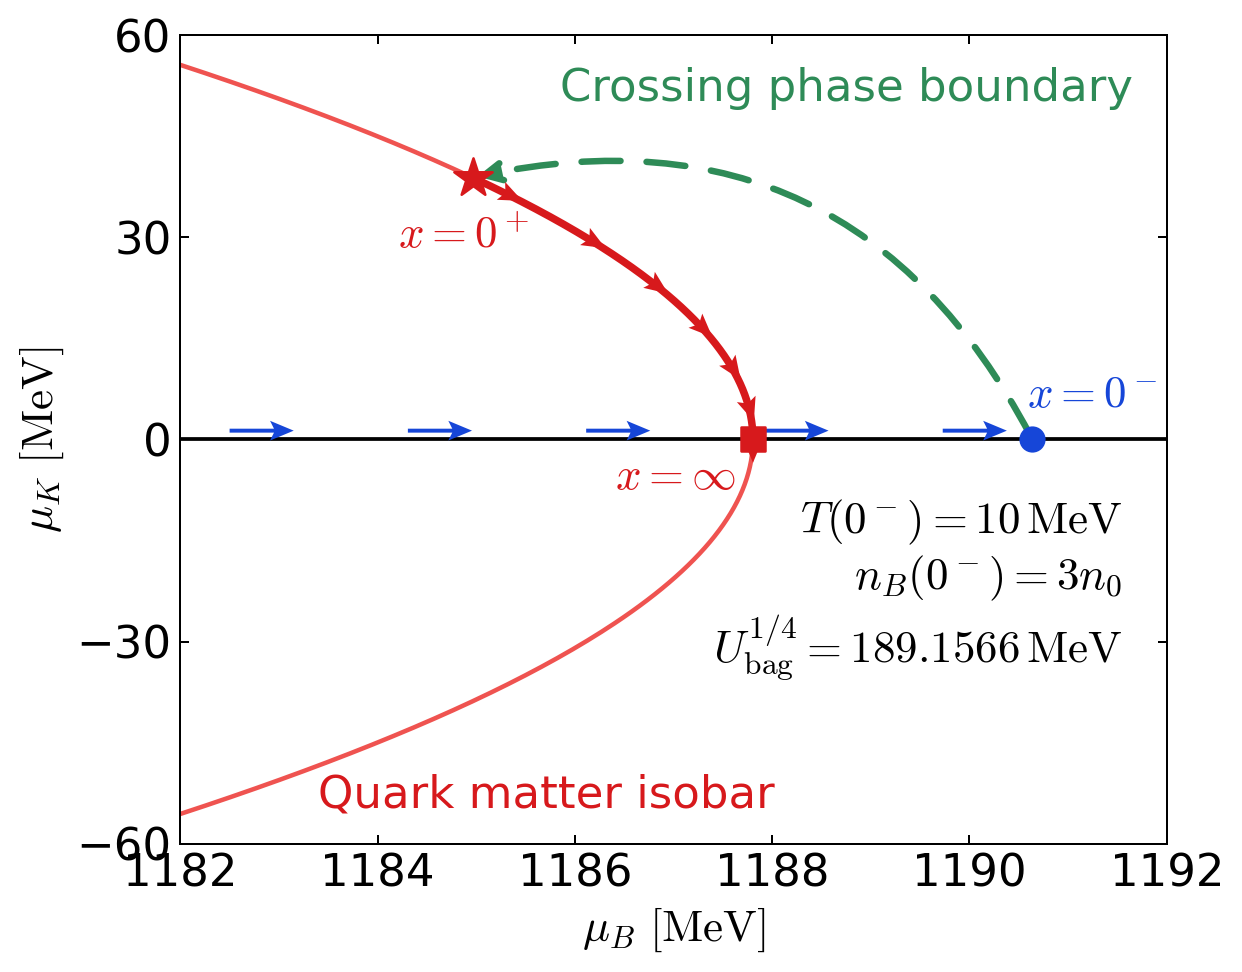

saved figure: Latex_writting/Hydrodynamical combustion/Plots/isothermal_muB_muK_plane.pdf
saved preview: local_analysis_results/All_Plots_new/isothermal_muB_muK_plane.png


In [3]:
# Tunable plotting parameters
FIGURE_SIZE = (7.0, 5.5)
FIGURE_DPI = 180
EXPORT_DPI = 300
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
ANNOTATION_FONT_SIZE = 18
CURVE_LABEL_FONT_SIZE = 18
INPUT_LABEL_FONT_SIZE = 18
ISOBAR_LINE_WIDTH = 1.8
PROFILE_LINE_WIDTH = 3.0
ZERO_LINE_WIDTH = 1.5
PHASE_BOUNDARY_LINE_WIDTH = 2.6
ARROW_SHAFT_WIDTH = 0.004
ARROW_HEAD_WIDTH = 5.0
ARROW_HEAD_LENGTH = 6.0
ARROW_AXIS_LENGTH = 5.0
PROFILE_ARROW_LENGTH = 3.5
PROFILE_ARROW_COUNT = 7
UPSTREAM_ARROW_COUNT = 5
UPSTREAM_ARROW_LENGTH = 0.65
INTERFACE_MARKER_SIZE = 260
ENDPOINT_MARKER_SIZE = 90
UPSTREAM_MARKER_SIZE = 90
MARKER_ZORDER = 6
ISOBAR_COLOR = "#ef5350"
PROFILE_COLOR = "#d7191c"
UPSTREAM_COLOR = "#1646d8"
PHASE_BOUNDARY_COLOR = "seagreen"
ZERO_LINE_COLOR = "black"
ISOBAR_LINE_STYLE = "-"
PHASE_BOUNDARY_LINE_STYLE = (0, (6, 4))
INTERFACE_MARKER_STYLE = "*"
ENDPOINT_MARKER_STYLE = "s"
UPSTREAM_MARKER_STYLE = "o"
PHASE_BOUNDARY_CURVATURE = 0.38
PHASE_BOUNDARY_ARROW_SCALE = 18
X_LIMITS_MEV = (1182.0, 1192.0)
Y_LIMITS_MEV = (-60.0, 60.0)
MU_K_TICKS_MEV = (-60.0, -30.0, 0.0, 30.0, 60.0)
TICK_DIRECTION = "in"
SHOW_TOP_TICKS = True
SHOW_RIGHT_TICKS = True
INTERFACE_LABEL_OFFSET = (-30, -28)
ENDPOINT_LABEL_OFFSET = (-55, -20)
UPSTREAM_LABEL_OFFSET = (-2, 13)
UPSTREAM_ARROW_Y_MEV = 1.3
UPSTREAM_ARROW_START_PADDING_MEV = 0.5
UPSTREAM_ARROW_END_GAP_FACTOR = 1.4
ISOBAR_LABEL_POSITION = (1183.4, -56.0)
ISOBAR_LABEL_ROTATION_DEG = 0.0
PHASE_BOUNDARY_LABEL_POSITION = (1188.75, 52.0)
INPUT_LABEL_POSITION = (1191.55, -36.0)
SAVE_TRANSPARENT = False
BOUNDING_BOX = "tight"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/isothermal_muB_muK_plane.pdf"
OUTPUT_PNG = "local_analysis_results/All_Plots_new/isothermal_muB_muK_plane.png"

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyArrowPatch

output_pdf_path = Path(OUTPUT_PDF)
output_png_path = Path(OUTPUT_PNG)
output_pdf_path.parent.mkdir(parents=True, exist_ok=True)
output_png_path.parent.mkdir(parents=True, exist_ok=True)

try:
    isothermal_plot_data = ISOTHERMAL_MU_PLANE_DATA
except NameError as error:
    raise RuntimeError(
        "Run the heavy isothermal calculation cell once before plotting."
    ) from error
if not isinstance(isothermal_plot_data, dict):
    raise RuntimeError(
        "The isothermal plotting payload is unavailable; rerun the calculation cell."
    )

required_plot_fields = (
    "muB_isobar",
    "muK_isobar",
    "muB_profile",
    "muK_profile",
    "muB_0minus",
    "muB_0plus",
    "muK_0plus",
    "muB_inf",
    "muK_inf",
    "T_0minus",
    "nB_0minus_over_n0",
    "B_one_forth",
)
missing_plot_fields = [
    field for field in required_plot_fields if field not in isothermal_plot_data
]
if missing_plot_fields:
    raise RuntimeError(
        "The isothermal plotting payload is incomplete: "
        + ", ".join(missing_plot_fields)
    )

isothermal_muB_isobar = np.asarray(isothermal_plot_data["muB_isobar"], dtype=float)
isothermal_muK_isobar = np.asarray(isothermal_plot_data["muK_isobar"], dtype=float)
isothermal_muB_profile = np.asarray(isothermal_plot_data["muB_profile"], dtype=float)
isothermal_muK_profile = np.asarray(isothermal_plot_data["muK_profile"], dtype=float)
if isothermal_muB_isobar.shape != isothermal_muK_isobar.shape:
    raise RuntimeError("The cached isothermal isobar arrays have inconsistent shapes.")
if isothermal_muB_profile.shape != isothermal_muK_profile.shape:
    raise RuntimeError("The cached isothermal profile arrays have inconsistent shapes.")
if isothermal_muB_isobar.ndim != 1 or isothermal_muB_profile.ndim != 1:
    raise RuntimeError("The cached isothermal plotting arrays must be one-dimensional.")

isothermal_muB_0minus = float(isothermal_plot_data["muB_0minus"])
isothermal_muB_0plus = float(isothermal_plot_data["muB_0plus"])
isothermal_muK_0plus = float(isothermal_plot_data["muK_0plus"])
isothermal_muB_inf = float(isothermal_plot_data["muB_inf"])
isothermal_muK_inf = float(isothermal_plot_data["muK_inf"])
isothermal_T_0minus = float(isothermal_plot_data["T_0minus"])
isothermal_nB_0minus_over_n0 = float(
    isothermal_plot_data["nB_0minus_over_n0"]
)
isothermal_B_one_forth = float(isothermal_plot_data["B_one_forth"])


mpl.rcParams.update(
    {
        "mathtext.fontset": "cm",
        "mathtext.rm": "serif",
        "mathtext.it": "serif:italic",
        "mathtext.bf": "serif:bold",
    }
)

figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
axis.plot(
    isothermal_muB_isobar,
    isothermal_muK_isobar,
    color=ISOBAR_COLOR,
    linewidth=ISOBAR_LINE_WIDTH,
    linestyle=ISOBAR_LINE_STYLE,
    zorder=1,
)
axis.axhline(
    0.0,
    color=ZERO_LINE_COLOR,
    linewidth=ZERO_LINE_WIDTH,
    zorder=0,
)
axis.plot(
    isothermal_muB_profile,
    isothermal_muK_profile,
    color=PROFILE_COLOR,
    linewidth=PROFILE_LINE_WIDTH,
    zorder=4,
)

profile_indices = np.unique(
    np.linspace(0, isothermal_muB_profile.size - 2, PROFILE_ARROW_COUNT, dtype=int)
)
delta_muB = isothermal_muB_profile[profile_indices + 1] - isothermal_muB_profile[profile_indices]
delta_muK = isothermal_muK_profile[profile_indices + 1] - isothermal_muK_profile[profile_indices]
tangent_norm = np.hypot(delta_muB, delta_muK)
profile_arrow_u = PROFILE_ARROW_LENGTH * delta_muB / tangent_norm
profile_arrow_v = PROFILE_ARROW_LENGTH * delta_muK / tangent_norm
axis.quiver(
    isothermal_muB_profile[profile_indices],
    isothermal_muK_profile[profile_indices],
    profile_arrow_u,
    profile_arrow_v,
    angles="xy",
    scale_units="xy",
    scale=1,
    color=PROFILE_COLOR,
    width=ARROW_SHAFT_WIDTH,
    headwidth=ARROW_HEAD_WIDTH,
    headlength=ARROW_HEAD_LENGTH,
    headaxislength=ARROW_AXIS_LENGTH,
    zorder=5,
)

upstream_arrow_x = np.linspace(
    X_LIMITS_MEV[0] + UPSTREAM_ARROW_START_PADDING_MEV,
    isothermal_muB_0minus - UPSTREAM_ARROW_END_GAP_FACTOR * UPSTREAM_ARROW_LENGTH,
    UPSTREAM_ARROW_COUNT,
)
axis.quiver(
    upstream_arrow_x,
    np.full_like(upstream_arrow_x, UPSTREAM_ARROW_Y_MEV),
    np.full_like(upstream_arrow_x, UPSTREAM_ARROW_LENGTH),
    np.zeros_like(upstream_arrow_x),
    angles="xy",
    scale_units="xy",
    scale=1,
    color=UPSTREAM_COLOR,
    width=ARROW_SHAFT_WIDTH,
    headwidth=ARROW_HEAD_WIDTH,
    headlength=ARROW_HEAD_LENGTH,
    headaxislength=ARROW_AXIS_LENGTH,
    zorder=3,
)

phase_boundary = FancyArrowPatch(
    (isothermal_muB_0minus, 0.0),
    (float(isothermal_muB_0plus), float(isothermal_muK_0plus)),
    connectionstyle=f"arc3,rad={PHASE_BOUNDARY_CURVATURE}",
    arrowstyle="-|>",
    mutation_scale=PHASE_BOUNDARY_ARROW_SCALE,
    linestyle=PHASE_BOUNDARY_LINE_STYLE,
    linewidth=PHASE_BOUNDARY_LINE_WIDTH,
    color=PHASE_BOUNDARY_COLOR,
    zorder=3,
)
axis.add_patch(phase_boundary)

axis.scatter(
    isothermal_muB_0plus,
    isothermal_muK_0plus,
    s=INTERFACE_MARKER_SIZE,
    marker=INTERFACE_MARKER_STYLE,
    color=PROFILE_COLOR,
    zorder=MARKER_ZORDER,
)
axis.scatter(
    isothermal_muB_inf,
    isothermal_muK_inf,
    s=ENDPOINT_MARKER_SIZE,
    marker=ENDPOINT_MARKER_STYLE,
    color=PROFILE_COLOR,
    zorder=MARKER_ZORDER,
)
axis.scatter(
    isothermal_muB_0minus,
    0.0,
    s=UPSTREAM_MARKER_SIZE,
    marker=UPSTREAM_MARKER_STYLE,
    color=UPSTREAM_COLOR,
    zorder=MARKER_ZORDER,
)

axis.annotate(
    r"$x=0^+$",
    (isothermal_muB_0plus, isothermal_muK_0plus),
    xytext=INTERFACE_LABEL_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=PROFILE_COLOR,
    fontweight="bold",
)
axis.annotate(
    r"$x=\infty$",
    (isothermal_muB_inf, isothermal_muK_inf),
    xytext=ENDPOINT_LABEL_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=PROFILE_COLOR,
    fontweight="bold",
)
axis.annotate(
    r"$x=0^-$",
    (isothermal_muB_0minus, 0.0),
    xytext=UPSTREAM_LABEL_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=UPSTREAM_COLOR,
    fontweight="bold",
)

axis.text(
    *ISOBAR_LABEL_POSITION,
    "Quark matter isobar",
    color=PROFILE_COLOR,
    fontsize=CURVE_LABEL_FONT_SIZE,
    rotation=ISOBAR_LABEL_ROTATION_DEG,
    ha="left",
    va="bottom",
    rotation_mode="anchor",
)
axis.text(
    *PHASE_BOUNDARY_LABEL_POSITION,
    "Crossing phase boundary",
    color=PHASE_BOUNDARY_COLOR,
    fontsize=CURVE_LABEL_FONT_SIZE,
    ha="center",
    va="center",
)
axis.text(
    *INPUT_LABEL_POSITION,
    rf"$T(0^-)= {isothermal_T_0minus:g}\,\mathrm{{MeV}}$"
    "\n"
    rf"$n_B(0^-)= {isothermal_nB_0minus_over_n0:g}n_0$"
    "\n"
    rf"$U_{{\rm bag}}^{{1/4}}={isothermal_B_one_forth:.4f}\,\mathrm{{MeV}}$",
    fontsize=INPUT_LABEL_FONT_SIZE,
    color="black",
    ha="right",
    va="bottom",
)

axis.set_xlabel(r"$\mu_B\ \mathrm{[MeV]}$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(r"$\mu_K\ \mathrm{[MeV]}$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_xlim(*X_LIMITS_MEV)
axis.set_ylim(*Y_LIMITS_MEV)
axis.set_yticks(MU_K_TICKS_MEV)
axis.tick_params(
    which="both",
    direction=TICK_DIRECTION,
    top=SHOW_TOP_TICKS,
    right=SHOW_RIGHT_TICKS,
    labelsize=TICK_LABEL_FONT_SIZE,
)

figure.tight_layout()
figure.savefig(
    output_pdf_path,
    dpi=EXPORT_DPI,
    bbox_inches=BOUNDING_BOX,
    transparent=SAVE_TRANSPARENT,
)
figure.savefig(
    output_png_path,
    dpi=EXPORT_DPI,
    bbox_inches=BOUNDING_BOX,
    transparent=SAVE_TRANSPARENT,
)
plt.show()

print(f"saved figure: {output_pdf_path}")
print(f"saved preview: {output_png_path}")


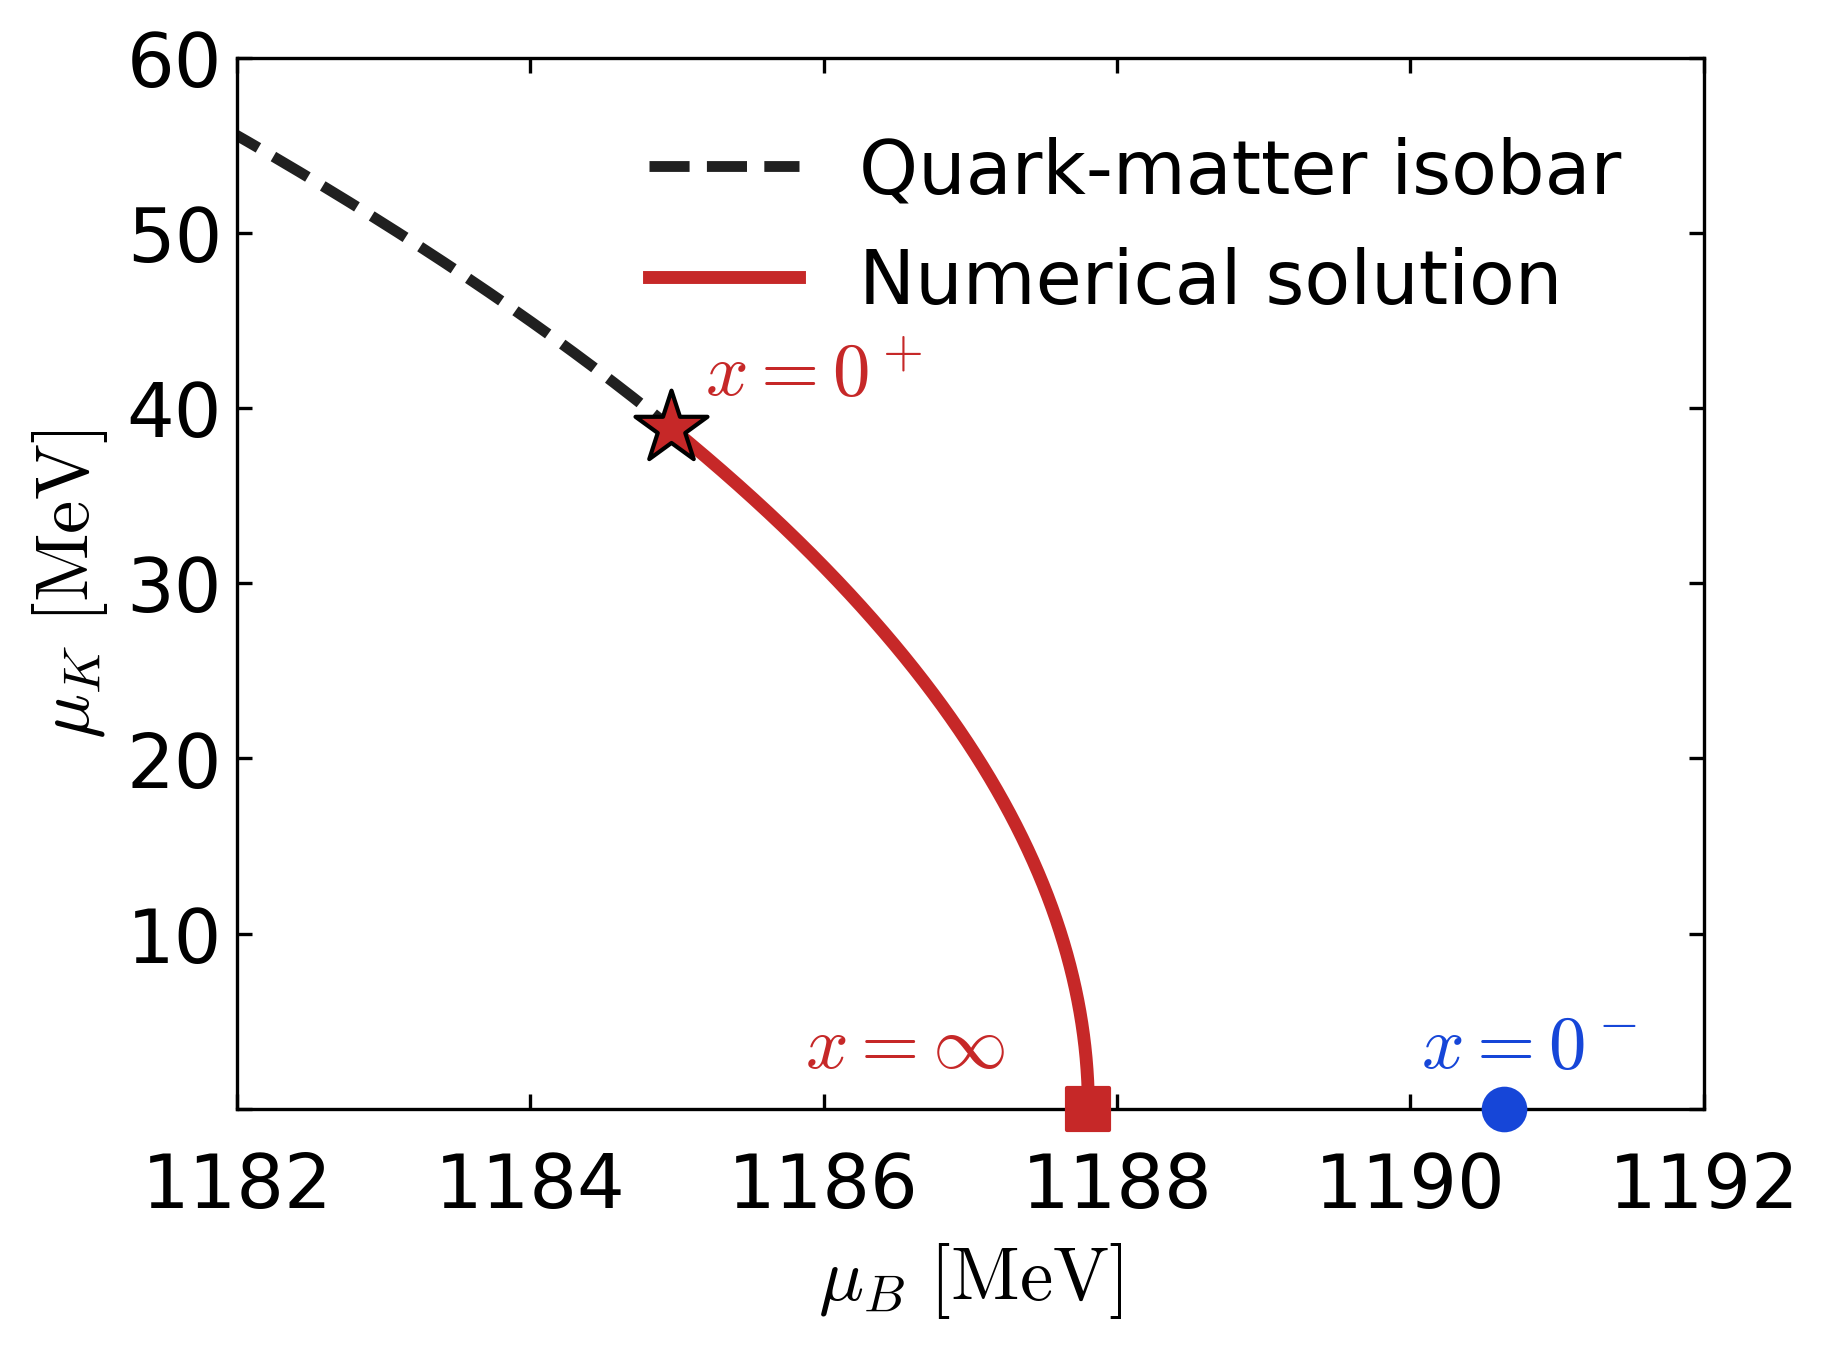

Saved manuscript figure: Latex_writting/Hydrodynamical combustion/Plots/isothermal_muB_muK_plane.pdf


In [1]:
# Tunable plotting parameters
PLOT_DATA_PATH = "local_analysis_results/All_Plots_new/isothermal_mu_plane_plot_data.npz"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/isothermal_muB_muK_plane.pdf"
OUTPUT_PNG = "local_analysis_results/All_Plots_new/isothermal_muB_muK_plane.png"
FIGURE_SIZE = (6.2, 4.6)
FIGURE_DPI = 180
EXPORT_DPI = 300
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
LEGEND_FONT_SIZE = 18
ANNOTATION_FONT_SIZE = 18
INPUT_LABEL_FONT_SIZE = 18
ISOBAR_LINE_WIDTH = 2.6
PROFILE_LINE_WIDTH = 3.1
PROFILE_COLOR = "#c62828"
ISOBAR_COLOR = "#202020"
UPSTREAM_COLOR = "#1646d8"
INPUT_LABEL_COLOR = "black"
ISOBAR_LINE_STYLE = "--"
PROFILE_LINE_STYLE = "-"
ISOBAR_LABEL = "Quark-matter isobar"
PROFILE_LABEL = "Numerical solution"
ISOBAR_ZORDER = 1
PROFILE_ZORDER = 3
MARKER_ZORDER = 5
INTERFACE_MARKER_STYLE = "*"
INTERFACE_MARKER_SIZE = 330
INTERFACE_EDGE_COLOR = "black"
INTERFACE_EDGE_LINE_WIDTH = 1.0
DOWNSTREAM_MARKER_STYLE = "s"
DOWNSTREAM_MARKER_SIZE = 99
UPSTREAM_MARKER_STYLE = "o"
UPSTREAM_MARKER_SIZE = 99
CLIP_ENDPOINT_MARKERS = False
INTERFACE_LABEL = r"$x=0^+$"
DOWNSTREAM_LABEL = r"$x=\infty$"
UPSTREAM_LABEL = r"$x=0^-$"
INTERFACE_LABEL_OFFSET = (8, 8)
DOWNSTREAM_LABEL_OFFSET = (-68, 10)
UPSTREAM_LABEL_OFFSET = (-20, 10)
INPUT_LABEL_POSITION = (1182.2, 7.0)
INPUT_LABEL_ALIGNMENT = "left"
INPUT_LABEL_VERTICAL_ALIGNMENT = "bottom"
BAG_LABEL_DECIMAL_PLACES = 4
X_AXIS_LABEL = r"$\mu_B\ \mathrm{[MeV]}$"
Y_AXIS_LABEL = r"$\mu_K\ \mathrm{[MeV]}$"
X_LIMITS_MEV = (1182.0, 1192.0)
Y_LIMITS_MEV = (0.0, 60.0)
X_TICKS_MEV = (1182.0, 1184.0, 1186.0, 1188.0, 1190.0, 1192.0)
Y_TICKS_MEV = (0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0)
HIDE_ZERO_Y_LABEL = True
TICK_DIRECTION = "in"
X_TICK_LABEL_PAD = 10
SHOW_TOP_TICKS = True
SHOW_RIGHT_TICKS = True
SHOW_GRID = False
GRID_ALPHA = 0.15
LEGEND_LOCATION = "upper right"
LEGEND_FRAME = False
LEGEND_BBOX_TO_ANCHOR = (0.99, 0.99)
MATHTEXT_FONTSET = "cm"
MATHTEXT_ROMAN = "serif"
MATHTEXT_ITALIC = "serif:italic"
MATHTEXT_BOLD = "serif:bold"
SAVE_TRANSPARENT = False
BOUNDING_BOX = "tight"

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

plot_data = globals().get("ISOTHERMAL_MU_PLANE_DATA")
if not isinstance(plot_data, dict):
    with np.load(PLOT_DATA_PATH) as cached_data:
        plot_data = {name: cached_data[name].copy() for name in cached_data.files}

muB_isobar = np.asarray(plot_data["muB_isobar"], dtype=float)
muK_isobar = np.asarray(plot_data["muK_isobar"], dtype=float)
muB_profile = np.asarray(plot_data["muB_profile"], dtype=float)
muK_profile = np.asarray(plot_data["muK_profile"], dtype=float)
# Only the positive-strangeness-imbalance branch is traversed by this front.
physical_branch = muK_isobar >= 0
muB_0plus = float(plot_data["muB_0plus"])
muK_0plus = float(plot_data["muK_0plus"])
muB_inf = float(plot_data["muB_inf"])
muK_inf = float(plot_data["muK_inf"])
muB_0minus = float(plot_data["muB_0minus"])
temperature_0minus = float(plot_data["T_0minus"])
density_0minus_over_n0 = float(plot_data["nB_0minus_over_n0"])
bag_one_fourth = float(plot_data["B_one_forth"])

with mpl.rc_context({
    "mathtext.fontset": MATHTEXT_FONTSET,
    "mathtext.rm": MATHTEXT_ROMAN,
    "mathtext.it": MATHTEXT_ITALIC,
    "mathtext.bf": MATHTEXT_BOLD,
}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
    axis.plot(muB_isobar[physical_branch], muK_isobar[physical_branch],
              color=ISOBAR_COLOR, linewidth=ISOBAR_LINE_WIDTH,
              linestyle=ISOBAR_LINE_STYLE, label=ISOBAR_LABEL, zorder=ISOBAR_ZORDER)
    axis.plot(muB_profile, muK_profile, color=PROFILE_COLOR,
              linewidth=PROFILE_LINE_WIDTH, linestyle=PROFILE_LINE_STYLE,
              label=PROFILE_LABEL, zorder=PROFILE_ZORDER)
    axis.scatter(muB_0plus, muK_0plus, s=INTERFACE_MARKER_SIZE,
                 marker=INTERFACE_MARKER_STYLE, color=PROFILE_COLOR,
                 edgecolor=INTERFACE_EDGE_COLOR, linewidths=INTERFACE_EDGE_LINE_WIDTH,
                 zorder=MARKER_ZORDER, clip_on=CLIP_ENDPOINT_MARKERS)
    axis.scatter(muB_inf, muK_inf, s=DOWNSTREAM_MARKER_SIZE,
                 marker=DOWNSTREAM_MARKER_STYLE, color=PROFILE_COLOR,
                 zorder=MARKER_ZORDER, clip_on=CLIP_ENDPOINT_MARKERS)
    axis.scatter(muB_0minus, 0.0, s=UPSTREAM_MARKER_SIZE,
                 marker=UPSTREAM_MARKER_STYLE, color=UPSTREAM_COLOR,
                 zorder=MARKER_ZORDER, clip_on=CLIP_ENDPOINT_MARKERS)
    axis.annotate(INTERFACE_LABEL, (muB_0plus, muK_0plus),
                  xytext=INTERFACE_LABEL_OFFSET, textcoords="offset points",
                  fontsize=ANNOTATION_FONT_SIZE, color=PROFILE_COLOR)
    axis.annotate(DOWNSTREAM_LABEL, (muB_inf, muK_inf),
                  xytext=DOWNSTREAM_LABEL_OFFSET, textcoords="offset points",
                  fontsize=ANNOTATION_FONT_SIZE, color=PROFILE_COLOR)
    axis.annotate(UPSTREAM_LABEL, (muB_0minus, 0.0),
                  xytext=UPSTREAM_LABEL_OFFSET, textcoords="offset points",
                  fontsize=ANNOTATION_FONT_SIZE, color=UPSTREAM_COLOR)
    #axis.text(
    #    *INPUT_LABEL_POSITION,
    #    rf"$T(0^-)={temperature_0minus:g}\,\mathrm{{MeV}}$" "\n"
    #    rf"$n_B(0^-)={density_0minus_over_n0:g}n_0$" "\n"
    #    rf"$U_{{\rm bag}}^{{1/4}}={bag_one_fourth:.{BAG_LABEL_DECIMAL_PLACES}f}\,\mathrm{{MeV}}$",
    #    fontsize=INPUT_LABEL_FONT_SIZE, color=INPUT_LABEL_COLOR,
    #    ha=INPUT_LABEL_ALIGNMENT, va=INPUT_LABEL_VERTICAL_ALIGNMENT,
    #)
    axis.set_xlabel(X_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_xlim(*X_LIMITS_MEV)
    axis.set_ylim(*Y_LIMITS_MEV)
    axis.set_xticks(X_TICKS_MEV)
    axis.set_yticks(Y_TICKS_MEV)
    if HIDE_ZERO_Y_LABEL:
        axis.set_yticklabels(["" if np.isclose(y, 0.0) else f"{y:g}" for y in Y_TICKS_MEV])
    axis.tick_params(which="both", direction=TICK_DIRECTION,
                     top=SHOW_TOP_TICKS, right=SHOW_RIGHT_TICKS,
                     labelsize=TICK_LABEL_FONT_SIZE)
    axis.tick_params(axis="x", which="both", pad=X_TICK_LABEL_PAD)
    if SHOW_GRID:
        axis.grid(alpha=GRID_ALPHA)
    axis.legend(frameon=LEGEND_FRAME, fontsize=LEGEND_FONT_SIZE,
                loc=LEGEND_LOCATION, bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR)
    figure.tight_layout()
    for filename in (OUTPUT_PDF, OUTPUT_PNG):
        output_path = Path(filename)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        figure.savefig(output_path, dpi=EXPORT_DPI, bbox_inches=BOUNDING_BOX,
                       transparent=SAVE_TRANSPARENT)
    plt.show()

print(f"Saved manuscript figure: {OUTPUT_PDF}")


# Fixed $T(0^+)=0.1\,\mathrm{MeV}$ numerical contour

This clean panel combines the complete numerical grid through $\rho=0.84$ with a fully numerical outer bracketing shell. The outer shell uses the converged $\rho=0.86$ solution wherever it already exceeds $5000\,\mathrm{m\,s^{-1}}$ and the adaptive `26-08-24` endpoint for theta indices 7--26. All 30 angular rays therefore bracket the $5000\,\mathrm{m\,s^{-1}}$ level without interpolating failed solver cells.

Adaptive 5000 m/s brackets: 20/20
Minimum numerical outer-shell velocity: 5046.44 m/s
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-11/T0plus0p1-complete-5000-contour.png
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-11/T0plus0p1-complete-5000-contour.pdf


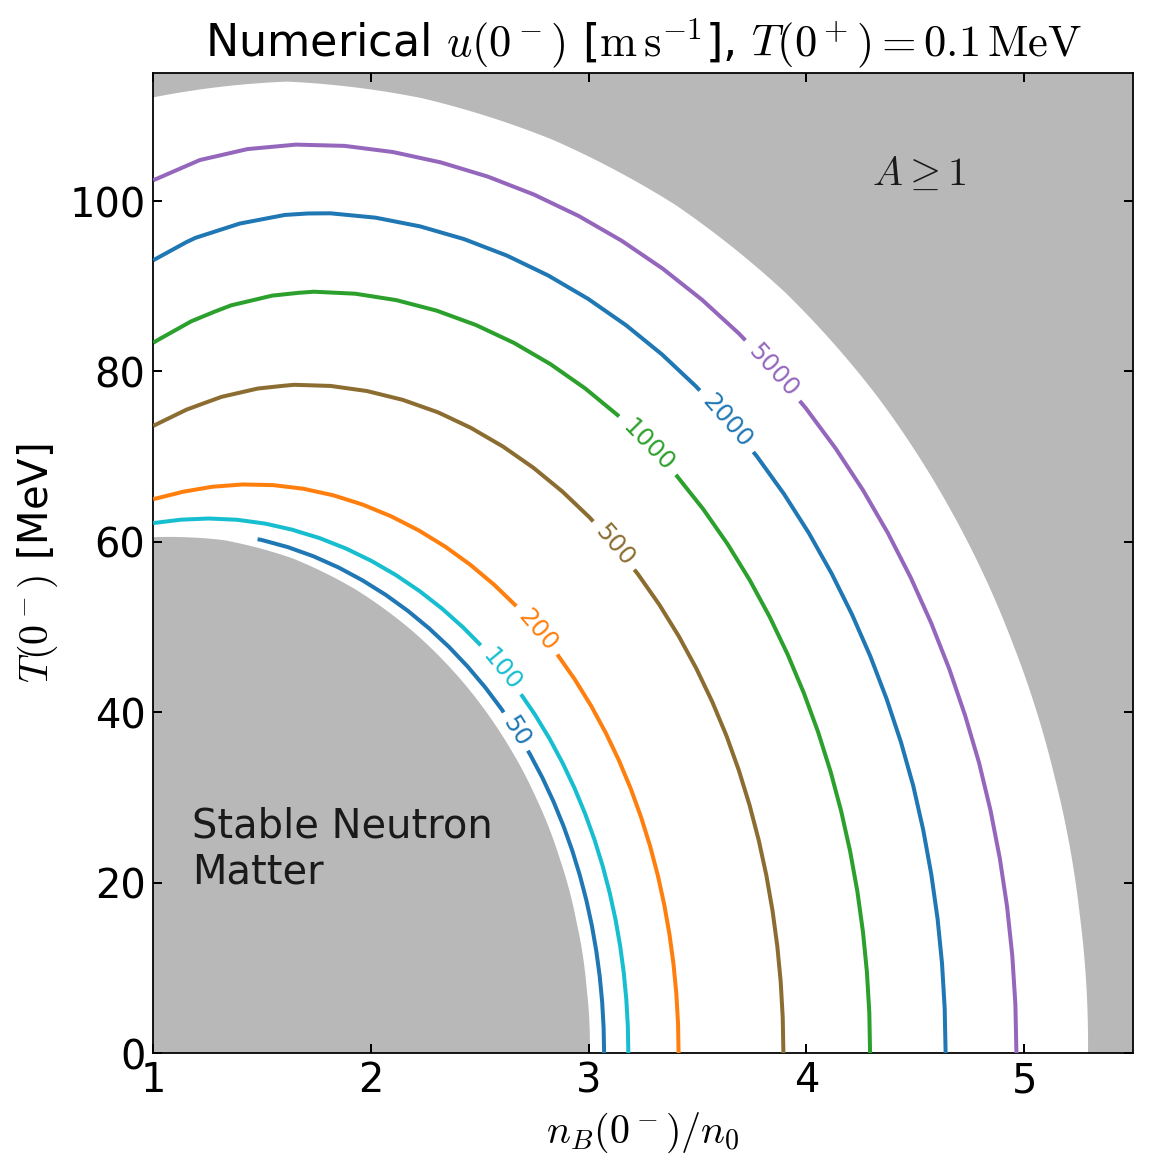

In [23]:
# Tunable plotting parameters
CONTOUR_DOMAIN_PATH = "new_paper_calculations/26-08-21/T0plus0p1-domain.npy"
FULL_NUMERICAL_PATH = "new_paper_calculations/26-08-21/T0plus0p1-uNmax-angular-wavefront.npy"
RHO086_SHELL_PATH = "new_paper_calculations/26-08-24/rho0p86_full_theta_shell/T0plus0p1-rho0p86-full-theta-shell.npy"
ADAPTIVE_BRACKET_PATH = "new_paper_calculations/26-08-24/rho5k_adaptive_bracket/T0plus0p1-rho5k-adaptive-bracket.npy"
T0PLUS_MEV = 0.1
CORE_MAX_RHO = 0.84
TARGET_CONTOUR_M_S = 5000.0
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4", "#9467bd")
VELOCITY_CONTOUR_LINE_STYLE = "-"
VELOCITY_CONTOUR_LINE_WIDTH = 1.8
CONTOUR_LABEL_FONT_SIZE = 11
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_ZORDER = 3
BOUNDARY_INTERPOLATION_SAMPLES = 401
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
A_REGION_TEXT = r"$A\geq 1$"
A_REGION_TEXT_POSITION = (4.3, 102.0)
INNER_REGION_TEXT = "Stable Neutron\nMatter"
INNER_REGION_TEXT_POSITION = (1.18, 20.0)
REGION_TEXT_COLOR = "0.10"
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = "linear"
Y_SCALE = "linear"
BOX_ASPECT = 1.0
TITLE = r"Numerical $u(0^-)$ [$\mathrm{m\,s^{-1}}$], $T(0^+)=0.1\,\mathrm{MeV}$"
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
OUTPUT_PNG = "local_analysis_results/26SU-11/T0plus0p1-complete-5000-contour.png"
OUTPUT_PDF = "local_analysis_results/26SU-11/T0plus0p1-complete-5000-contour.pdf"

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
domain = np.load(root / CONTOUR_DOMAIN_PATH, allow_pickle=True).item()
full_numerical = np.load(root / FULL_NUMERICAL_PATH, allow_pickle=True).item()
rho086_shell = np.load(root / RHO086_SHELL_PATH, allow_pickle=True).item()
adaptive_bracket = np.load(root / ADAPTIVE_BRACKET_PATH, allow_pickle=True).item()

temperature_axis = np.asarray(domain["T_0plus_values_MeV"], dtype=float)
numerical_temperature_axis = np.asarray(full_numerical["T_0plus_values_MeV"], dtype=float)
if temperature_axis.shape != (1,) or not np.isclose(temperature_axis[0], T0PLUS_MEV):
    raise RuntimeError(f"Expected only T(0+)={T0PLUS_MEV:g} MeV, found {temperature_axis}")
if not np.array_equal(numerical_temperature_axis, temperature_axis):
    raise RuntimeError("The numerical checkpoint does not share the fixed-T(0+) domain")
if not bool(rho086_shell.get("run_complete")) or not np.all(np.asarray(rho086_shell["success_grid"], dtype=bool)):
    raise RuntimeError("The rho=0.86 shell is not complete")
if not bool(adaptive_bracket.get("run_complete")):
    raise RuntimeError("The adaptive 5000 m/s bracket checkpoint is incomplete")
if not np.all(np.asarray(adaptive_bracket["accepted_5000_bracket"], dtype=bool)):
    raise RuntimeError("At least one adaptive theta ray does not exceed the acceptance velocity")

boundary = domain["boundary_diagnostics"]["semi_analytic"]
transform = domain["transform"]
density_origin = float(transform["density_origin_over_n0"])
density_scale = float(transform["density_scale_over_n0"])
temperature_scale = float(transform["temperature_scale_MeV"])

def boundary_curve(records):
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta_roots = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho_roots = np.asarray([row["rho"] for row in ordered], dtype=float)
    theta = np.linspace(theta_roots[0], theta_roots[-1], BOUNDARY_INTERPOLATION_SAMPLES)
    rho = np.interp(theta, theta_roots, rho_roots)
    density = density_origin + density_scale * rho * np.cos(theta)
    temperature = temperature_scale * rho * np.sin(theta)
    return density, temperature

A_density, A_temperature = boundary_curve(boundary["A_curve_records"])
inner_density, inner_temperature = boundary_curve(boundary["gap_curve_records_by_T0plus"][T0PLUS_MEV])
radial_axis = np.asarray(full_numerical["contour_radial_fraction_axis"], dtype=float)
core_columns = radial_axis <= CORE_MAX_RHO + 1.0e-12
density = np.asarray(full_numerical["nB_0minus_over_n0_grid"], dtype=float)[:, core_columns, 0]
temperature = np.asarray(full_numerical["T_0minus_MeV_grid"], dtype=float)[:, core_columns, 0]
velocity = np.asarray(full_numerical["numerical_outward_u_0minus_m_s_grid"], dtype=float)[:, core_columns, 0]
success = np.asarray(full_numerical["numerical_outward_success_grid"], dtype=bool)[:, core_columns, 0]
if not np.all(success):
    raise RuntimeError(f"The numerical core through rho={CORE_MAX_RHO:g} is incomplete")

rho086_records = {
    int(record["theta_index"]): record
    for record in rho086_shell["records"]
    if bool(record.get("success"))
}
expected_theta_indices = np.arange(density.shape[0], dtype=int)
if tuple(sorted(rho086_records)) != tuple(expected_theta_indices):
    raise RuntimeError("The rho=0.86 shell does not contain exactly theta indices 0-29")
outer_density = np.asarray([rho086_records[index]["nB_0minus_over_n0"] for index in expected_theta_indices], dtype=float)
outer_temperature = np.asarray([rho086_records[index]["T_0minus_MeV"] for index in expected_theta_indices], dtype=float)
outer_velocity = np.asarray(rho086_shell["u_0minus_m_s_grid"], dtype=float)[:, 0]

adaptive_records = {
    int(record["theta_index"]): record
    for record in adaptive_bracket["final_records"]
    if bool(record.get("success"))
}
adaptive_theta_indices = tuple(int(index) for index in np.asarray(adaptive_bracket["theta_indices"], dtype=int))
if tuple(sorted(adaptive_records)) != adaptive_theta_indices:
    raise RuntimeError("The adaptive checkpoint lacks a successful terminal record")
for theta_index in adaptive_theta_indices:
    record = adaptive_records[theta_index]
    outer_density[theta_index] = float(record["nB_0minus_over_n0"])
    outer_temperature[theta_index] = float(record["T_0minus_MeV"])
    outer_velocity[theta_index] = float(record["u_0minus"]) * 299_792_458.0
if not np.all(outer_velocity > TARGET_CONTOUR_M_S):
    failed_theta = np.flatnonzero(outer_velocity <= TARGET_CONTOUR_M_S)
    raise RuntimeError(f"The numerical outer shell does not bracket 5000 m/s at theta {failed_theta.tolist()}")

density = np.concatenate((density, outer_density[:, None]), axis=1)
temperature = np.concatenate((temperature, outer_temperature[:, None]), axis=1)
velocity = np.concatenate((velocity, outer_velocity[:, None]), axis=1)

figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI, constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
inner_polygon_x = np.concatenate((inner_density, (X_LIMITS[0], inner_density[0])))
inner_polygon_y = np.concatenate((inner_temperature, (Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
axis.fill(inner_polygon_x, inner_polygon_y, color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
A_polygon_x = np.concatenate((A_density, (X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], A_density[0])))
A_polygon_y = np.concatenate((A_temperature, (Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
axis.fill(A_polygon_x, A_polygon_y, color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)

numerical_contours = axis.contour(
    density,
    temperature,
    velocity,
    levels=VELOCITY_CONTOUR_LEVELS_M_S,
    colors=VELOCITY_CONTOUR_COLORS,
    linestyles=VELOCITY_CONTOUR_LINE_STYLE,
    linewidths=VELOCITY_CONTOUR_LINE_WIDTH,
    zorder=CONTOUR_ZORDER,
)
axis.clabel(
    numerical_contours,
    inline=CONTOUR_LABEL_INLINE,
    fmt=CONTOUR_LABEL_FORMAT,
    fontsize=CONTOUR_LABEL_FONT_SIZE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
)
axis.text(*A_REGION_TEXT_POSITION, A_REGION_TEXT, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
axis.text(*INNER_REGION_TEXT_POSITION, INNER_REGION_TEXT, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
axis.set_xlim(*X_LIMITS)
axis.set_ylim(*Y_LIMITS_MEV)
axis.set_xscale(X_SCALE)
axis.set_yscale(Y_SCALE)
axis.set_box_aspect(BOX_ASPECT)
axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT, length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
for spine in axis.spines.values():
    spine.set_linewidth(SPINE_LINE_WIDTH)

output_png = root / OUTPUT_PNG
output_pdf = root / OUTPUT_PDF
output_png.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
figure.savefig(output_pdf, facecolor=BACKGROUND_COLOR)
print(f"Adaptive 5000 m/s brackets: {len(adaptive_records)}/{len(adaptive_theta_indices)}")
print(f"Minimum numerical outer-shell velocity: {np.min(outer_velocity):.2f} m/s")
print(f"Saved {output_png}")
print(f"Saved {output_pdf}")
plt.show()


# Fixed $T(0^+)=0.1\,\mathrm{MeV}$ three-method comparison

Two versions use the same repaired analytical data and unchanged numerical contour: (1) unshaded curves through 5000 m/s; (2) curves through 1000 m/s with translucent bands between the numerical and full-analytical curves. The bands show method differences, not statistical uncertainty, and are clipped to shared angular coverage. Both versions retain the standard line styles, fonts and axis limits, and export separate PDFs to the manuscript's Plots folder. No missing full-analytical contour is extrapolated.


Saved local_analysis_results/All_Plots_new/T0plus0p1-three-method-comparison.png
Saved local_analysis_results/All_Plots_new/T0plus0p1-three-method-comparison.pdf
Saved Latex_writting/Hydrodynamical combustion/Plots/Contour-diff-meth-0.1.pdf
Saved local_analysis_results/All_Plots_new/T0plus0p1-three-method-comparison-bands-to-1000.png
Saved local_analysis_results/All_Plots_new/T0plus0p1-three-method-comparison-bands-to-1000.pdf
Saved Latex_writting/Hydrodynamical combustion/Plots/Contour-diff-meth-0.1-bands-to-1000.pdf
Full analytical: 734/734 accepted points
Semi-analytical: 734/734 accepted points
Semi-analytical 5000 m/s brackets: 30/30
Variants: unshaded through 5000 m/s; numerical-to-full-analytical bands through 1000 m/s.


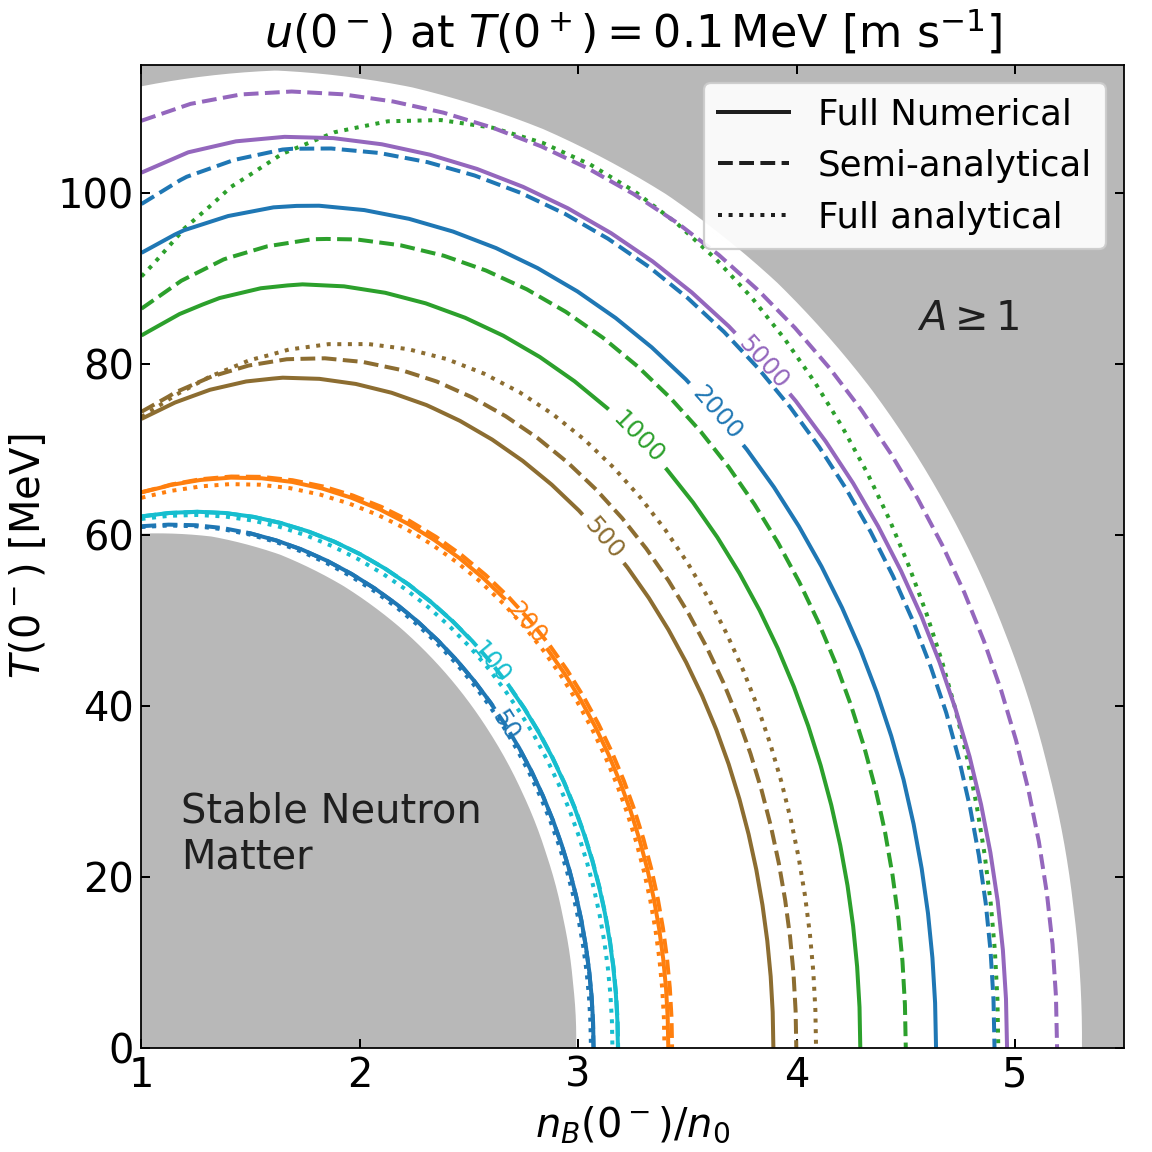

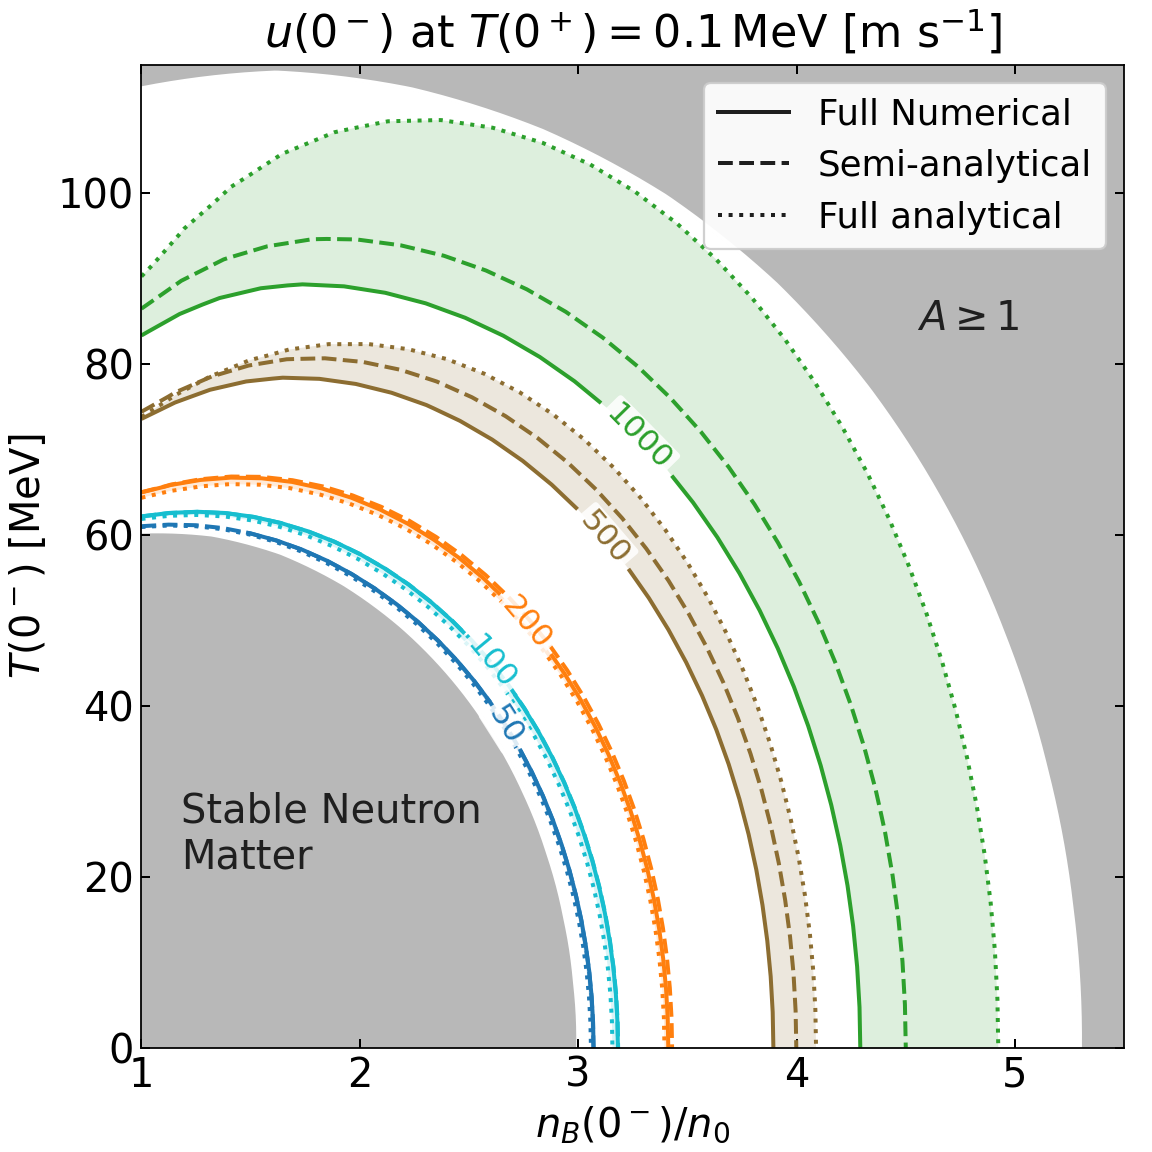

In [ ]:
# Tunable plotting parameters
COMPARISON_PATH = "new_paper_calculations/26-09-28/T0plus0p1-analytical-comparison.npy"
T0PLUS_MEV = 0.1
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4", "#9467bd")
REFINED_CONTOUR_LEVEL_M_S = 5000.0
NUMERICAL_LINE_STYLE = "-"
SEMI_ANALYTIC_LINE_STYLE = "--"
FULL_ANALYTIC_LINE_STYLE = ":"
NUMERICAL_LINE_WIDTH = 1.8
SEMI_ANALYTIC_LINE_WIDTH = 1.8
FULL_ANALYTIC_LINE_WIDTH = 1.8
# Each variant is (maximum velocity [m/s], show bands, export suffix).
COMPARISON_VARIANTS = ((5000.0, False, ""), (1000.0, True, "-bands-to-1000"))
BAND_ALLOW_SEMI_ANALYTIC_FALLBACK = False
BAND_ALPHA = 0.16
BAND_ZORDER = 1.5
BAND_EDGE_COLOR = "none"
BAND_LINE_WIDTH = 0.0
BAND_ANGLE_TOLERANCE = 1e-10
CONTOUR_CORNER_MASK = False
CONTOUR_ZORDER = 2
CONTOUR_LABEL_FONT_SIZE = 11
BANDED_CONTOUR_LABEL_FONT_SIZE = 14
BANDED_CONTOUR_LABEL_BACKGROUND_COLOR = "white"
BANDED_CONTOUR_LABEL_BACKGROUND_ALPHA = 0.85
BANDED_CONTOUR_LABEL_BACKGROUND_PAD = 0.12
BANDED_CONTOUR_LABEL_BACKGROUND_STYLE = "round"
BANDED_CONTOUR_LABEL_EDGE_COLOR = "none"
BANDED_CONTOUR_LABEL_EDGE_WIDTH = 0.0
BANDED_CONTOUR_LABEL_ZORDER = 4
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
BOUNDARY_INTERPOLATION_SAMPLES = 401
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
BOUNDARY_COLOR = "white"
BOUNDARY_LINE_WIDTH = 1.8
BOUNDARY_ZORDER = 1
A_REGION_TEXT = r"$A\geq1$"
A_REGION_TEXT_POSITION = (4.55, 84.0)
INNER_REGION_TEXT = "Stable Neutron\nMatter"
INNER_REGION_TEXT_POSITION = (1.18, 21.0)
REGION_TEXT_COLOR = "0.12"
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
FONT_FAMILY = "DejaVu Sans"
MATH_FONT_SET = "dejavusans"
USE_TEX = False
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = "linear"
Y_SCALE = "linear"
X_TICKS = (1.0, 2.0, 3.0, 4.0, 5.0)
Y_TICKS_MEV = (0.0, 20.0, 40.0, 60.0, 80.0, 100.0)
BOX_ASPECT = 1.0
TITLE = r"$u(0^-)$ at $T(0^+)=0.1\,\mathrm{MeV}$ [m s$^{-1}$]"
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
LEGEND_LOCATION = "upper right"
LEGEND_FONT_SIZE = 16
LEGEND_FRAME_ALPHA = 0.92
LEGEND_COLUMNS = 1
LEGEND_FRAME = True
LEGEND_FANCYBOX = True
LEGEND_FACE_COLOR = "white"
LEGEND_LABELS = ("Full Numerical", "Semi-analytical", "Full analytical")
SHOW_GRID = False
OUTPUT_PNG = "local_analysis_results/All_Plots_new/T0plus0p1-three-method-comparison.png"
OUTPUT_PDF = "local_analysis_results/All_Plots_new/T0plus0p1-three-method-comparison.pdf"
OUTPUT_LATEX_PDF = "Latex_writting/Hydrodynamical combustion/Plots/Contour-diff-meth-0.1.pdf"

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

root = Path.cwd()
comparison = np.load(root / COMPARISON_PATH, allow_pickle=True).item()
if not comparison.get("production_run") or not comparison.get("run_complete"):
    raise RuntimeError("Select a finished production comparison, not a smoke checkpoint")
if not np.isclose(comparison["T_0plus_MeV"], T0PLUS_MEV):
    raise RuntimeError("The comparison has a different prescribed interface temperature")
theta_axis = np.asarray(comparison["theta_rad_axis"], dtype=float)
if not (theta_axis[0] == 0 and theta_axis[-1] == np.pi / 2):
    raise RuntimeError("The comparison must include both exact angular endpoints")

boundary = comparison["boundary_diagnostics"]["semi_analytic"]
transform = comparison["transform"]

def comparison_boundary_curve(records):
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta_roots = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho_roots = np.asarray([row["rho"] for row in ordered], dtype=float)
    theta = np.linspace(theta_roots[0], theta_roots[-1], BOUNDARY_INTERPOLATION_SAMPLES)
    rho = np.interp(theta, theta_roots, rho_roots)
    return (transform["density_origin_over_n0"] + transform["density_scale_over_n0"] * rho * np.cos(theta),
            transform["temperature_scale_MeV"] * rho * np.sin(theta))

def comparison_velocity_grid(grid, method):
    velocity = np.asarray(grid[f"{method}_u_0minus_m_s"], dtype=float)
    success = np.asarray(grid[f"{method}_success"], dtype=bool)
    return np.ma.masked_where(~success | ~np.isfinite(velocity) | (velocity <= 0), velocity)

def comparison_band_paths(full, semi, refined):
    paths, sources = {}, {}
    candidates = [("analytic", full)]
    if BAND_ALLOW_SEMI_ANALYTIC_FALLBACK:
        candidates.extend([("semi_analytic", semi), ("semi_analytic", refined)])
    for method, contours in candidates:
        if contours is not None:
            for level, segments in zip(contours.levels, contours.allsegs):
                if level not in paths:
                    paths[level], sources[level] = segments, method
    return paths, sources

def comparison_band_polygon(first, second):
    # Clip actual contour polylines to shared ray coverage; never extrapolate.
    origin = np.array([transform["density_origin_over_n0"], 0.0])
    scale = np.array([transform["density_scale_over_n0"], transform["temperature_scale_MeV"]])
    paths = []
    for vertices in (first, second):
        vertices = np.asarray(vertices, dtype=float)
        if len(vertices) < 2 or not np.all(np.isfinite(vertices)):
            return None
        normalized = (vertices - origin) / scale
        angles = np.arctan2(normalized[:, 1], normalized[:, 0])
        if angles[-1] < angles[0]:
            vertices, angles = vertices[::-1], angles[::-1]
        if np.any(np.diff(angles) < -BAND_ANGLE_TOLERANCE):
            raise ValueError("Contour is not monotonic in the internal ray angle")
        paths.append((vertices, angles))
    lower = max(angles[0] for _, angles in paths)
    upper = min(angles[-1] for _, angles in paths)
    if upper - lower <= BAND_ANGLE_TOLERANCE:
        return None
    clipped = []
    for vertices, angles in paths:
        def endpoint(angle):
            match = np.flatnonzero(np.abs(angles - angle) <= BAND_ANGLE_TOLERANCE)
            if len(match):
                return vertices[match[0]]
            index = np.searchsorted(angles, angle)
            start = (vertices[index - 1] - origin) / scale
            delta = (vertices[index] - vertices[index - 1]) / scale
            direction = np.array([np.cos(angle), np.sin(angle)])
            fraction = ((direction[0] * start[1] - direction[1] * start[0]) /
                        (delta[0] * direction[1] - delta[1] * direction[0]))
            return vertices[index - 1] + fraction * (vertices[index] - vertices[index - 1])
        interior = (angles > lower + BAND_ANGLE_TOLERANCE) & (angles < upper - BAND_ANGLE_TOLERANCE)
        clipped.append(np.vstack((endpoint(lower), vertices[interior], endpoint(upper))))
    return np.vstack((clipped[0], clipped[1][::-1]))

A_density, A_temperature = comparison_boundary_curve(boundary["A_curve_records"])
inner_density, inner_temperature = comparison_boundary_curve(
    boundary["gap_curve_records_by_T0plus"][T0PLUS_MEV])
analytical_grid = comparison.get("repaired_plot_grid", comparison["original_domain_grid"])
numerical_grid = comparison["numerical_reference_grid"]
refined_grid = comparison["semi_analytic_bracket_grid"]
if not np.all(np.isfinite(numerical_grid["u_0minus_m_s"])):
    raise RuntimeError("The saved numerical plotting grid contains non-finite speeds")

# Missing bracket rows remain completely masked. Finite placeholder coordinates
# only satisfy Matplotlib's coordinate requirement; they never supply a speed.
refined_density = np.asarray(refined_grid["nB_0minus_over_n0"], dtype=float).copy()
refined_temperature = np.asarray(refined_grid["T_0minus_MeV"], dtype=float).copy()
refined_velocity = comparison_velocity_grid(refined_grid, "semi_analytic")
missing_brackets = ~np.all(np.isfinite(refined_density) & np.isfinite(refined_temperature), axis=1)
refined_velocity[missing_brackets] = np.ma.masked
refined_density[missing_brackets] = analytical_grid["nB_0minus_over_n0"][missing_brackets, -2:]
refined_temperature[missing_brackets] = analytical_grid["T_0minus_MeV"][missing_brackets, -2:]

def comparison_label_background(labels, show_bands):
    if show_bands:
        for label in labels:
            label.set_bbox(dict(facecolor=BANDED_CONTOUR_LABEL_BACKGROUND_COLOR,
                                alpha=BANDED_CONTOUR_LABEL_BACKGROUND_ALPHA,
                                edgecolor=BANDED_CONTOUR_LABEL_EDGE_COLOR,
                                linewidth=BANDED_CONTOUR_LABEL_EDGE_WIDTH,
                                boxstyle=f"{BANDED_CONTOUR_LABEL_BACKGROUND_STYLE},pad={BANDED_CONTOUR_LABEL_BACKGROUND_PAD}"))
            label.set_zorder(BANDED_CONTOUR_LABEL_ZORDER)

def render_comparison(maximum_velocity, show_bands, export_suffix):
    selected = [(level, color) for level, color in zip(VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS)
                if level <= maximum_velocity]
    plot_levels, plot_colors = zip(*selected)
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
                                constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    axis.fill(np.r_[inner_density, X_LIMITS[0], inner_density[0]],
              np.r_[inner_temperature, Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]],
              color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
    axis.fill(np.r_[A_density, X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], A_density[0]],
              np.r_[A_temperature, Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]],
              color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
    axis.plot(inner_density, inner_temperature, color=BOUNDARY_COLOR,
              linewidth=BOUNDARY_LINE_WIDTH, zorder=BOUNDARY_ZORDER)
    axis.plot(A_density, A_temperature, color=BOUNDARY_COLOR,
              linewidth=BOUNDARY_LINE_WIDTH, zorder=BOUNDARY_ZORDER)

    # Use the regular domain for the body and the narrower saved bracket strip
    # for the semi-analytical 5000 contour, so it is not drawn twice.
    analytical_contours = {}
    for method, style, width in (("analytic", FULL_ANALYTIC_LINE_STYLE, FULL_ANALYTIC_LINE_WIDTH),
                                  ("semi_analytic", SEMI_ANALYTIC_LINE_STYLE, SEMI_ANALYTIC_LINE_WIDTH)):
        velocity = comparison_velocity_grid(analytical_grid, method)
        selections = [(level, color) for level, color in zip(plot_levels, plot_colors)
                      if velocity.min() <= level <= velocity.max()
                      and not (method == "semi_analytic" and level == REFINED_CONTOUR_LEVEL_M_S)]
        if selections:
            levels, colors = zip(*selections)
            analytical_contours[method] = axis.contour(
                analytical_grid["nB_0minus_over_n0"], analytical_grid["T_0minus_MeV"], velocity,
                levels=levels, colors=colors, linestyles=style, linewidths=width,
                corner_mask=CONTOUR_CORNER_MASK, zorder=CONTOUR_ZORDER)
    refined_contours = None
    if REFINED_CONTOUR_LEVEL_M_S in plot_levels:
        refined_contours = axis.contour(
            refined_density, refined_temperature, refined_velocity,
            levels=(REFINED_CONTOUR_LEVEL_M_S,),
            colors=(plot_colors[plot_levels.index(REFINED_CONTOUR_LEVEL_M_S)],),
            linestyles=SEMI_ANALYTIC_LINE_STYLE, linewidths=SEMI_ANALYTIC_LINE_WIDTH,
            corner_mask=CONTOUR_CORNER_MASK, zorder=CONTOUR_ZORDER)
    numerical_contours = axis.contour(
        numerical_grid["nB_0minus_over_n0"], numerical_grid["T_0minus_MeV"], numerical_grid["u_0minus_m_s"],
        levels=plot_levels, colors=plot_colors,
        linestyles=NUMERICAL_LINE_STYLE, linewidths=NUMERICAL_LINE_WIDTH,
        corner_mask=CONTOUR_CORNER_MASK, zorder=CONTOUR_ZORDER)
    # Capture paths before inline labels introduce gaps into the solid curves.
    band_patches = {}
    band_sources = {}
    if show_bands:
        band_paths, band_sources = comparison_band_paths(
            analytical_contours.get("analytic"), analytical_contours.get("semi_analytic"), refined_contours)
        for level, numerical_paths, color in zip(
                numerical_contours.levels, numerical_contours.allsegs, plot_colors):
            for numerical_path in numerical_paths:
                for comparison_path in band_paths.get(level, []):
                    polygon = comparison_band_polygon(numerical_path, comparison_path)
                    if polygon is not None:
                        patches = axis.fill(polygon[:, 0], polygon[:, 1], facecolor=color,
                                            alpha=BAND_ALPHA, edgecolor=BAND_EDGE_COLOR,
                                            linewidth=BAND_LINE_WIDTH, zorder=BAND_ZORDER)
                        band_patches.setdefault(float(level), []).extend(patches)
    contour_labels = axis.clabel(
        numerical_contours, inline=CONTOUR_LABEL_INLINE, fmt=CONTOUR_LABEL_FORMAT,
        fontsize=BANDED_CONTOUR_LABEL_FONT_SIZE if show_bands else CONTOUR_LABEL_FONT_SIZE,
        inline_spacing=CONTOUR_LABEL_INLINE_SPACING)
    comparison_label_background(contour_labels, show_bands)
    axis.text(*A_REGION_TEXT_POSITION, A_REGION_TEXT, color=REGION_TEXT_COLOR,
              fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.text(*INNER_REGION_TEXT_POSITION, INNER_REGION_TEXT, color=REGION_TEXT_COLOR,
              fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.set(xlim=X_LIMITS, ylim=Y_LIMITS_MEV, xscale=X_SCALE, yscale=Y_SCALE)
    axis.set_xticks(X_TICKS)
    axis.set_yticks(Y_TICKS_MEV)
    axis.set_box_aspect(BOX_ASPECT)
    axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
                     length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
    axis.grid(SHOW_GRID)
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)
    legend_handles = [Line2D([], [], color=REGION_TEXT_COLOR, linestyle=style, linewidth=width, label=label)
                      for style, width, label in zip(
                          (NUMERICAL_LINE_STYLE, SEMI_ANALYTIC_LINE_STYLE, FULL_ANALYTIC_LINE_STYLE),
                          (NUMERICAL_LINE_WIDTH, SEMI_ANALYTIC_LINE_WIDTH, FULL_ANALYTIC_LINE_WIDTH), LEGEND_LABELS)]
    axis.legend(handles=legend_handles, loc=LEGEND_LOCATION, ncol=LEGEND_COLUMNS,
                fontsize=LEGEND_FONT_SIZE, framealpha=LEGEND_FRAME_ALPHA, frameon=LEGEND_FRAME,
                fancybox=LEGEND_FANCYBOX, facecolor=LEGEND_FACE_COLOR)
    for output in (OUTPUT_PNG, OUTPUT_PDF, OUTPUT_LATEX_PDF):
        path = root / output
        path = path.with_name(path.stem + export_suffix + path.suffix)
        path.parent.mkdir(parents=True, exist_ok=True)
        figure.savefig(path, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
        print(f"Saved {path.relative_to(root)}")
    plt.show()
    return dict(figure=figure, numerical_contours=numerical_contours, analytical_contours=analytical_contours,
                refined_contours=refined_contours, band_patches=band_patches, band_sources=band_sources)

comparison_figures = []
with plt.rc_context({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONT_SET, "text.usetex": USE_TEX}):
    for maximum_velocity, show_bands, export_suffix in COMPARISON_VARIANTS:
        comparison_figures.append(render_comparison(maximum_velocity, show_bands, export_suffix))

for method, label in (("analytic", "Full analytical"), ("semi_analytic", "Semi-analytical")):
    accepted = sum(bool(row[method]["success"]) for row in comparison["records"].values())
    print(f"{label}: {accepted}/{len(comparison['records'])} accepted points")
print(f"Semi-analytical 5000 m/s brackets: {comparison['coverage']['complete_ray_count']}/{len(theta_axis)}")
if not comparison["coverage"]["complete"]:
    print("Unresolved theta indices (left as gaps):", comparison["coverage"]["unresolved_theta_indices"])
print("Variants: unshaded through 5000 m/s; numerical-to-full-analytical bands through 1000 m/s.")


# $n_B^{\rm crit}(T=0)=2n_0$ numerical contour

The new cluster result uses the bag constant calibrated by $n_B^{\rm crit}(T=0)=2n_0$ and the fixed interface temperature $T(0^+)=0.1\,\mathrm{MeV}$. Failed solver cells remain masked rather than being filled by visualization interpolation.

Numerical cells available: 518/600
Checkpoint terminal cells: 540/600
Saved /Users/janshao/NSM_related/local_analysis_results/All_Plots_new/T0plus0p1-ncrit2-numerical-contour.png
Saved /Users/janshao/NSM_related/local_analysis_results/All_Plots_new/T0plus0p1-ncrit2-numerical-contour.pdf


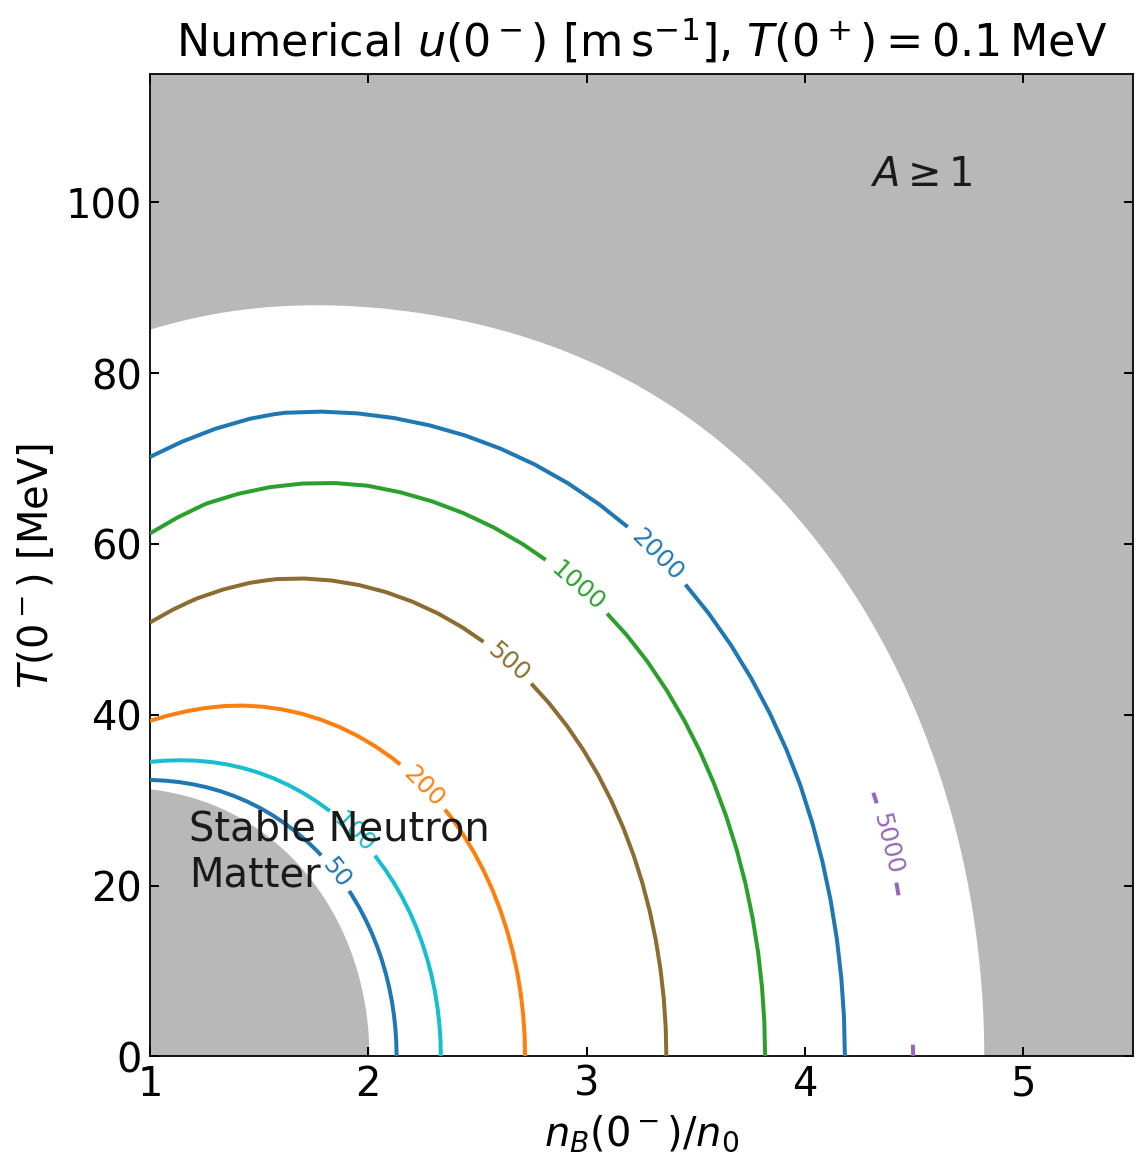

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
domain = np.load(root / CONTOUR_DOMAIN_PATH, allow_pickle=True).item()
full_numerical = np.load(root / FULL_NUMERICAL_PATH, allow_pickle=True).item()

calibration = domain["calibration"]
if not np.isclose(float(calibration["ncrit_over_n0"]), NCRIT_OVER_N0):
    raise RuntimeError(f"Expected nB_crit(0)={NCRIT_OVER_N0:g} n0, found {calibration['ncrit_over_n0']}")
temperature_axis = np.asarray(domain["T_0plus_values_MeV"], dtype=float)
numerical_temperature_axis = np.asarray(full_numerical["T_0plus_values_MeV"], dtype=float)
if temperature_axis.shape != (1,) or not np.isclose(temperature_axis[0], T0PLUS_MEV):
    raise RuntimeError(f"Expected only T(0+)={T0PLUS_MEV:g} MeV, found {temperature_axis}")
if not np.array_equal(numerical_temperature_axis, temperature_axis):
    raise RuntimeError("The numerical checkpoint does not share the fixed-T(0+) domain")

boundary = domain["boundary_diagnostics"]["semi_analytic"]
transform = domain["transform"]
density_origin = float(transform["density_origin_over_n0"])
density_scale = float(transform["density_scale_over_n0"])
temperature_scale = float(transform["temperature_scale_MeV"])

def boundary_curve(records):
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta_roots = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho_roots = np.asarray([row["rho"] for row in ordered], dtype=float)
    theta = np.linspace(theta_roots[0], theta_roots[-1], BOUNDARY_INTERPOLATION_SAMPLES)
    rho = np.interp(theta, theta_roots, rho_roots)
    density = density_origin+density_scale*rho*np.cos(theta)
    temperature = temperature_scale*rho*np.sin(theta)
    return density, temperature

A_density, A_temperature = boundary_curve(boundary["A_curve_records"])
gap_key = min(boundary["gap_curve_records_by_T0plus"], key=lambda value: abs(float(value)-T0PLUS_MEV))
inner_density, inner_temperature = boundary_curve(boundary["gap_curve_records_by_T0plus"][gap_key])
density = np.asarray(full_numerical["nB_0minus_over_n0_grid"], dtype=float)[:, :, 0]
temperature = np.asarray(full_numerical["T_0minus_MeV_grid"], dtype=float)[:, :, 0]
velocity = np.asarray(full_numerical["numerical_outward_u_0minus_m_s_grid"], dtype=float)[:, :, 0]
success = np.asarray(full_numerical["numerical_outward_success_grid"], dtype=bool)[:, :, 0]
masked_velocity = np.ma.masked_where(~success | ~np.isfinite(velocity), velocity)

figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI, constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
inner_polygon_x = np.concatenate((inner_density, (X_LIMITS[0], inner_density[0])))
inner_polygon_y = np.concatenate((inner_temperature, (Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
axis.fill(inner_polygon_x, inner_polygon_y, color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
A_polygon_x = np.concatenate((A_density, (X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], A_density[0])))
A_polygon_y = np.concatenate((A_temperature, (Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
axis.fill(A_polygon_x, A_polygon_y, color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)

numerical_contours = axis.contour(
    density,
    temperature,
    masked_velocity,
    levels=VELOCITY_CONTOUR_LEVELS_M_S,
    colors=VELOCITY_CONTOUR_COLORS,
    linestyles=VELOCITY_CONTOUR_LINE_STYLE,
    linewidths=VELOCITY_CONTOUR_LINE_WIDTH,
    corner_mask=False,
    zorder=CONTOUR_ZORDER,
)
axis.clabel(
    numerical_contours,
    inline=CONTOUR_LABEL_INLINE,
    fmt=CONTOUR_LABEL_FORMAT,
    fontsize=CONTOUR_LABEL_FONT_SIZE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
)
axis.text(*A_REGION_TEXT_POSITION, A_REGION_TEXT, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
axis.text(*INNER_REGION_TEXT_POSITION, INNER_REGION_TEXT, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
axis.set_xlim(*X_LIMITS)
axis.set_ylim(*Y_LIMITS_MEV)
axis.set_xscale(X_SCALE)
axis.set_yscale(Y_SCALE)
axis.set_box_aspect(BOX_ASPECT)
axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT, length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
for spine in axis.spines.values():
    spine.set_linewidth(SPINE_LINE_WIDTH)

output_png = root / OUTPUT_PNG
output_pdf = root / OUTPUT_PDF
output_png.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
figure.savefig(output_pdf, facecolor=BACKGROUND_COLOR)
print(f"Numerical cells available: {int(success.sum())}/{success.size}")
print(f"Checkpoint terminal cells: {int(full_numerical.get('completed_cell_count', success.sum()))}/{success.size}")
print(f"Saved {output_png}")
print(f"Saved {output_pdf}")
plt.show()

# Isothermal contours (2026-10-27 production)

Numerical speeds from `solve_front_isothermal_slow(initial_guess_mode="auto")` and analytical speeds from `analytic_velocity_isothermal_slow`, `RMFsolver` [v4.9.6]: massless quarks, QMC-RMF3 pure neutron matter, $\alpha_s=0.4$, revised Madsen rate, non-relativistic equations.
Above 10 MeV the points lie on a polar mesh between the two gray boundaries; below 10 MeV on 40 logarithmic temperature rows.
No point is evaluated inside a gray region, failed points stay holes, and contours are refined for display only.
The payloads live in `new_paper_calculations/26-10-27/isothermal/`; these cells call no solver.
Each figure cell writes PNG/PDF to `local_analysis_results/All_Plots_new/` and the PDF included by `Latex_writting/Main.tex` to `Latex_writting/Hydrodynamical combustion/Plots/`, so recompiling the manuscript picks up any change made here.

In [ ]:
from pathlib import Path
import sys
import numpy as np

ISO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "RMFsolver/phase_velocity.py").is_file())
ISO_WORKFLOW = ISO_ROOT / "new_paper_calculations/26-10-27/isothermal"
ISO_SCIPY_RUNTIME = ISO_ROOT / "local_analysis_results/26-10-02/runtime/scipy-1.18.1-cpython-312-darwin-arm64"
if "scipy" not in sys.modules and ISO_SCIPY_RUNTIME.is_dir():
    sys.path.insert(0, str(ISO_SCIPY_RUNTIME))   # the venv SciPy wheel does not load on macOS 27
for iso_path in (ISO_WORKFLOW, ISO_WORKFLOW / "highT"):
    if str(iso_path) not in sys.path:
        sys.path.insert(0, str(iso_path))
import _iso_common as iso_common
import _iso_plot as iso_plot
import _iso_xi as iso_xi
import build_boundary_curves as iso_boundary_curves

iso_payloads = {f"{method}_{panel}": iso_common.load(ISO_WORKFLOW / f"{panel}/isothermal-{panel}-{method}.npy")
                for method in ("numerical", "analytic") for panel in ("highT", "lowT")}
for panel in ("highT", "lowT"):
    numerical, analytic = iso_payloads[f"numerical_{panel}"], iso_payloads[f"analytic_{panel}"]
    assert numerical["mesh"]["fingerprint"] == analytic["mesh"]["fingerprint"], panel
    assert numerical["identity"]["sources"] == analytic["identity"]["sources"], panel
    for name, payload in (("numerical", numerical), ("analytic", analytic)):
        statuses = payload["status"].astype(str)
        print(f"{panel} {name}: { {s: int(np.sum(statuses == s)) for s in np.unique(statuses)} }")
iso_boundaries = iso_boundary_curves.load(iso_payloads["numerical_highT"]["mesh"]["boundaries"])
iso_xi_cache_lowT = iso_xi.build_cache(iso_payloads["analytic_lowT"])

highT numerical: {np.str_('accepted'): 2282, np.str_('outside_panel'): 58, np.str_('unresolved'): 9}
highT analytic: {np.str_('accepted'): 2291, np.str_('outside_panel'): 58}
lowT numerical: {np.str_('accepted'): 1314, np.str_('timeout'): 36, np.str_('unresolved'): 50}
lowT analytic: {np.str_('accepted'): 1400}


Saved local_analysis_results/All_Plots_new/isothermal-numerical-contour.png
Saved local_analysis_results/All_Plots_new/isothermal-numerical-contour.pdf
Saved Latex_writting/Hydrodynamical combustion/Plots/isothermal-numerical-contour.pdf


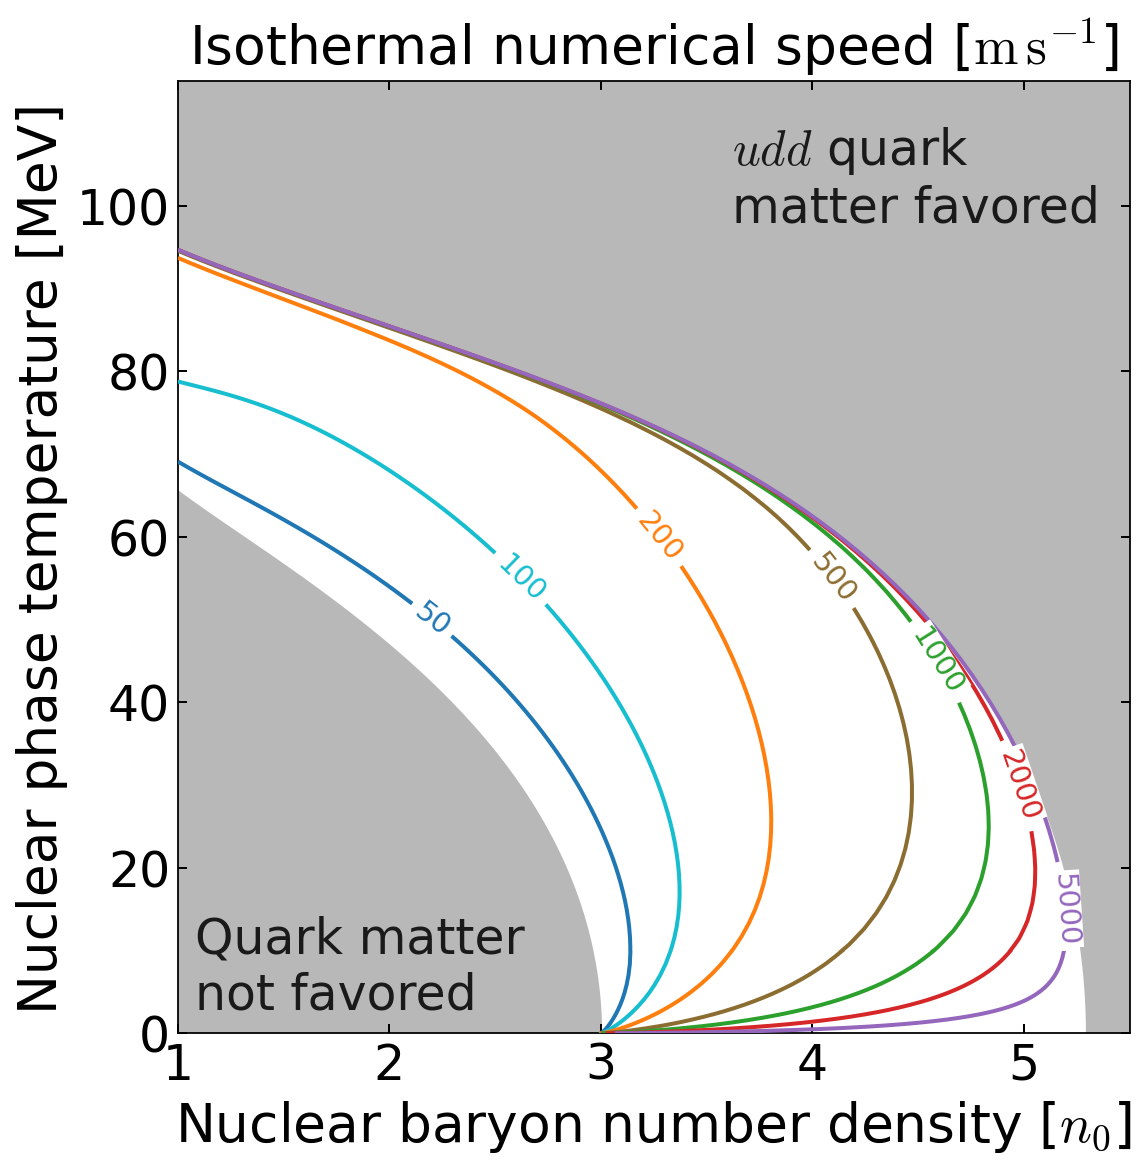

In [ ]:
# Tunable plotting parameters
# manuscript font standard, shared by every contour figure: at 7.2 in, 22 pt text, 24 pt axis labels
# and titles, 13 pt contour labels; a font prints at size * 246 / (72 * figure width) pt
ISO_LIN_VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
ISO_LIN_VELOCITY_CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#d62728', '#9467bd')
ISO_LIN_VELOCITY_CONTOUR_LINE_STYLE = '-'
ISO_LIN_VELOCITY_CONTOUR_LINE_WIDTH = 1.8
ISO_LIN_CONTOUR_LABEL_FONT_SIZE = 13
ISO_LIN_CONTOUR_LABEL_FORMAT = '%g'
ISO_LIN_CONTOUR_LABEL_INLINE = True
ISO_LIN_CONTOUR_LABEL_INLINE_SPACING = 4
ISO_LIN_CONTOUR_LABEL_BACKGROUND_COLOR = 'white'
ISO_LIN_CONTOUR_LABEL_BACKGROUND_PAD = 0.08
ISO_LIN_CONTOUR_LABEL_BACKGROUND_STYLE = 'square'
ISO_LIN_CONTOUR_LABEL_BACKGROUND_ALPHA = 1.0
ISO_LIN_CONTOUR_LABEL_TEMPERATURES_MEV = {50.0: 50.0, 100.0: 55.0, 200.0: 60.0, 500.0: 55.0, 1000.0: 45.0, 2000.0: 30.0, 5000.0: 15.0}
ISO_LIN_CONTOUR_ZORDER = 3
ISO_LIN_EXCLUDED_REGION_COLOR = '0.72'
ISO_LIN_EXCLUDED_REGION_ALPHA = 1.0
ISO_LIN_EXCLUDED_REGION_ZORDER = 0
ISO_LIN_OUTER_REGION_TEXT = '$udd$ quark\nmatter favored'
ISO_LIN_OUTER_REGION_TEXT_POSITION = (3.62, 98.0)
ISO_LIN_INNER_REGION_TEXT = 'Quark matter\nnot favored'
ISO_LIN_INNER_REGION_TEXT_POSITION = (1.08, 3.0)
ISO_LIN_REGION_TEXT_COLOR = '0.10'
ISO_LIN_REGION_TEXT_FONT_SIZE = 22
ISO_LIN_REGION_TEXT_ZORDER = 5
ISO_LIN_FIGURE_SIZE = (7.2, 7.2)
ISO_LIN_FIGURE_DPI = 160
ISO_LIN_EXPORT_DPI = 220
ISO_LIN_BACKGROUND_COLOR = 'white'
ISO_LIN_CONSTRAINED_LAYOUT = True
ISO_LIN_MATHTEXT_FONTSET = 'cm'
ISO_LIN_MATHTEXT_ROMAN = 'serif'
ISO_LIN_MATHTEXT_ITALIC = 'serif:italic'
ISO_LIN_MATHTEXT_BOLD = 'serif:bold'
ISO_LIN_X_LIMITS = (1.0, 5.5)
ISO_LIN_Y_LIMITS_MEV = (0.0, 115.0)
ISO_LIN_X_SCALE = 'linear'
ISO_LIN_Y_SCALE = 'linear'
ISO_LIN_BOX_ASPECT = 1.0
ISO_LIN_TITLE = 'Isothermal numerical speed [$\\mathrm{m\\,s^{-1}}$]'
ISO_LIN_TITLE_FONT_SIZE = 24
ISO_LIN_TITLE_PAD = 8
ISO_LIN_X_LABEL = 'Nuclear baryon number density [$n_0$]'
ISO_LIN_Y_LABEL = 'Nuclear phase temperature [MeV]'
ISO_LIN_AXIS_LABEL_FONT_SIZE = 24
ISO_LIN_TICK_LABEL_FONT_SIZE = 22
ISO_LIN_TICK_DIRECTION = 'in'
ISO_LIN_TICKS_TOP = True
ISO_LIN_TICKS_RIGHT = True
ISO_LIN_TICK_LENGTH = 4
ISO_LIN_TICK_WIDTH = 0.9
ISO_LIN_SPINE_LINE_WIDTH = 0.8
ISO_LIN_HIGH_T_CLIP_MEV = 10.0   # polar mesh above, row mesh below
ISO_LIN_RADIAL_UPSAMPLE = 8   # display-only PCHIP refinement along rays in -ln(1-f)
ISO_LIN_LOW_T_UPSAMPLE = 8    # display-only PCHIP refinement along rows in logit(f)
ISO_LIN_OUTPUT_PNG = "local_analysis_results/All_Plots_new/isothermal-numerical-contour.png"
ISO_LIN_OUTPUT_PDF = "local_analysis_results/All_Plots_new/isothermal-numerical-contour.pdf"
ISO_LIN_OUTPUT_LATEX_PDF = "Latex_writting/Hydrodynamical combustion/Plots/isothermal-numerical-contour.pdf"   # Fig. speed-isothermal-linear

import matplotlib as mpl
import matplotlib.pyplot as plt

iso_lin_style = {name[len("ISO_LIN_"):].lower(): value for name, value in list(globals().items())
                 if name.startswith("ISO_LIN_")}
iso_lin_figure, iso_lin_axis, iso_lin_rc = iso_plot.new_axes(iso_lin_style)
with mpl.rc_context(iso_lin_rc):
    iso_plot.draw_background(iso_lin_axis, iso_boundaries, iso_lin_style)
    iso_plot.draw_contours(iso_lin_axis, iso_payloads["numerical_highT"], T_range=(ISO_LIN_HIGH_T_CLIP_MEV, np.inf),
                           style=iso_lin_style, radial_upsample=ISO_LIN_RADIAL_UPSAMPLE)
    iso_plot.draw_row_contours(iso_lin_axis, iso_payloads["numerical_lowT"], ISO_LIN_VELOCITY_CONTOUR_LEVELS_M_S,
                               ISO_LIN_VELOCITY_CONTOUR_COLORS, ISO_LIN_VELOCITY_CONTOUR_LINE_STYLE,
                               ISO_LIN_VELOCITY_CONTOUR_LINE_WIDTH, ISO_LIN_CONTOUR_ZORDER,
                               T_range=(ISO_LIN_Y_LIMITS_MEV[0], ISO_LIN_HIGH_T_CLIP_MEV), x_limits=ISO_LIN_X_LIMITS,
                               radial_upsample=ISO_LIN_LOW_T_UPSAMPLE)
    iso_plot.finish_axes(iso_lin_axis, iso_lin_style)
    for iso_output, iso_dpi in ((ISO_LIN_OUTPUT_PNG, ISO_LIN_EXPORT_DPI), (ISO_LIN_OUTPUT_PDF, None),
                                (ISO_LIN_OUTPUT_LATEX_PDF, None)):
        (ISO_ROOT / iso_output).parent.mkdir(parents=True, exist_ok=True)
        iso_lin_figure.savefig(ISO_ROOT / iso_output, dpi=iso_dpi or "figure", facecolor=ISO_LIN_BACKGROUND_COLOR)
        print(f"Saved {iso_output}")
    plt.show()

# Isothermal numerical contour: logarithmic temperature

Row mesh only (0.01–10 MeV), full numerical speeds, half-decade levels labelled on the lines.

Saved local_analysis_results/All_Plots_new/isothermal-numerical-contour-logT.png
Saved local_analysis_results/All_Plots_new/isothermal-numerical-contour-logT.pdf
Saved Latex_writting/Hydrodynamical combustion/Plots/isothermal-numerical-contour-logT.pdf


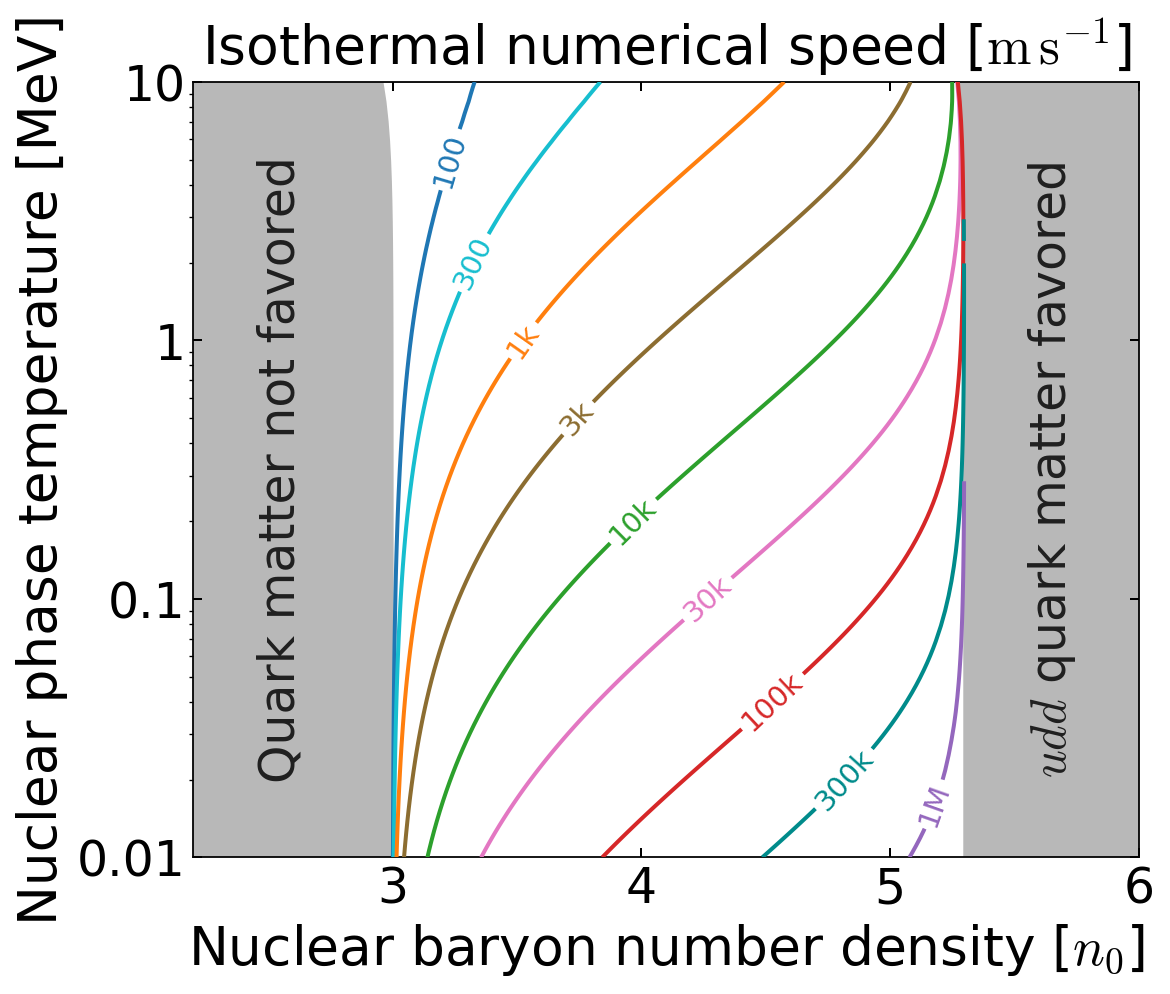

In [ ]:
# Tunable plotting parameters
# manuscript font standard, shared by every contour figure: at 7.2 in, 22 pt text, 24 pt axis labels
# and titles, 13 pt contour labels; a font prints at size * 246 / (72 * figure width) pt
ISO_LOGN_CONTOUR_LEVELS = (100.0, 300.0, 1000.0, 3000.0, 10000.0, 30000.0, 100000.0, 300000.0, 1000000.0)
ISO_LOGN_CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#e377c2', '#d62728', '#008b8b', '#9467bd')
ISO_LOGN_FIGURE_SIZE = (7.2, 6.2)
ISO_LOGN_FIGURE_DPI = 160
ISO_LOGN_EXPORT_DPI = 220
ISO_LOGN_CONSTRAINED_LAYOUT = True
ISO_LOGN_BACKGROUND_COLOR = 'white'
ISO_LOGN_FONT_FAMILY = 'DejaVu Sans'
ISO_LOGN_MATH_FONT_SET = 'cm'
ISO_LOGN_USE_TEX = False
ISO_LOGN_BOX_ASPECT = 0.82
ISO_LOGN_X_LIMITS = (2.2, 6.0)
ISO_LOGN_Y_LIMITS = (0.01, 10.0)
ISO_LOGN_X_SCALE = 'linear'
ISO_LOGN_Y_SCALE = 'log'
ISO_LOGN_X_TICKS = (3.0, 4.0, 5.0, 6.0)
ISO_LOGN_Y_TICKS = (0.01, 0.1, 1.0, 10.0)
ISO_LOGN_Y_TICK_LABELS = ('0.01', '0.1', '1', '10')
ISO_LOGN_TITLE = 'Isothermal numerical speed [$\\mathrm{m\\,s^{-1}}$]'
ISO_LOGN_TITLE_FONT_SIZE = 24
ISO_LOGN_TITLE_PAD = 8
ISO_LOGN_X_LABEL = 'Nuclear baryon number density [$n_0$]'
ISO_LOGN_Y_LABEL = 'Nuclear phase temperature [MeV]'
ISO_LOGN_AXIS_LABEL_FONT_SIZE = 24
ISO_LOGN_TICK_LABEL_FONT_SIZE = 22
ISO_LOGN_TICK_DIRECTION = 'in'
ISO_LOGN_TICKS_TOP = True
ISO_LOGN_TICKS_RIGHT = True
ISO_LOGN_TICK_LENGTH = 4
ISO_LOGN_TICK_WIDTH = 0.9
ISO_LOGN_SPINE_LINE_WIDTH = 0.8
ISO_LOGN_ANALYTICAL_LINE_STYLE = '--'
ISO_LOGN_NUMERICAL_LINE_STYLE = '-'
ISO_LOGN_LINE_WIDTH = 1.8
ISO_LOGN_ANALYTICAL_ZORDER = 4
ISO_LOGN_NUMERICAL_ZORDER = 3
ISO_LOGN_LABEL_CURVES = True
ISO_LOGN_CONTOUR_LABEL_FONT_SIZE = 13
ISO_LOGN_CONTOUR_LABEL_INLINE = True
ISO_LOGN_CONTOUR_LABEL_INLINE_SPACING = 4
ISO_LOGN_CONTOUR_LABEL_BACKGROUND_COLOR = 'white'
ISO_LOGN_CONTOUR_LABEL_BACKGROUND_ALPHA = 1.0
ISO_LOGN_CONTOUR_LABEL_BACKGROUND_PAD = 0.08
ISO_LOGN_CONTOUR_LABEL_BACKGROUND_STYLE = 'square'
ISO_LOGN_CONTOUR_LABEL_EDGE_COLOR = 'none'
ISO_LOGN_CONTOUR_LABEL_ZORDER = 6
ISO_LOGN_LABEL_TEMPERATURES = {100.0: 5.0, 300.0: 2.0, 1000.0: 1.0, 3000.0: 0.5, 10000.0: 0.2, 30000.0: 0.1, 100000.0: 0.04, 300000.0: 0.02, 1000000.0: 0.016}
ISO_LOGN_EXCLUDED_REGION_COLOR = '0.72'
ISO_LOGN_EXCLUDED_REGION_ALPHA = 1.0
ISO_LOGN_EXCLUDED_REGION_ZORDER = 0
ISO_LOGN_INNER_REGION_TEXT = 'Quark matter not favored'
ISO_LOGN_INNER_REGION_POSITION = (2.55, 0.316)
ISO_LOGN_INNER_REGION_ROTATION = 90
ISO_LOGN_INNER_REGION_ALIGNMENT = 'center'
ISO_LOGN_INNER_REGION_VERTICAL_ALIGNMENT = 'center'
ISO_LOGN_OUTER_REGION_TEXT = '$udd$ quark matter favored'
ISO_LOGN_OUTER_REGION_POSITION = (5.65, 0.316)
ISO_LOGN_OUTER_REGION_ROTATION = 90
ISO_LOGN_OUTER_REGION_ALIGNMENT = 'center'
ISO_LOGN_OUTER_REGION_VERTICAL_ALIGNMENT = 'center'
ISO_LOGN_REGION_TEXT_COLOR = '0.12'
ISO_LOGN_REGION_TEXT_FONT_SIZE = 22
ISO_LOGN_REGION_TEXT_ZORDER = 6
ISO_LOGN_LEGEND_LOCATION = 'upper left'
ISO_LOGN_LEGEND_FONT_SIZE = 22
ISO_LOGN_LEGEND_HANDLE_LENGTH = 1.0
ISO_LOGN_LEGEND_BORDER_AXES_PAD = 0.25
ISO_LOGN_LEGEND_FRAME_ALPHA = 0.94
ISO_LOGN_LEGEND_FACE_COLOR = 'white'
ISO_LOGN_LEGEND_EDGE_COLOR = '0.8'
ISO_LOGN_LEGEND_HANDLE_COLOR = '0.15'
ISO_LOGN_SHOW_METHOD_LEGEND = False
ISO_LOGN_LEGEND_ANCHOR = None
ISO_LOGN_LEGEND_COLUMNS = 1
ISO_LOGN_LEGEND_FRAME = True
ISO_LOGN_LEGEND_COLUMN_SPACING = 2.0
ISO_LOGN_LEGEND_HANDLE_TEXT_PAD = 0.8
ISO_LOGN_ANALYTICAL_LEGEND_LABEL = 'Analytical\n$\\xi={xi:g}$'
ISO_LOGN_SHOW_SPEED_LEGEND = False
ISO_LOGN_SPEED_LEGEND_LOCATION = 'lower left'
ISO_LOGN_SPEED_LEGEND_TITLE = '$u(0^-)$ [m s$^{-1}$]'
ISO_LOGN_SPEED_LEGEND_FONT_SIZE = 22
ISO_LOGN_SPEED_LEGEND_COLUMNS = 2
ISO_LOGN_SPEED_LEGEND_ANCHOR = (0.005, 0.005)
ISO_LOGN_SPEED_LEGEND_HANDLE_LENGTH = 1.3
ISO_LOGN_SPEED_LEGEND_COLUMN_SPACING = 0.7
ISO_LOGN_SPEED_LEGEND_HANDLE_TEXT_PAD = 0.4
ISO_LOGN_SPEED_LEGEND_LABEL_SPACING = 0.3
ISO_LOGN_SPEED_LABELS = ('100', '300', '1k', '3k', '10k', '30k', '100k', '300k', '1M')
ISO_LOGN_SHOW_GRID = False
ISO_LOGN_UPSAMPLE = 8    # display-only PCHIP refinement along rows in logit(f)
ISO_LOGN_OUTPUT_PNG = "local_analysis_results/All_Plots_new/isothermal-numerical-contour-logT.png"
ISO_LOGN_OUTPUT_PDF = "local_analysis_results/All_Plots_new/isothermal-numerical-contour-logT.pdf"
ISO_LOGN_OUTPUT_LATEX_PDF = "Latex_writting/Hydrodynamical combustion/Plots/isothermal-numerical-contour-logT.pdf"   # Fig. speed-isothermal-log

import matplotlib.pyplot as plt

iso_logn_style = {name[len("ISO_LOGN_"):].lower(): value for name, value in list(globals().items()) if name.startswith("ISO_LOGN_")}
iso_logn_lines = {"numerical": iso_plot.contour_lines(*iso_plot.contour_arrays(iso_payloads["numerical_lowT"], ISO_LOGN_UPSAMPLE,
                                                                           "logit"), ISO_LOGN_CONTOUR_LEVELS, log_T=True)}
iso_logn_lines["analytic"] = {}
iso_logn_xi = None

with plt.rc_context({"font.family": ISO_LOGN_FONT_FAMILY, "mathtext.fontset": ISO_LOGN_MATH_FONT_SET, "text.usetex": ISO_LOGN_USE_TEX}):
    iso_logn_figure, iso_logn_axis = plt.subplots(figsize=ISO_LOGN_FIGURE_SIZE, dpi=ISO_LOGN_FIGURE_DPI,
                                        constrained_layout=ISO_LOGN_CONSTRAINED_LAYOUT, facecolor=ISO_LOGN_BACKGROUND_COLOR)
    iso_logn_axis.set_facecolor(ISO_LOGN_BACKGROUND_COLOR)
    iso_plot.draw_log_reference(iso_logn_axis, iso_boundaries, iso_logn_lines["numerical"], iso_logn_lines["analytic"], iso_logn_xi,
                                iso_logn_style)
    for iso_output, iso_dpi in ((ISO_LOGN_OUTPUT_PNG, ISO_LOGN_EXPORT_DPI), (ISO_LOGN_OUTPUT_PDF, None), (ISO_LOGN_OUTPUT_LATEX_PDF, None)):
        (ISO_ROOT / iso_output).parent.mkdir(parents=True, exist_ok=True)
        iso_logn_figure.savefig(ISO_ROOT / iso_output, dpi=iso_dpi or "figure", facecolor=ISO_LOGN_BACKGROUND_COLOR)
        print(f"Saved {iso_output}")
    plt.show()

# Isothermal contour: analytical versus numerical, logarithmic temperature

Numerical solid, analytical dashed, same levels and labels as above.
The analytical speed is rescaled exactly from the saved intermediates at `ISO_CMP_XI`, the contour fit for 0.01–10 MeV ($\xi=-0.57$, `wiki/methods/isothermal-xi-fit.md`); the adiabatic appendix value $\xi=-0.85$ leaves three times the contour offset here.
Same axes box and x range as the numerical panel above, with the method legend between the title and the axes.

Saved local_analysis_results/All_Plots_new/isothermal-analytic-numerical-logT.png
Saved local_analysis_results/All_Plots_new/isothermal-analytic-numerical-logT.pdf
Saved Latex_writting/Hydrodynamical combustion/Plots/isothermal-analytic-numerical-logT.pdf


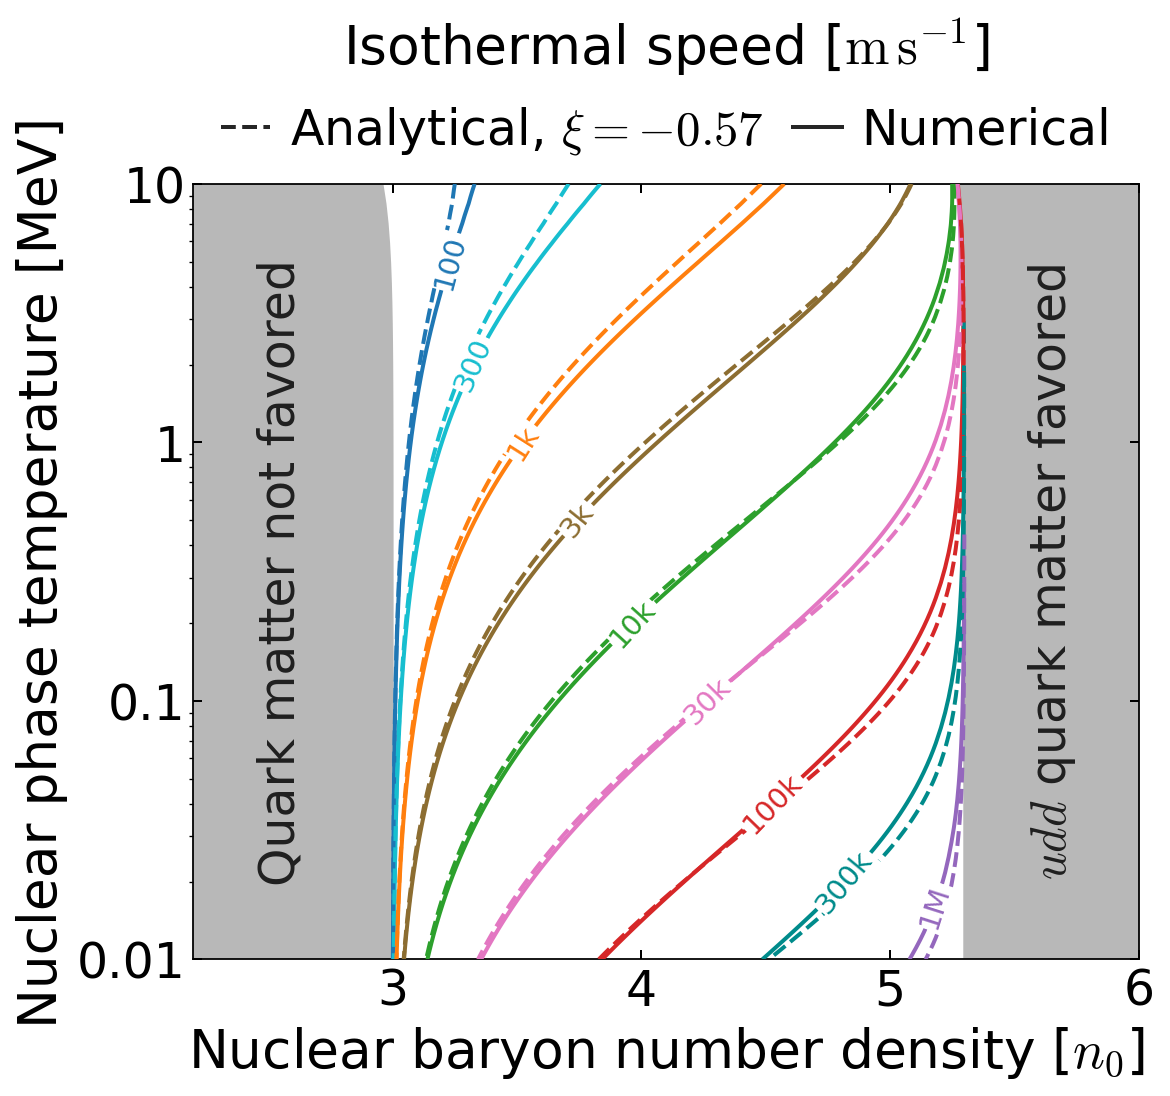

In [ ]:
# Tunable plotting parameters
# manuscript font standard, shared by every contour figure: at 7.2 in, 22 pt text, 24 pt axis labels
# and titles, 13 pt contour labels; a font prints at size * 246 / (72 * figure width) pt
ISO_CMP_CONTOUR_LEVELS = (100.0, 300.0, 1000.0, 3000.0, 10000.0, 30000.0, 100000.0, 300000.0, 1000000.0)
ISO_CMP_CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#e377c2', '#d62728', '#008b8b', '#9467bd')
ISO_CMP_FIGURE_SIZE = (7.2, 6.85)
ISO_CMP_FIGURE_DPI = 160
ISO_CMP_EXPORT_DPI = 220
ISO_CMP_CONSTRAINED_LAYOUT = True
ISO_CMP_BACKGROUND_COLOR = 'white'
ISO_CMP_FONT_FAMILY = 'DejaVu Sans'
ISO_CMP_MATH_FONT_SET = 'cm'
ISO_CMP_USE_TEX = False
ISO_CMP_BOX_ASPECT = 0.82
ISO_CMP_X_LIMITS = (2.2, 6.0)
ISO_CMP_Y_LIMITS = (0.01, 10.0)
ISO_CMP_X_SCALE = 'linear'
ISO_CMP_Y_SCALE = 'log'
ISO_CMP_X_TICKS = (3.0, 4.0, 5.0, 6.0)
ISO_CMP_Y_TICKS = (0.01, 0.1, 1.0, 10.0)
ISO_CMP_Y_TICK_LABELS = ('0.01', '0.1', '1', '10')
ISO_CMP_TITLE = 'Isothermal speed [$\\mathrm{m\\,s^{-1}}$]'
ISO_CMP_TITLE_FONT_SIZE = 24
ISO_CMP_TITLE_PAD = 54
ISO_CMP_X_LABEL = 'Nuclear baryon number density [$n_0$]'
ISO_CMP_Y_LABEL = 'Nuclear phase temperature [MeV]'
ISO_CMP_AXIS_LABEL_FONT_SIZE = 24
ISO_CMP_TICK_LABEL_FONT_SIZE = 22
ISO_CMP_TICK_DIRECTION = 'in'
ISO_CMP_TICKS_TOP = True
ISO_CMP_TICKS_RIGHT = True
ISO_CMP_TICK_LENGTH = 4
ISO_CMP_TICK_WIDTH = 0.9
ISO_CMP_SPINE_LINE_WIDTH = 0.8
ISO_CMP_ANALYTICAL_LINE_STYLE = '--'
ISO_CMP_NUMERICAL_LINE_STYLE = '-'
ISO_CMP_LINE_WIDTH = 1.8
ISO_CMP_ANALYTICAL_ZORDER = 4
ISO_CMP_NUMERICAL_ZORDER = 3
ISO_CMP_LABEL_CURVES = True
ISO_CMP_CONTOUR_LABEL_FONT_SIZE = 13
ISO_CMP_CONTOUR_LABEL_INLINE = True
ISO_CMP_CONTOUR_LABEL_INLINE_SPACING = 4
ISO_CMP_CONTOUR_LABEL_BACKGROUND_COLOR = 'white'
ISO_CMP_CONTOUR_LABEL_BACKGROUND_ALPHA = 1.0
ISO_CMP_CONTOUR_LABEL_BACKGROUND_PAD = 0.08
ISO_CMP_CONTOUR_LABEL_BACKGROUND_STYLE = 'square'
ISO_CMP_CONTOUR_LABEL_EDGE_COLOR = 'none'
ISO_CMP_CONTOUR_LABEL_ZORDER = 6
ISO_CMP_LABEL_TEMPERATURES = {100.0: 5.0, 300.0: 2.0, 1000.0: 1.0, 3000.0: 0.5, 10000.0: 0.2, 30000.0: 0.1, 100000.0: 0.04, 300000.0: 0.02, 1000000.0: 0.016}
ISO_CMP_EXCLUDED_REGION_COLOR = '0.72'
ISO_CMP_EXCLUDED_REGION_ALPHA = 1.0
ISO_CMP_EXCLUDED_REGION_ZORDER = 0
ISO_CMP_INNER_REGION_TEXT = 'Quark matter not favored'
ISO_CMP_INNER_REGION_POSITION = (2.55, 0.316)
ISO_CMP_INNER_REGION_ROTATION = 90
ISO_CMP_INNER_REGION_ALIGNMENT = 'center'
ISO_CMP_INNER_REGION_VERTICAL_ALIGNMENT = 'center'
ISO_CMP_OUTER_REGION_TEXT = '$udd$ quark matter favored'
ISO_CMP_OUTER_REGION_POSITION = (5.65, 0.316)
ISO_CMP_OUTER_REGION_ROTATION = 90
ISO_CMP_OUTER_REGION_ALIGNMENT = 'center'
ISO_CMP_OUTER_REGION_VERTICAL_ALIGNMENT = 'center'
ISO_CMP_REGION_TEXT_COLOR = '0.12'
ISO_CMP_REGION_TEXT_FONT_SIZE = 22
ISO_CMP_REGION_TEXT_ZORDER = 6
ISO_CMP_LEGEND_LOCATION = 'lower center'
ISO_CMP_LEGEND_FONT_SIZE = 22
ISO_CMP_LEGEND_HANDLE_LENGTH = 1.0
ISO_CMP_LEGEND_BORDER_AXES_PAD = 0.15
ISO_CMP_LEGEND_FRAME_ALPHA = 0.94
ISO_CMP_LEGEND_FACE_COLOR = 'white'
ISO_CMP_LEGEND_EDGE_COLOR = '0.8'
ISO_CMP_LEGEND_HANDLE_COLOR = '0.15'
ISO_CMP_SHOW_METHOD_LEGEND = True
ISO_CMP_LEGEND_ANCHOR = (0.5, 1.0)
ISO_CMP_LEGEND_COLUMNS = 2
ISO_CMP_LEGEND_FRAME = False
ISO_CMP_LEGEND_COLUMN_SPACING = 0.6
ISO_CMP_LEGEND_HANDLE_TEXT_PAD = 0.4
ISO_CMP_ANALYTICAL_LEGEND_LABEL = 'Analytical, $\\xi={xi:g}$'
ISO_CMP_SHOW_SPEED_LEGEND = False
ISO_CMP_SPEED_LEGEND_LOCATION = 'lower left'
ISO_CMP_SPEED_LEGEND_TITLE = '$u(0^-)$ [m s$^{-1}$]'
ISO_CMP_SPEED_LEGEND_FONT_SIZE = 22
ISO_CMP_SPEED_LEGEND_COLUMNS = 2
ISO_CMP_SPEED_LEGEND_ANCHOR = (0.005, 0.005)
ISO_CMP_SPEED_LEGEND_HANDLE_LENGTH = 1.3
ISO_CMP_SPEED_LEGEND_COLUMN_SPACING = 0.7
ISO_CMP_SPEED_LEGEND_HANDLE_TEXT_PAD = 0.4
ISO_CMP_SPEED_LEGEND_LABEL_SPACING = 0.3
ISO_CMP_SPEED_LABELS = ('100', '300', '1k', '3k', '10k', '30k', '100k', '300k', '1M')
ISO_CMP_SHOW_GRID = False
ISO_CMP_XI = -0.57   # contour fit for 0.01-10 MeV (xi_fit/xi_fit.json)
ISO_CMP_UPSAMPLE = 8    # display-only PCHIP refinement along rows in logit(f)
ISO_CMP_OUTPUT_PNG = "local_analysis_results/All_Plots_new/isothermal-analytic-numerical-logT.png"
ISO_CMP_OUTPUT_PDF = "local_analysis_results/All_Plots_new/isothermal-analytic-numerical-logT.pdf"
ISO_CMP_OUTPUT_LATEX_PDF = "Latex_writting/Hydrodynamical combustion/Plots/isothermal-analytic-numerical-logT.pdf"   # Fig. isothermal-contour-compare

import matplotlib.pyplot as plt

iso_cmp_style = {name[len("ISO_CMP_"):].lower(): value for name, value in list(globals().items()) if name.startswith("ISO_CMP_")}
iso_cmp_lines = {"numerical": iso_plot.contour_lines(*iso_plot.contour_arrays(iso_payloads["numerical_lowT"], ISO_CMP_UPSAMPLE,
                                                                           "logit"), ISO_CMP_CONTOUR_LEVELS, log_T=True)}
iso_cmp_analytic = dict(iso_payloads["analytic_lowT"], speed_m_s=iso_xi.retune(iso_xi_cache_lowT, ISO_CMP_XI))
iso_cmp_lines["analytic"] = iso_plot.contour_lines(*iso_plot.contour_arrays(iso_cmp_analytic, ISO_CMP_UPSAMPLE, "logit"),
                                               ISO_CMP_CONTOUR_LEVELS, log_T=True)
iso_cmp_xi = ISO_CMP_XI

with plt.rc_context({"font.family": ISO_CMP_FONT_FAMILY, "mathtext.fontset": ISO_CMP_MATH_FONT_SET, "text.usetex": ISO_CMP_USE_TEX}):
    iso_cmp_figure, iso_cmp_axis = plt.subplots(figsize=ISO_CMP_FIGURE_SIZE, dpi=ISO_CMP_FIGURE_DPI,
                                        constrained_layout=ISO_CMP_CONSTRAINED_LAYOUT, facecolor=ISO_CMP_BACKGROUND_COLOR)
    iso_cmp_axis.set_facecolor(ISO_CMP_BACKGROUND_COLOR)
    iso_plot.draw_log_reference(iso_cmp_axis, iso_boundaries, iso_cmp_lines["numerical"], iso_cmp_lines["analytic"], iso_cmp_xi,
                                iso_cmp_style)
    for iso_output, iso_dpi in ((ISO_CMP_OUTPUT_PNG, ISO_CMP_EXPORT_DPI), (ISO_CMP_OUTPUT_PDF, None), (ISO_CMP_OUTPUT_LATEX_PDF, None)):
        (ISO_ROOT / iso_output).parent.mkdir(parents=True, exist_ok=True)
        iso_cmp_figure.savefig(ISO_ROOT / iso_output, dpi=iso_dpi or "figure", facecolor=ISO_CMP_BACKGROUND_COLOR)
        print(f"Saved {iso_output}")
    plt.show()

# Isothermal contour: analytical at the fitted $\xi$ versus numerical

As above, with `ISO_FIT_XI` set to the contour fit for 0.01–10 MeV (`xi_fit/xi_fit.json`), where the analytical contours nearly sit on the numerical ones.

Saved local_analysis_results/All_Plots_new/isothermal-analytical-numerical-comparison.png
Saved local_analysis_results/All_Plots_new/isothermal-analytical-numerical-comparison.pdf
Saved Latex_writting/Hydrodynamical combustion/Plots/isothermal-analytical-numerical-comparison.pdf


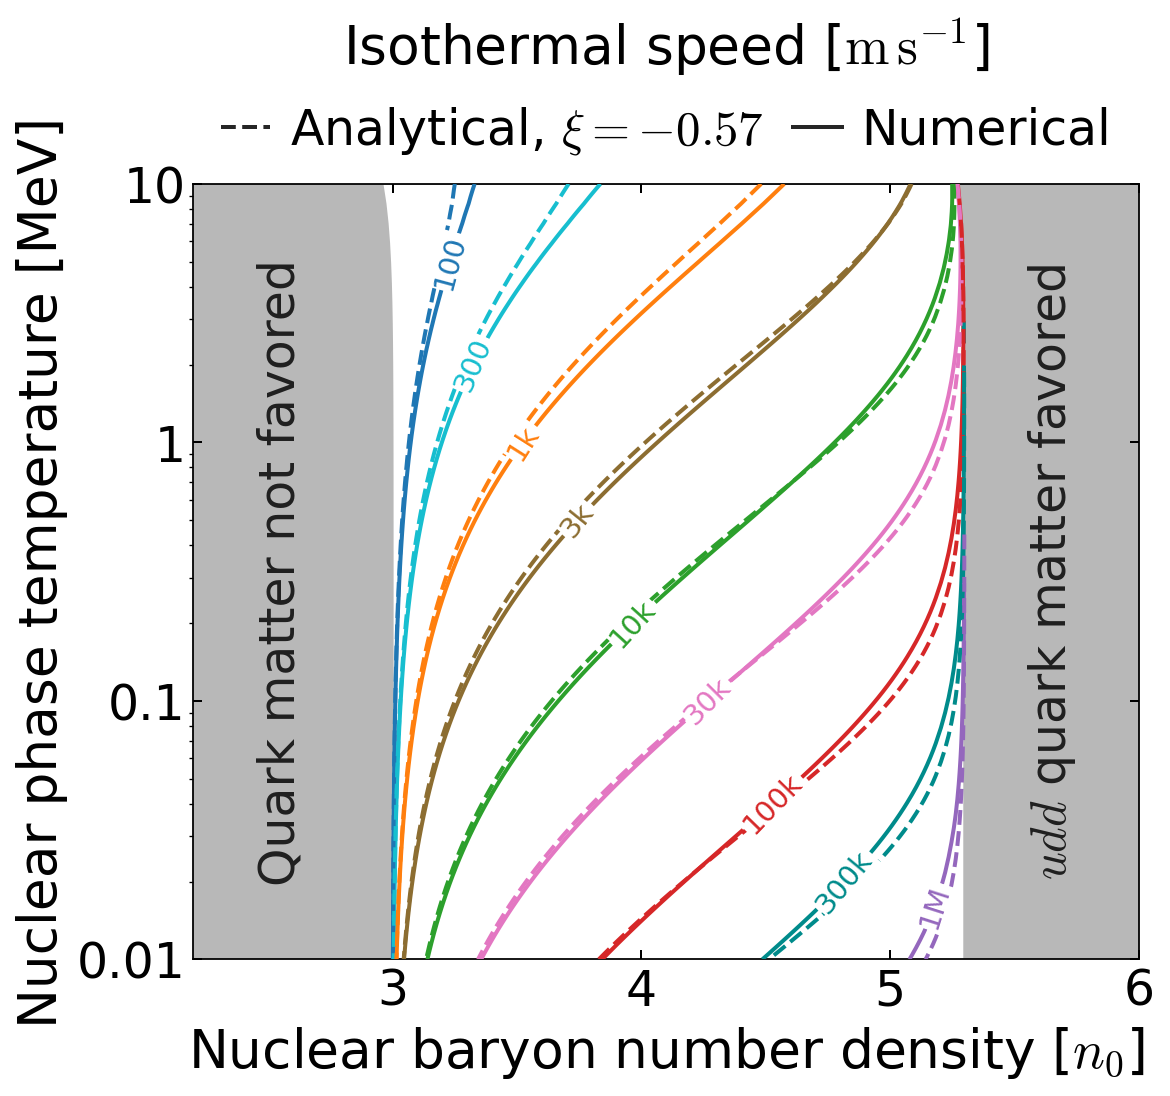

In [ ]:
# Tunable plotting parameters
# manuscript font standard, shared by every contour figure: at 7.2 in, 22 pt text, 24 pt axis labels
# and titles, 13 pt contour labels; a font prints at size * 246 / (72 * figure width) pt
ISO_FIT_CONTOUR_LEVELS = (100.0, 300.0, 1000.0, 3000.0, 10000.0, 30000.0, 100000.0, 300000.0, 1000000.0)
ISO_FIT_CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#e377c2', '#d62728', '#008b8b', '#9467bd')
ISO_FIT_FIGURE_SIZE = (7.2, 6.85)
ISO_FIT_FIGURE_DPI = 160
ISO_FIT_EXPORT_DPI = 220
ISO_FIT_CONSTRAINED_LAYOUT = True
ISO_FIT_BACKGROUND_COLOR = 'white'
ISO_FIT_FONT_FAMILY = 'DejaVu Sans'
ISO_FIT_MATH_FONT_SET = 'cm'
ISO_FIT_USE_TEX = False
ISO_FIT_BOX_ASPECT = 0.82
ISO_FIT_X_LIMITS = (2.2, 6.0)
ISO_FIT_Y_LIMITS = (0.01, 10.0)
ISO_FIT_X_SCALE = 'linear'
ISO_FIT_Y_SCALE = 'log'
ISO_FIT_X_TICKS = (3.0, 4.0, 5.0, 6.0)
ISO_FIT_Y_TICKS = (0.01, 0.1, 1.0, 10.0)
ISO_FIT_Y_TICK_LABELS = ('0.01', '0.1', '1', '10')
ISO_FIT_TITLE = 'Isothermal speed [$\\mathrm{m\\,s^{-1}}$]'
ISO_FIT_TITLE_FONT_SIZE = 24
ISO_FIT_TITLE_PAD = 54
ISO_FIT_X_LABEL = 'Nuclear baryon number density [$n_0$]'
ISO_FIT_Y_LABEL = 'Nuclear phase temperature [MeV]'
ISO_FIT_AXIS_LABEL_FONT_SIZE = 24
ISO_FIT_TICK_LABEL_FONT_SIZE = 22
ISO_FIT_TICK_DIRECTION = 'in'
ISO_FIT_TICKS_TOP = True
ISO_FIT_TICKS_RIGHT = True
ISO_FIT_TICK_LENGTH = 4
ISO_FIT_TICK_WIDTH = 0.9
ISO_FIT_SPINE_LINE_WIDTH = 0.8
ISO_FIT_ANALYTICAL_LINE_STYLE = '--'
ISO_FIT_NUMERICAL_LINE_STYLE = '-'
ISO_FIT_LINE_WIDTH = 1.8
ISO_FIT_ANALYTICAL_ZORDER = 4
ISO_FIT_NUMERICAL_ZORDER = 3
ISO_FIT_LABEL_CURVES = True
ISO_FIT_CONTOUR_LABEL_FONT_SIZE = 13
ISO_FIT_CONTOUR_LABEL_INLINE = True
ISO_FIT_CONTOUR_LABEL_INLINE_SPACING = 4
ISO_FIT_CONTOUR_LABEL_BACKGROUND_COLOR = 'white'
ISO_FIT_CONTOUR_LABEL_BACKGROUND_ALPHA = 1.0
ISO_FIT_CONTOUR_LABEL_BACKGROUND_PAD = 0.08
ISO_FIT_CONTOUR_LABEL_BACKGROUND_STYLE = 'square'
ISO_FIT_CONTOUR_LABEL_EDGE_COLOR = 'none'
ISO_FIT_CONTOUR_LABEL_ZORDER = 6
ISO_FIT_LABEL_TEMPERATURES = {100.0: 5.0, 300.0: 2.0, 1000.0: 1.0, 3000.0: 0.5, 10000.0: 0.2, 30000.0: 0.1, 100000.0: 0.04, 300000.0: 0.02, 1000000.0: 0.016}
ISO_FIT_EXCLUDED_REGION_COLOR = '0.72'
ISO_FIT_EXCLUDED_REGION_ALPHA = 1.0
ISO_FIT_EXCLUDED_REGION_ZORDER = 0
ISO_FIT_INNER_REGION_TEXT = 'Quark matter not favored'
ISO_FIT_INNER_REGION_POSITION = (2.55, 0.316)
ISO_FIT_INNER_REGION_ROTATION = 90
ISO_FIT_INNER_REGION_ALIGNMENT = 'center'
ISO_FIT_INNER_REGION_VERTICAL_ALIGNMENT = 'center'
ISO_FIT_OUTER_REGION_TEXT = '$udd$ quark matter favored'
ISO_FIT_OUTER_REGION_POSITION = (5.65, 0.316)
ISO_FIT_OUTER_REGION_ROTATION = 90
ISO_FIT_OUTER_REGION_ALIGNMENT = 'center'
ISO_FIT_OUTER_REGION_VERTICAL_ALIGNMENT = 'center'
ISO_FIT_REGION_TEXT_COLOR = '0.12'
ISO_FIT_REGION_TEXT_FONT_SIZE = 22
ISO_FIT_REGION_TEXT_ZORDER = 6
ISO_FIT_LEGEND_LOCATION = 'lower center'
ISO_FIT_LEGEND_FONT_SIZE = 22
ISO_FIT_LEGEND_HANDLE_LENGTH = 1.0
ISO_FIT_LEGEND_BORDER_AXES_PAD = 0.15
ISO_FIT_LEGEND_FRAME_ALPHA = 0.94
ISO_FIT_LEGEND_FACE_COLOR = 'white'
ISO_FIT_LEGEND_EDGE_COLOR = '0.8'
ISO_FIT_LEGEND_HANDLE_COLOR = '0.15'
ISO_FIT_SHOW_METHOD_LEGEND = True
ISO_FIT_LEGEND_ANCHOR = (0.5, 1.0)
ISO_FIT_LEGEND_COLUMNS = 2
ISO_FIT_LEGEND_FRAME = False
ISO_FIT_LEGEND_COLUMN_SPACING = 0.6
ISO_FIT_LEGEND_HANDLE_TEXT_PAD = 0.4
ISO_FIT_ANALYTICAL_LEGEND_LABEL = 'Analytical, $\\xi={xi:g}$'
ISO_FIT_SHOW_SPEED_LEGEND = False
ISO_FIT_SPEED_LEGEND_LOCATION = 'lower left'
ISO_FIT_SPEED_LEGEND_TITLE = '$u(0^-)$ [m s$^{-1}$]'
ISO_FIT_SPEED_LEGEND_FONT_SIZE = 22
ISO_FIT_SPEED_LEGEND_COLUMNS = 2
ISO_FIT_SPEED_LEGEND_ANCHOR = (0.005, 0.005)
ISO_FIT_SPEED_LEGEND_HANDLE_LENGTH = 1.3
ISO_FIT_SPEED_LEGEND_COLUMN_SPACING = 0.7
ISO_FIT_SPEED_LEGEND_HANDLE_TEXT_PAD = 0.4
ISO_FIT_SPEED_LEGEND_LABEL_SPACING = 0.3
ISO_FIT_SPEED_LABELS = ('100', '300', '1k', '3k', '10k', '30k', '100k', '300k', '1M')
ISO_FIT_SHOW_GRID = False
ISO_FIT_XI = -0.57   # contour fit for 0.01-10 MeV (xi_fit/xi_fit.json)
ISO_FIT_UPSAMPLE = 8    # display-only PCHIP refinement along rows in logit(f)
ISO_FIT_OUTPUT_PNG = "local_analysis_results/All_Plots_new/isothermal-analytical-numerical-comparison.png"
ISO_FIT_OUTPUT_PDF = "local_analysis_results/All_Plots_new/isothermal-analytical-numerical-comparison.pdf"
ISO_FIT_OUTPUT_LATEX_PDF = "Latex_writting/Hydrodynamical combustion/Plots/isothermal-analytical-numerical-comparison.pdf"   # fitted-xi comparison

import matplotlib.pyplot as plt

iso_fit_style = {name[len("ISO_FIT_"):].lower(): value for name, value in list(globals().items()) if name.startswith("ISO_FIT_")}
iso_fit_lines = {"numerical": iso_plot.contour_lines(*iso_plot.contour_arrays(iso_payloads["numerical_lowT"], ISO_FIT_UPSAMPLE,
                                                                           "logit"), ISO_FIT_CONTOUR_LEVELS, log_T=True)}
iso_fit_analytic = dict(iso_payloads["analytic_lowT"], speed_m_s=iso_xi.retune(iso_xi_cache_lowT, ISO_FIT_XI))
iso_fit_lines["analytic"] = iso_plot.contour_lines(*iso_plot.contour_arrays(iso_fit_analytic, ISO_FIT_UPSAMPLE, "logit"),
                                               ISO_FIT_CONTOUR_LEVELS, log_T=True)
iso_fit_xi = ISO_FIT_XI

with plt.rc_context({"font.family": ISO_FIT_FONT_FAMILY, "mathtext.fontset": ISO_FIT_MATH_FONT_SET, "text.usetex": ISO_FIT_USE_TEX}):
    iso_fit_figure, iso_fit_axis = plt.subplots(figsize=ISO_FIT_FIGURE_SIZE, dpi=ISO_FIT_FIGURE_DPI,
                                        constrained_layout=ISO_FIT_CONSTRAINED_LAYOUT, facecolor=ISO_FIT_BACKGROUND_COLOR)
    iso_fit_axis.set_facecolor(ISO_FIT_BACKGROUND_COLOR)
    iso_plot.draw_log_reference(iso_fit_axis, iso_boundaries, iso_fit_lines["numerical"], iso_fit_lines["analytic"], iso_fit_xi,
                                iso_fit_style)
    for iso_output, iso_dpi in ((ISO_FIT_OUTPUT_PNG, ISO_FIT_EXPORT_DPI), (ISO_FIT_OUTPUT_PDF, None), (ISO_FIT_OUTPUT_LATEX_PDF, None)):
        (ISO_ROOT / iso_output).parent.mkdir(parents=True, exist_ok=True)
        iso_fit_figure.savefig(ISO_ROOT / iso_output, dpi=iso_dpi or "figure", facecolor=ISO_FIT_BACKGROUND_COLOR)
        print(f"Saved {iso_output}")
    plt.show()

# GW signal section

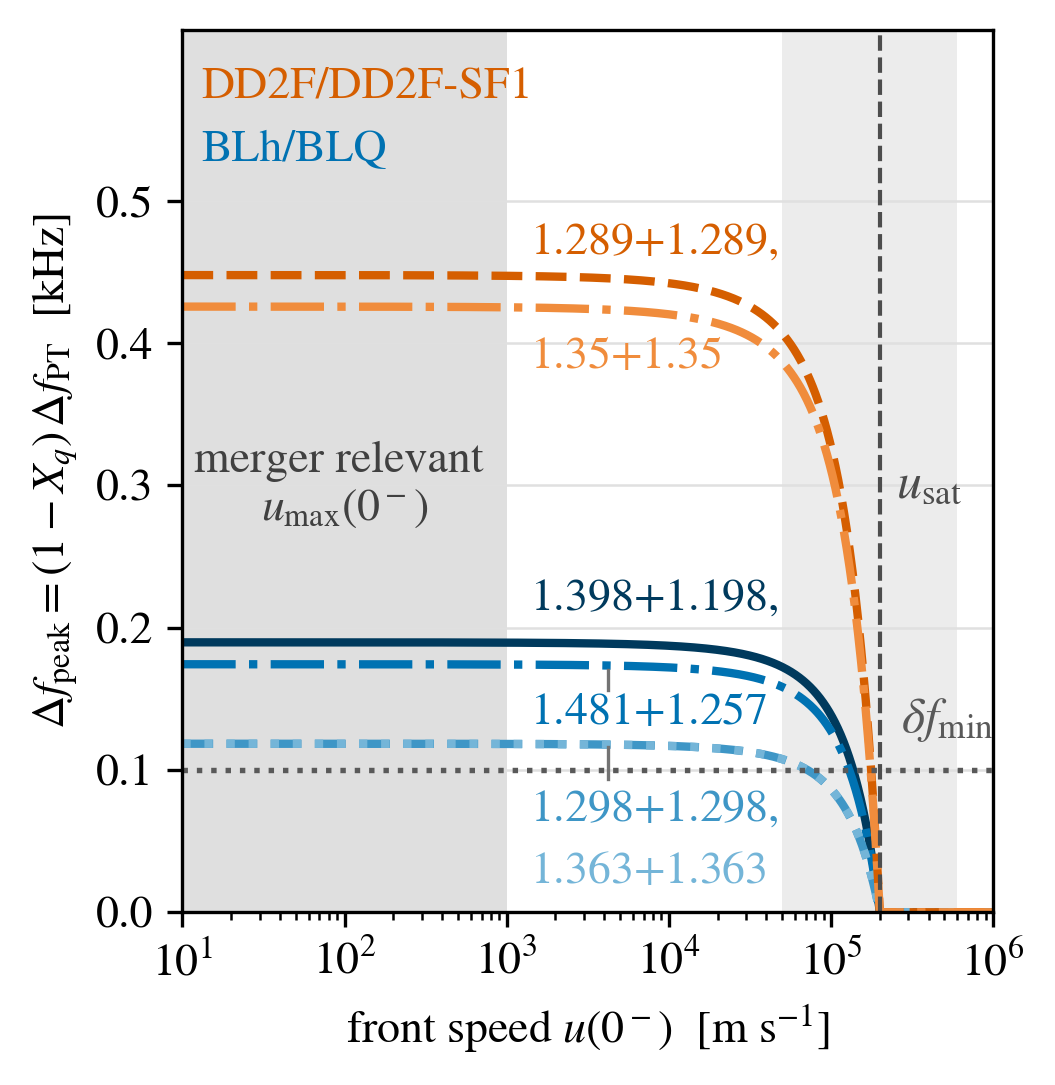

wrote Latex_writting/Hydrodynamical combustion/Plots/.pdf/.png


In [ ]:
# GW-section figure: finite-rate frequency deficit for simulation-calibrated
# Delta_f_PT. Five cases (all BLh/BLQ + DD2F/DD2F-SF1 1.289+1.289) are from
# Table IV of Prakash+ arXiv:2310.06025; the DD2F/DD2F-SF1 1.35+1.35 case is
# from Bauswein+ arXiv:1809.01116. A second Bauswein+ case (q=0.8) was dropped:
# its m1,m2 split could not be verified, see comment at DD2F_CASES below.
# Uses the paper's two-lobed (taiji) geometry:
# X_q = min(1, ((R_0 + u*Delta_t_pm)/R_lobe)^3).
# Design: no boxed legend; color = EOS family, direct mass tags on plateaus,
# dotted delta_f_min guide. All text >= 10 pt for 1:1 columnwidth inclusion.
# Run from the repo root; writes the PDF used by the v2 drop-in section.
import numpy as np
import matplotlib.pyplot as plt

# Tunable plotting parameters
FIGURE_SIZE = (3.4, 3.5)
DPI = 300
FONT_FAMILY = "STIXGeneral"
MATH_FONTSET = "stix"
AXIS_LABEL_FONT_SIZE = 11
TICK_LABEL_FONT_SIZE = 11
TAG_FONT_SIZE = 11
FAMILY_FONT_SIZE = 11
ANNOTATION_FONT_SIZE = 11
LINE_WIDTH = 2.0
BLH_SHADES = ["#003A5D", "#0072B2", "#3E96C6", "#74B5D8"]   # dark -> light
DD2F_SHADES = ["#8A3D00", "#D55E00", "#F08C3C"]
BLH_ANCHOR = "#0072B2"
DD2F_ANCHOR = "#D55E00"
BAND_COLOR = "0.55"
BAND_ALPHA = 0.28
U_MAX_BAND = (1.0e1, 1.0e3)     # merger-relevant weak-limited u(0^-) range, m/s
DFMIN_KHZ = 0.10                # next-generation resolution (Clark+, Breschi+)
DFMIN_COLOR = "0.35"
DFMIN_STYLE = ":"
DFMIN_WIDTH = 1.3
VLINE_COLOR = "0.3"
VLINE_STYLE = "--"
VLINE_WIDTH = 1.0
GRID_COLOR = "0.88"
GRID_LINE_WIDTH = 0.6
X_LIMITS = (1.0e1, 1.0e6)
Y_LIMITS = (0.0, 0.62)
Y_TICKS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
LEADER_COLOR = "0.45"
LEADER_WIDTH = 0.8
N_SPEED_SAMPLES = 2000
OUTPUT_STEM = "Latex_writting/Hydrodynamical combustion/Plots/"
OUTPUT_STEM_2 = "Latex_drop_in_integrated/v2/Plots/"

# Model parameters (paper reference values)
R0_M = 1000.0                   # pre-merger quark-core radius R_0 (fiducial)
R_LOBE_M = 3000.0               # effective lobe radius R_lobe (fiducial)
DT_PM_S = 10.0e-3               # postmerger emission window (fiducial)
# Geometry is NOT known per binary (Prakash+ and Bauswein+ quote no core radii),
# so one fiducial geometry is applied to all seven cases: X_q(u) is then common
# and Delta_f_PT only rescales each curve vertically. The band below shows how
# far u_sat would move over the plausible geometry range.
R_LOBE_RANGE_M = (2000.0, 4000.0)   # "a few km" quark cores in the simulations
DT_PM_RANGE_S = (5.0e-3, 20.0e-3)   # postmerger emission window range
GEOM_BAND_COLOR = "0.45"
GEOM_BAND_ALPHA = 0.13
TAG_X = 1.4e3            # colored-label anchor, between the two gray bands
LEADER_X_LO = 4.2e3      # leader-line start (just right of the tag text)
FAMILY_X = 1.3e1         # anchor for q=0.8 and the family names (back on the left)

# (Delta_f_PT [kHz], color, linestyle); endpoint calibrations, see docstring
BLH_CASES = [
    (0.197, BLH_SHADES[0], "-"),    # 1.398+1.198
    (0.181, BLH_SHADES[1], "-."),   # 1.481+1.257
    (0.123, BLH_SHADES[2], "--"),   # 1.298+1.298
    (0.123, BLH_SHADES[3], ":"),    # 1.363+1.363
]
DD2F_CASES = [
    (0.465, DD2F_SHADES[1], "--"),  # 1.289+1.289
    (0.442, DD2F_SHADES[2], "-."),  # 1.35+1.35
]
# A second Bauswein+ (1809.01116) case, q=0.8, was dropped: its m1,m2 split
# could not be verified (that paper reports only the ratio), and Prakash+
# Table IV -- the source for the OTHER five Delta_f_PT values above, but not
# the 1.35+1.35 case -- has no matching asymmetric DD2F/DD2F-SF1 entry to
# substitute in with clearly defined masses.

# Direct tags: (text, x, y_center, color, ha)
TAGS = [
    (r"$1.289{+}1.289,$", TAG_X, 0.470, DD2F_SHADES[1], "left"),
    (r"$1.35{+}1.35$", TAG_X, 0.390, DD2F_SHADES[2], "left"),
    (r"$1.398{+}1.198,$", TAG_X, 0.220, BLH_SHADES[0], "left"),
    (r"$1.481{+}1.257$", TAG_X, 0.140, BLH_SHADES[1], "left"),
    (r"$1.298{+}1.298,$", TAG_X, 0.072, BLH_SHADES[2], "left"),
    (r"$1.363{+}1.363$", TAG_X, 0.028, BLH_SHADES[3], "left"),
]
LEADERS = [                                      # stacked tag group -> its curves
    #((LEADER_X_LO, LEADER_X_LO), (0.452, 0.478)),  # DD2F 0.465/0.442 pair
    ((LEADER_X_LO, LEADER_X_LO), (0.156, 0.170)),  # BLh 0.197/0.181 pair
    ((LEADER_X_LO, LEADER_X_LO), (0.094, 0.116)),  # BLh 0.123 pair
]

FAMILY_LABELS = [
    ("DD2F/DD2F-SF1", FAMILY_X, 0.580, DD2F_ANCHOR),
    ("BLh/BLQ", FAMILY_X, 0.535, BLH_ANCHOR),
]

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "mathtext.fontset": MATH_FONTSET,
    "axes.labelsize": AXIS_LABEL_FONT_SIZE,
    "xtick.labelsize": TICK_LABEL_FONT_SIZE,
    "ytick.labelsize": TICK_LABEL_FONT_SIZE,
})

u = np.logspace(np.log10(X_LIMITS[0]), np.log10(X_LIMITS[1]), N_SPEED_SAMPLES)
X_q = np.minimum(1.0, ((R0_M + u * DT_PM_S) / R_LOBE_M) ** 3)
u_sat = (R_LOBE_M - R0_M) / DT_PM_S
u_sat_lo = (R_LOBE_RANGE_M[0] - R0_M) / DT_PM_RANGE_S[1]
u_sat_hi = (R_LOBE_RANGE_M[1] - R0_M) / DT_PM_RANGE_S[0]

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=DPI)

for df_pt, color, style in BLH_CASES + DD2F_CASES:
    ax.plot(u, (1.0 - X_q) * df_pt, style, color=color, lw=LINE_WIDTH)

ax.axvspan(*U_MAX_BAND, color=BAND_COLOR, alpha=BAND_ALPHA, lw=0)
ax.annotate("merger relevant \n$u_{\\rm max}(0^-)$",
            xy=(np.sqrt(U_MAX_BAND[0] * U_MAX_BAND[1]), 0.30),
            ha="center", va="center", fontsize=ANNOTATION_FONT_SIZE, color="0.25")

ax.axhline(DFMIN_KHZ, color=DFMIN_COLOR, ls=DFMIN_STYLE, lw=DFMIN_WIDTH)
ax.annotate(r"$\delta f_{\rm min}$", xy=(2.7e5, DFMIN_KHZ + 0.018),
            ha="left", va="bottom", fontsize=12, color=DFMIN_COLOR)

ax.axvspan(u_sat_lo, u_sat_hi, color=GEOM_BAND_COLOR, alpha=GEOM_BAND_ALPHA, lw=0)
ax.axvline(u_sat, color=VLINE_COLOR, ls=VLINE_STYLE, lw=VLINE_WIDTH)
ax.annotate(r"$u_{\rm sat}$", xy=(u_sat * 1.25, 0.30),
            ha="left", va="center", fontsize=12, color=VLINE_COLOR)

for text, x, y, color, ha in TAGS:
    ax.annotate(text, xy=(x, y), ha=ha, va="center",
                fontsize=TAG_FONT_SIZE, color=color)
for lx, ly in LEADERS:
    ax.plot(lx, ly, color=LEADER_COLOR, lw=LEADER_WIDTH)

for text, x, y, color in FAMILY_LABELS:
    ax.annotate(text, xy=(x, y), ha="left", va="center",
                fontsize=FAMILY_FONT_SIZE, color=color)

ax.set_xscale("log")
ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_yticks(Y_TICKS)
ax.set_xlabel(r"front speed $u(0^-)$  [m s$^{-1}$]")
ax.set_ylabel(r"$\Delta f_{\rm peak}=(1-X_q)\,\Delta f_{\rm PT}$  [kHz]")
ax.grid(True, which="major", axis="y", color=GRID_COLOR, lw=GRID_LINE_WIDTH)

fig.tight_layout(pad=0.3)
fig.savefig(OUTPUT_STEM + "f_peak.pdf")
fig.savefig(OUTPUT_STEM_2 + "f_peak.pdf")
plt.show()
print(f"wrote {OUTPUT_STEM}.pdf/.png")

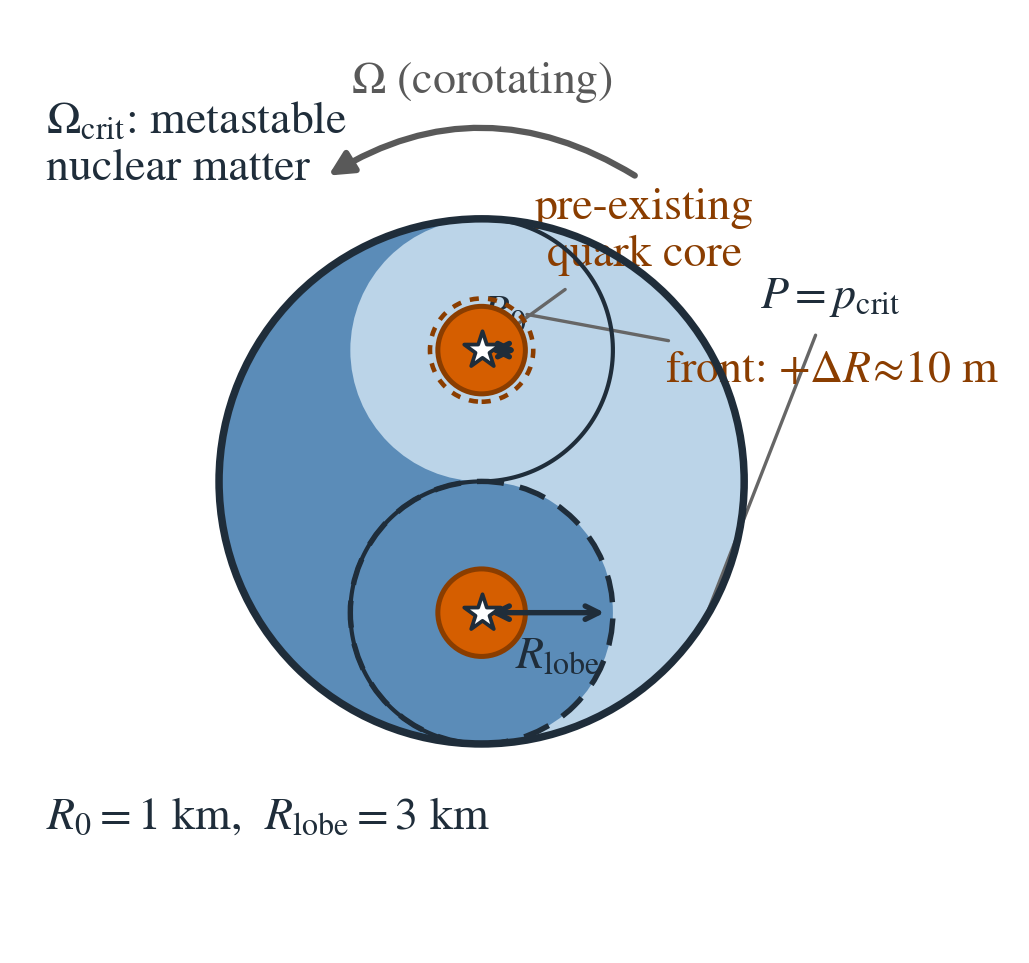

wrote omega_crit_taiji to Latex_writting/Hydrodynamical combustion/Plots, Latex_drop_in_integrated/v2/Plots


In [ ]:
# Omega_crit geometry illustration (2D taiji), pre-existing-core picture:
# R_0 = 1 km cores inside R_lobe = 3 km lobes; front advances ~10 m per window.
# Fonts >= 11 pt at 3.4 in width for 1:1 columnwidth insertion.
# Run from the repo root; writes to both Plots dirs.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Wedge, FancyArrowPatch

# Tunable plotting parameters
FIGURE_SIZE = (3.4, 3.8)
DPI = 300
FONT_FAMILY = "STIXGeneral"
MATH_FONTSET = "stix"
LABEL_FONT_SIZE = 11
ANNOT_FONT_SIZE = 11
R = 1.0                                 # taiji (Omega_crit equatorial) radius, schematic
R0_FRAC = 1.0 / 3.0                     # R_0 / R_lobe = 1 km / 3 km
RLOBE_FIG = 0.5 * R                     # visual lobe radius (= head circle radius)
R0_FIG = R0_FRAC * RLOBE_FIG            # visual pre-existing-core radius
FRONT_EXAG = 1.18                       # exaggeration of the ~1% front growth ring
LOBE_LIGHT = "#BBD4E8"
LOBE_DARK = "#5B8CB8"
OUTLINE_COLOR = "#1F2D3A"
OUTLINE_WIDTH = 1.8
CORE_COLOR = "#D55E00"                  # pre-existing quark core
CORE_EDGE = "#8A3D00"
FRONT_COLOR = "#8A3D00"
RLOBE_RING_COLOR = "#1F2D3A"
SEED_FACE = "#FFFFFF"
SEED_EDGE = "#1F2D3A"
SEED_SIZE = 85
SEED_TOP = (0.0, 0.5 * R)
SEED_BOT = (0.0, -0.5 * R)
ROT_COLOR = "0.35"
ROT_WIDTH = 1.5
DIM_COLOR = "#1F2D3A"
DIM_WIDTH = 1.3
LEADER_COLOR = "0.4"
LEADER_WIDTH = 0.8
AXIS_LIMIT = 1.72
OUTPUT_DIRS = ["Latex_writting/Hydrodynamical combustion/Plots", "Latex_drop_in_integrated/v2/Plots"]
OUTPUT_NAME = "omega_crit_taiji"

plt.rcParams.update({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET})

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=DPI)

# Taiji: base disk light, left half dark, bottom small disk dark, top small disk light.
ax.add_patch(Circle((0, 0), R, facecolor=LOBE_LIGHT, edgecolor="none", zorder=1))
ax.add_patch(Wedge((0, 0), R, 90, 270, facecolor=LOBE_DARK, edgecolor="none", zorder=2))
ax.add_patch(Circle((0, -0.5 * R), 0.5 * R, facecolor=LOBE_DARK, edgecolor="none", zorder=3))
ax.add_patch(Circle((0, 0.5 * R), 0.5 * R, facecolor=LOBE_LIGHT, edgecolor="none", zorder=3))
theta = np.linspace(0, np.pi, 100)
ax.plot(0.5 * R * np.sin(theta), 0.5 * R + 0.5 * R * np.cos(theta),
        color=OUTLINE_COLOR, lw=1.0, zorder=4)
ax.plot(-0.5 * R * np.sin(theta), -0.5 * R - 0.5 * R * np.cos(theta),
        color=OUTLINE_COLOR, lw=1.0, zorder=4)
ax.add_patch(Circle((0, 0), R, facecolor="none", edgecolor=OUTLINE_COLOR,
                    lw=OUTLINE_WIDTH, zorder=5))

# R_lobe indicator ring around the bottom lobe
ax.add_patch(Circle(SEED_BOT, RLOBE_FIG, facecolor="none", edgecolor=RLOBE_RING_COLOR,
                    lw=DIM_WIDTH, ls=(0, (5, 3)), zorder=5))

# Exaggerated front-growth ring around the top core
ax.add_patch(Circle(SEED_TOP, R0_FIG * FRONT_EXAG, facecolor="none", edgecolor=FRONT_COLOR,
                    lw=1.1, ls=(0, (2, 2)), zorder=6))

# Pre-existing quark cores
for c in (SEED_TOP, SEED_BOT):
    ax.add_patch(Circle(c, R0_FIG, facecolor=CORE_COLOR, edgecolor=CORE_EDGE, lw=1.2, zorder=7))
    ax.scatter(*c, marker="*", s=SEED_SIZE, facecolor=SEED_FACE, edgecolor=SEED_EDGE,
               linewidth=0.9, zorder=8)

# R_0 dimension arrow on the top core
ax.add_patch(FancyArrowPatch(SEED_TOP, (R0_FIG, SEED_TOP[1]), arrowstyle="<->",
                             mutation_scale=8, lw=DIM_WIDTH, color=DIM_COLOR, zorder=9))
ax.text(R0_FIG * 0.5, SEED_TOP[1] + 0.055, r"$R_0$", fontsize=ANNOT_FONT_SIZE,
        color=DIM_COLOR, ha="center", va="bottom")
# R_lobe dimension arrow on the bottom lobe
ax.add_patch(FancyArrowPatch(SEED_BOT, (RLOBE_FIG, SEED_BOT[1]), arrowstyle="<->",
                             mutation_scale=8, lw=DIM_WIDTH, color=DIM_COLOR, zorder=9))
ax.text(RLOBE_FIG * 0.58, SEED_BOT[1] - 0.09, r"$R_{\rm lobe}$", fontsize=ANNOT_FONT_SIZE,
        color=DIM_COLOR, ha="center", va="top")

# Corotation arrow
ax.add_patch(FancyArrowPatch(
    (1.30 * R * np.cos(np.deg2rad(62)), 1.30 * R * np.sin(np.deg2rad(62))),
    (1.30 * R * np.cos(np.deg2rad(118)), 1.30 * R * np.sin(np.deg2rad(118))),
    connectionstyle="arc3,rad=0.32", arrowstyle="-|>", mutation_scale=12,
    lw=ROT_WIDTH, color=ROT_COLOR, zorder=6))
ax.text(0, 1.52 * R, r"$\Omega$ (corotating)", fontsize=ANNOT_FONT_SIZE,
        color=ROT_COLOR, ha="center", va="center")

# Labels with leader lines
ax.text(-1.66 * R, 1.28 * R, r"$\Omega_{\rm crit}$: metastable" + "\n" + r"nuclear matter",
        fontsize=LABEL_FONT_SIZE, color=OUTLINE_COLOR, ha="left", va="center")
ax.annotate(r"$P=p_{\rm crit}$", xy=(R * np.cos(np.deg2rad(-32)), R * np.sin(np.deg2rad(-32))),
            xytext=(1.06 * R, 0.70 * R), fontsize=ANNOT_FONT_SIZE, color=OUTLINE_COLOR,
            ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=LEADER_COLOR, lw=LEADER_WIDTH))
ax.annotate("pre-existing\nquark core", xy=SEED_TOP,
            xytext=(0.62 * R, 0.95 * R), fontsize=ANNOT_FONT_SIZE, color=CORE_EDGE,
            ha="center", va="center",
            arrowprops=dict(arrowstyle="-", color=LEADER_COLOR, lw=LEADER_WIDTH))
ax.annotate(r"front: $+\Delta R\!\approx\!10$ m", xy=(R0_FIG * FRONT_EXAG * 0.72, SEED_TOP[1] + R0_FIG * FRONT_EXAG * 0.72),
            xytext=(0.70 * R, 0.42 * R), fontsize=ANNOT_FONT_SIZE, color=FRONT_COLOR,
            ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=LEADER_COLOR, lw=LEADER_WIDTH))
ax.text(-1.66 * R, -1.28 * R, r"$R_0=1$ km,  $R_{\rm lobe}=3$ km",
        fontsize=ANNOT_FONT_SIZE, color=DIM_COLOR, ha="left", va="center")

ax.set_xlim(-AXIS_LIMIT, AXIS_LIMIT)
ax.set_ylim(-AXIS_LIMIT, AXIS_LIMIT)
ax.set_aspect("equal")
ax.axis("off")

fig.tight_layout(pad=0.2)
for d in OUTPUT_DIRS:
    fig.savefig(f"{d}/{OUTPUT_NAME}.pdf"); fig.savefig(f"{d}/{OUTPUT_NAME}.png")
plt.show()
print("wrote " + OUTPUT_NAME + " to " + ", ".join(OUTPUT_DIRS))

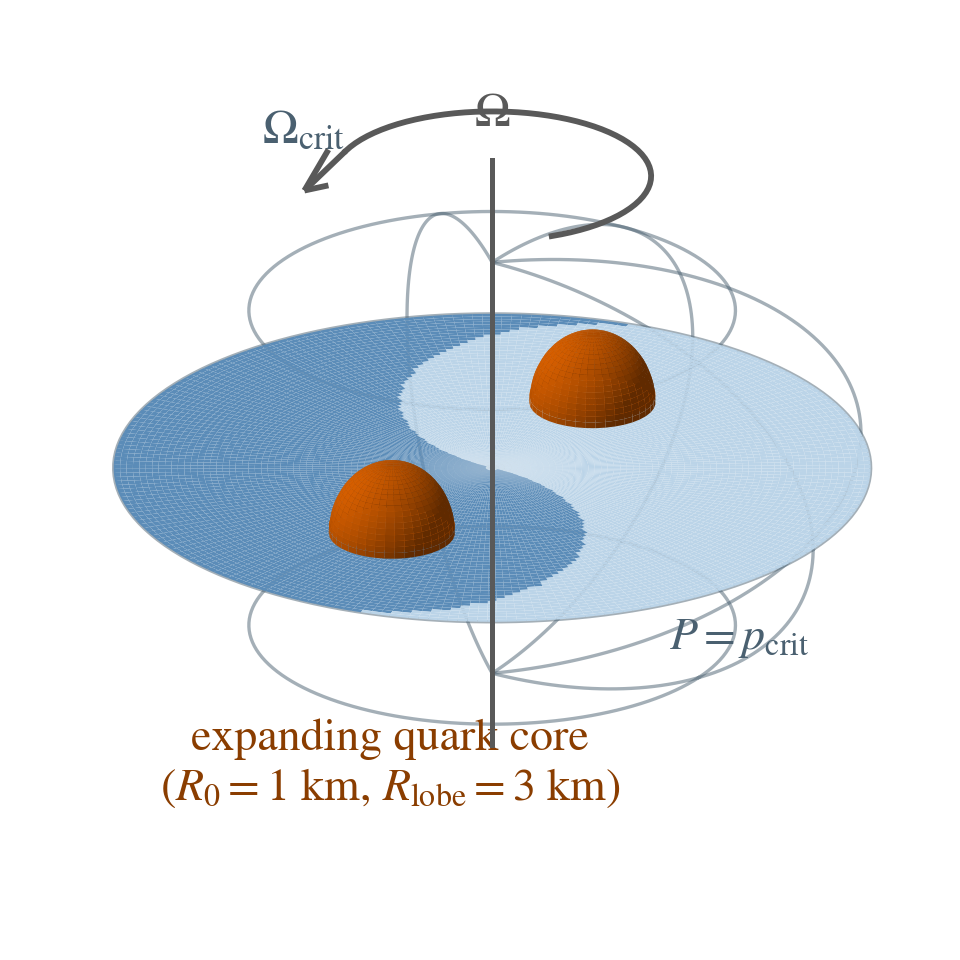

wrote omega_crit_taiji_3d to Latex_writting/Hydrodynamical combustion/Plots, Latex_drop_in_integrated/v2/Plots


In [ ]:
# Omega_crit geometry illustration (3D), pre-existing-core picture: two R_0 = 1 km
# quark-core domes (drawn to scale, R_0/R_lobe = 1/3) inside the oblate p_crit cage.
# Fonts >= 11 pt for 1:1 columnwidth insertion (bbox tight).
# Run from the repo root; writes to both Plots dirs.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba

# Tunable plotting parameters
FIGURE_SIZE = (3.0, 3.0)
DPI = 300
AXES_BOUNDS = (0.0, 0.0, 1.0, 1.0)
PROJECTION_ZOOM = 1.45
SAVE_PADDING_INCHES = 0.01
FONT_FAMILY = "STIXGeneral"
MATH_FONTSET = "stix"
LABEL_FONT_SIZE = 11.5
ANNOT_FONT_SIZE = 11
VIEW_ELEV = 24
VIEW_AZIM = -58
R = 1.0                     # equatorial radius of Omega_crit
C = 0.5 * R                 # polar semi-axis (oblate: C < R)
LOBE_LIGHT = "#BBD4E8"
LOBE_DARK = "#5B8CB8"
SHELL_COLOR = "#4A6070"
SHELL_ALPHA = 0.5
SHELL_WIDTH = 0.8
QUARK_COLOR = "#D55E00"
SEED_COLOR = "#1F2D3A"
R_CONV = 0.5 * R / 3.0      # pre-existing quark-core radius, true scale:
                            # R_0/R_lobe = 1/3 with lobe radius 0.5*R
SEED_TOP = (0.0, 0.5 * R)
SEED_BOT = (0.0, -0.5 * R)
AXIS_COLOR = "0.35"
N_DISK_R = 60
N_DISK_PHI = 240
N_SPHERE = 40
N_SHELL = 22
OUTPUT_DIRS = ["Latex_writting/Hydrodynamical combustion/Plots", "Latex_drop_in_integrated/v2/Plots"]
OUTPUT_NAME = "omega_crit_taiji_3d"

plt.rcParams.update({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET})


def lobe_is_light(x, y):
    """Taiji rule: which lobe (True = light) a point in the equatorial plane is in."""
    top = x**2 + (y - 0.5 * R) ** 2 < (0.5 * R) ** 2
    bot = x**2 + (y + 0.5 * R) ** 2 < (0.5 * R) ** 2
    light = np.where(x >= 0, True, False)   # right half light, left half dark
    light = np.where(top, True, light)      # top small disk -> light
    light = np.where(bot, False, light)     # bottom small disk -> dark
    return light


fig = plt.figure(figsize=FIGURE_SIZE, dpi=DPI)
ax = fig.add_subplot(111, projection="3d")
ax.set_proj_type("ortho")
ax.computed_zorder = False   # honor manual zorder so domes draw over the disk

# Equatorial taiji disk at z = 0
rr = np.linspace(0, R, N_DISK_R)
pp = np.linspace(0, 2 * np.pi, N_DISK_PHI)
Rr, Pp = np.meshgrid(rr, pp)
Xd = Rr * np.cos(Pp)
Yd = Rr * np.sin(Pp)
Zd = np.zeros_like(Xd)
light = lobe_is_light(Xd, Yd)
facecolors = np.where(light[..., None],
                      np.array(to_rgba(LOBE_LIGHT)),
                      np.array(to_rgba(LOBE_DARK)))
ax.plot_surface(Xd, Yd, Zd, facecolors=facecolors, shade=False,
                rstride=1, cstride=1, linewidth=0, antialiased=True, zorder=2)

# Oblate p_crit shell as a sparse cage of rings (boundary without muddying interior)
th = np.linspace(0, np.pi, 120)
for phi0 in np.deg2rad([0, 45, 90, 135]):          # meridians
    ax.plot(R * np.sin(th) * np.cos(phi0), R * np.sin(th) * np.sin(phi0),
            C * np.cos(th), color=SHELL_COLOR, alpha=SHELL_ALPHA,
            lw=SHELL_WIDTH, zorder=1)
phc = np.linspace(0, 2 * np.pi, 160)
for th0 in np.deg2rad([40, 90, 140]):              # latitude rings
    ax.plot(R * np.sin(th0) * np.cos(phc), R * np.sin(th0) * np.sin(phc),
            C * np.cos(th0) * np.ones_like(phc), color=SHELL_COLOR,
            alpha=SHELL_ALPHA, lw=SHELL_WIDTH, zorder=1)

# Converted quark region: red equatorial slice + shaded upper dome. The dome
# sits entirely above z=0, so it never intersects the disk (avoids mplot3d's
# occlusion bug) yet reads as a sphere half-embedded in the equatorial cut.
uu = np.linspace(0, 2 * np.pi, N_SPHERE)
vv = np.linspace(0, np.pi / 2, N_SPHERE // 2)     # upper hemisphere only
nx = np.outer(np.cos(uu), np.sin(vv))
ny = np.outer(np.sin(uu), np.sin(vv))
nz = np.outer(np.ones_like(uu), np.cos(vv))
light = np.array([-0.5, -0.4, 0.77])
light = light / np.linalg.norm(light)
intensity = np.clip(nx * light[0] + ny * light[1] + nz * light[2], 0, 1)
shade = 0.45 + 0.55 * intensity
base = np.array(to_rgba(QUARK_COLOR))
dome_colors = np.empty(nx.shape + (4,))
dome_colors[..., :3] = base[:3] * shade[..., None]
dome_colors[..., 3] = 1.0
rs = np.linspace(0, R_CONV, 8)
ps = np.linspace(0, 2 * np.pi, N_SPHERE)
Rs, Ps = np.meshgrid(rs, ps)
Xsl, Ysl = Rs * np.cos(Ps), Rs * np.sin(Ps)
for (cx, cy) in (SEED_TOP, SEED_BOT):
    ax.plot_surface(Xsl + cx, Ysl + cy, np.full_like(Xsl, 0.02), color=QUARK_COLOR,
                    shade=False, rstride=1, cstride=1, linewidth=0, zorder=4)
    ax.plot_surface(R_CONV * nx + cx, R_CONV * ny + cy, R_CONV * nz,
                    facecolors=dome_colors, shade=False, rstride=1, cstride=1,
                    linewidth=0, antialiased=True, zorder=6)
#ax.scatter([SEED_TOP[0]], [SEED_TOP[1]], [R_CONV], color=SEED_COLOR, marker="*",
#           s=70, depthshade=False, zorder=7)

# Rotation axis and Omega arrow
ax.plot([0, 0], [0, 0], [-1.35 * C, 1.5 * C], color=AXIS_COLOR, lw=1.2, zorder=4)
arc = np.linspace(-0.2 * np.pi, 1.05 * np.pi, 60)
ax.plot(0.42 * R * np.cos(arc), 0.42 * R * np.sin(arc),
        1.42 * C * np.ones_like(arc), color=AXIS_COLOR, lw=1.4, zorder=6)
ax.quiver(0.42 * R * np.cos(arc[-1]), 0.42 * R * np.sin(arc[-1]), 1.42 * C,
          -np.sin(arc[-1]), np.cos(arc[-1]), 0, length=0.28, color=AXIS_COLOR,
          arrow_length_ratio=0.6, lw=1.4, zorder=6)
ax.text(0, 0, 1.72 * C, r"$\Omega$", fontsize=LABEL_FONT_SIZE, color=AXIS_COLOR,
        ha="center", va="center")

# Labels
ax.text(-1.15 * R, 0.9 * R, 0.55 * C, r"$\Omega_{\rm crit}$", fontsize=LABEL_FONT_SIZE,
        color=SHELL_COLOR, ha="center")
ax.text(1.02 * R, -0.75 * R, 0.0, r"$P=p_{\rm crit}$", fontsize=ANNOT_FONT_SIZE,
        color=SHELL_COLOR, ha="left")
ax.text(SEED_BOT[0] + 0.15, SEED_BOT[1] - 0.25, -1.08 * C,
        "expanding quark core\n($R_0=1$ km, $R_{\\rm lobe}=3$ km)",
        fontsize=ANNOT_FONT_SIZE, color="#8A3D00", ha="center")
#ax.text(SEED_TOP[0] - 0.1, SEED_TOP[1] + 0.34, 0.55 * C, "seed:\npressure max",
#        fontsize=ANNOT_FONT_SIZE, color=SEED_COLOR, ha="center")

ax.view_init(elev=VIEW_ELEV, azim=VIEW_AZIM)
ax.set_box_aspect((1, 1, 0.62), zoom=PROJECTION_ZOOM)
ax.set_xlim(-1.15 * R, 1.15 * R)
ax.set_ylim(-1.15 * R, 1.15 * R)
ax.set_zlim(-1.2 * C, 1.2 * C)
ax.set_axis_off()

ax.set_position(AXES_BOUNDS)
for d in OUTPUT_DIRS:
    fig.savefig(f"{d}/{OUTPUT_NAME}.pdf", bbox_inches="tight", pad_inches=SAVE_PADDING_INCHES)
    fig.savefig(f"{d}/{OUTPUT_NAME}.png", bbox_inches="tight", pad_inches=SAVE_PADDING_INCHES)
plt.show()
print("wrote " + OUTPUT_NAME + " to " + ", ".join(OUTPUT_DIRS))